# Ordinary Kriging - Lagunazo Mine Waste (ICP geochemistry)

## 1 · Imports & Configuration

In [1]:
import os, re, io, json, time, math, zipfile, hashlib, platform, warnings
import xml.etree.ElementTree as ET
from datetime import datetime, timezone
from pathlib import Path
from IPython.display import display, HTML
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import scipy
import openpyxl
from scipy.spatial import cKDTree
from scipy import stats
from scipy.optimize import curve_fit

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patheffects as mpe
import matplotlib.gridspec as gridspec
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch, Rectangle, PathPatch
from matplotlib.lines import Line2D
from matplotlib.path import Path as MPath

try:
    import seaborn as sns
    SNS_OK = True
except ImportError:
    sns, SNS_OK = None, False
try:
    import contextily as ctx
    CTX_OK = True
except ImportError:
    ctx, CTX_OK = None, False
    print("warning: contextily not found - basemap disabled (pip install contextily).")
try:
    import pyproj
    from pyproj import Transformer
except ImportError:
    raise ImportError("pyproj is required for the WGS 84 -> UTM 29N projection (pip install pyproj).")
try:
    import shapely
    from shapely.geometry import Polygon as ShapelyPolygon, MultiPoint, Point
    SHAPELY_OK = True
except ImportError:
    shapely, SHAPELY_OK = None, False
    print("warning: shapely not found - polygon handling falls back to matplotlib (pip install shapely).")
# pandas' Styler (.style) needs a recent jinja2; test it through pandas itself (an old jinja2 imports fine
# but pandas still refuses .style). Without it, tables are shown as plain HTML.
try:
    pd.DataFrame({"a": [1]}).style.to_html()
    JINJA_OK = True
except Exception:
    JINJA_OK = False
    print("note: pandas table styling unavailable (jinja2 missing or too old) - tables are shown as plain HTML.")

matplotlib.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 400, "figure.facecolor": "white", "axes.facecolor": "white",
    "font.family": "DejaVu Sans", "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "axes.linewidth": 1.0, "xtick.direction": "in", "ytick.direction": "in"})

# Input files
ICP_XLSX   = "ICP-DATA_2026.xlsx"          # laboratory Final Report workbook
SHEET_DATA = "Analytical Data"
SHEET_QC   = "QC Data"
SHEET_LOC  = "Locations"
KMZ_FILE   = "Lagunazo_waste_area.kmz"     # mine-waste boundary polygon (same file as the pXRF notebooks)
OUT_DIR    = "results_OK_ICP"

# Elements
ELEMENTS   = None     # None = every CRM analyte eligible in Section 5 | "Bi" | ["Sb", "Bi", "Cu"]
VAR_NAME   = "Bi"     # element whose figures and audit are shown in full inside the notebook
EPSG_UTM   = "EPSG:32629"

# Sample-ID reconciliation
LAB_TO_FIELD_PREFIX = {"LA": "LG"}
LOCATION_ID_FIXES = [
    dict(no=13, recorded="LG-35-31", corrected="LG-25-31", kind="typo",
         reason="year field '35' is a typo; point lies in the LG-25-33 -> 31 -> 29 field sequence"),
    dict(no=23, recorded="LH-25-06", corrected="LG-25-06", kind="typo",
         reason="prefix 'LH' is a typo; point lies in the LG-25-07 -> 06 -> 05 field sequence"),
    dict(no=29, recorded="LG-25-34", corrected="LG-25-24", kind="inferred",
         reason="LG-25-34 is recorded twice (No. 29 and No. 44) and LG-25-24 is otherwise missing; "
                "No. 29 lies between LG-25-25 and LG-25-23 in the field sequence"),
]
APPLY_INFERRED_FIXES = True

# Censored assays and eligibility
BDL_FACTOR     = 0.5    # "<MDL" -> BDL_FACTOR x MDL
ODL_FACTOR     = 1.0    # ">UDL" -> the upper limit (a LOWER BOUND - flagged everywhere)
MIN_QUANT_FRAC = 0.15   # min. fraction of located samples quantified (was 0.70; lowered so that every CRM with a
                        # spatial signal is mapped - censored stations form the '<MDL' map class)
MIN_QUANT_FRAC_STRICT = 0.70   # below this detected share a map is flagged as censored ('<MDL' class shown)
MIN_DETECTED_N = 5      # min. number of located detections (> MDL); below it (Be 1, Pd 0, Ta 0) -> detection map only
MIN_N_MAP      = 15     # min. number of located samples

# Stage 1 screening
STATION_TOL_M     = 5.0
MIN_STATIONS      = 10
MIN_PAIRS_TOTAL   = 45
MIN_DISTINCT_VALS = 3   # was 5; heavily censored elements (B, Pt) have 3-4 distinct values incl. 1/2 MDL
ADVISORY_STATIONS = 30

# Stage 2 transform, variogram, models
TRANSFORM_CANDIDATES   = ["none", "log", "nscore"]
TRANSFORM_MIN_GAIN_PCT = 2.0         # a transform must beat "none" (RMSE in grade units) by this much
LOG_BACKTRANSFORM      = "journel"   # "journel": exp(y+s2/2-mu)-c (OK form) | "naive": exp(y+s2/2)-c | "median"
NSCORE_BACKTRANSFORM   = "expectation"   # "expectation" (Gauss-Hermite over N(y*, s2)) | "median" (table look-up)
NSCORE_UPPER_OMEGA     = 1.5    # GSLIB hyperbolic upper tail beyond the largest datum
NSCORE_ZMAX_FACTOR     = 2.0    # ... capped at this multiple of the largest datum (lower tail: linear to 0)
GH_NODES               = 24
N_BOOT                 = 2000   # bootstrap resamples for the uncertainty of the nested R2
MARGINAL_P             = 0.25   # a surface is flagged 'marginal' if bootstrap P(R2 < MIN_R2_SURFACE) >= this
N_LAGS_MAX     = 15
MIN_PAIRS_LAG  = 30
CUTOFF_FACTOR  = 0.50                # x the largest station separation
RMSSE_PENALTY     = 0.15
SELECTION_TOL_PCT = 2.0
GAUSSIAN_MIN_NUGGET_FRAC = 1e-3
MODEL_PREFERENCE = ["Nugget", "Spherical", "Exponential", "Cubic", "Gaussian"]   # tie-break: simplest first

# Kriging neighbourhood
K_NEIGHBORS          = 16
MIN_NEIGHBORS        = 6
SEARCH_RADIUS_FACTOR = 1.6           # radius = max(1.6 x range, 5 x median station spacing)
MAX_COND_NUMBER      = 1e12
K_SENSITIVITY        = [8, 16, 24, None]   # audit: None = unique neighbourhood (all stations)

# Grid & display
GRID_DENSITY_M = 3.0    # identical grid to the IDW notebook -> co-registered rasters
PAD_FRAC       = 0.06
BASEMAP_ALPHA  = 0.70   # r10
SURFACE_ALPHA  = 0.82   # r10
CLASS_SCHEME       = "equal"     # VAR_NAME maps: rounded equal intervals (r8 standard) | "quantile"
ATLAS_CLASS_SCHEME = "quantile"  # other elements and the atlas: station percentiles P0-10-25-50-75-90-95-100
N_GRADE_CLASSES, N_SE_CLASSES = 7, 6
GRADE_CMAP, SE_CMAP, RESID_CMAP = "turbo", "magma_r", "RdBu_r"
HATCH_EXTRAP   = True   # hatch ground farther from any station than the largest nearest-neighbour distance
MIN_R2_SURFACE = 0.10   # reliability threshold on the NESTED-CV R2: >= this 'predictive', 0-this 'weak', < 0 'no skill'
MAP_ALL_SURFACES = True # True: map EVERY kriged CRM as a surface with its reliability label; False: posted values
                        # below MIN_R2_SURFACE (previous behaviour)
CENSORED_CLASS = True   # lowest map class = '<MDL' (grey) for elements with stations below detection
DETECTION_MAP_PNG = os.path.join(OUT_DIR, "ICP_CRM_detection_maps_UTM29N.png")
SAVE_ELEMENT_FIGURES = True

if not Path(ICP_XLSX).exists():
    raise FileNotFoundError(f"'{ICP_XLSX}' not found in {Path.cwd()} - place the laboratory workbook next to this notebook.")
os.makedirs(OUT_DIR, exist_ok=True)
RUN_STARTED = datetime.now(timezone.utc).isoformat(timespec="seconds")
print("Configuration loaded.")
print(f"  Workbook : {ICP_XLSX}   |   outputs -> {OUT_DIR}/")
print(f"  Elements : {'all eligible CRM analytes' if ELEMENTS is None else ELEMENTS}   |   detail element: {VAR_NAME}")
print(f"  Kriging  : K={K_NEIGHBORS}, min {MIN_NEIGHBORS}, radius = max({SEARCH_RADIUS_FACTOR} x range, 5 x spacing)")
print(f"  Transforms {TRANSFORM_CANDIDATES}, log back-transform '{LOG_BACKTRANSFORM}', nscore '{NSCORE_BACKTRANSFORM}'")

note: pandas table styling unavailable (jinja2 missing or too old) - tables are shown as plain HTML.
Configuration loaded.
  Workbook : ICP-DATA_2026.xlsx   |   outputs -> results_OK_ICP/
  Elements : all eligible CRM analytes   |   detail element: Bi
  Kriging  : K=16, min 6, radius = max(1.6 x range, 5 x spacing)
  Transforms ['none', 'log', 'nscore'], log back-transform 'journel', nscore 'expectation'


## 2 · Core Routines

Stations, declustering and metrics are the same as in the IDW notebook. The kriging engine follows.

**Ordinary kriging system** (covariance form, normalised by the sill for conditioning):
`Σ_j λ_j C(x_i, x_j) + ν = C(x_i, x_0)`, `Σ λ_j = 1`; variance `σ² = C(0) − Σ λ_i C(x_i, x_0) − ν`.
In the semivariogram form used by r10 the Lagrange multiplier is `μ = −ν`, so Journel's lognormal back-transform
reads `exp(y* + σ²/2 − μ)`. The grid and the cross-validation use one batched solver with the same neighbourhood
rule: the `K` nearest stations inside the search radius, or the `MIN_NEIGHBORS` nearest if fewer lie inside it.

In [2]:
# tables
_STATUS_CSS = {"PASS": "background-color:#eafaf1;color:#1e8449;font-weight:bold",
               "WARN": "background-color:#fef9e7;color:#b7950b;font-weight:bold",
               "FAIL": "background-color:#fdedec;color:#922b21;font-weight:bold",
               "INFO": "background-color:#eaf2f8;color:#1a5276;font-weight:bold"}

def show_table(df, precision=None, status_col=None):
    """Display a DataFrame without its index; Styler when available, plain HTML otherwise."""
    if JINJA_OK:
        try:
            sty = df.style
            if precision is not None:
                sty = sty.format(precision=precision, thousands=",")
            if status_col is not None:
                colour = sty.map if hasattr(sty, "map") else sty.applymap
                sty = colour(lambda v: _STATUS_CSS.get(v, ""), subset=[status_col])
            display(sty.hide(axis="index"))
            return
        except Exception:
            pass
    d = df.copy()
    if precision is not None:
        num = d.select_dtypes("number").columns
        d[num] = d[num].round(precision)
    html = d.to_html(index=False, na_rep="", escape=True)
    if status_col is not None:
        for key, css in _STATUS_CSS.items():
            html = html.replace(f"<td>{key}</td>", f'<td style="{css}">{key}</td>')
    display(HTML(html))


# stations
def station_means(df, x_col, y_col, var, tol_m=5.0, id_col=None, flag_col=None):
    """Collapse replicates within tol_m (single linkage) to one station; returns (stations, report)."""
    d = df.copy()
    for c in (x_col, y_col, var):
        d[c] = pd.to_numeric(d[c], errors="coerce")
    d = d.replace([np.inf, -np.inf], np.nan).dropna(subset=[x_col, y_col, var]).reset_index(drop=True)
    xy = d[[x_col, y_col]].to_numpy(float)
    parent = np.arange(len(d))

    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a

    for a, b in cKDTree(xy).query_pairs(r=max(tol_m, 1e-9)):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[rb] = ra
    d["_station"] = [find(i) for i in range(len(d))]
    agg = {x_col: (x_col, "mean"), y_col: (y_col, "mean"), var: (var, "mean"),
           "n_reps": (var, "size"), "rep_sd": (var, "std")}
    if id_col:
        agg[id_col] = (id_col, lambda s: "+".join(map(str, s)))
    if flag_col:
        agg[flag_col] = (flag_col, lambda s: ",".join(sorted(set(map(str, s)))))
    out = d.groupby("_station").agg(**agg).reset_index(drop=True)
    rep = dict(n_measurements=int(len(d)), n_stations=int(len(out)),
               n_stations_with_reps=int((out["n_reps"] > 1).sum()),
               median_rep_sd=float(out.loc[out["n_reps"] > 1, "rep_sd"].median())
               if (out["n_reps"] > 1).any() else np.nan)
    return out.drop(columns=["rep_sd"]), rep


# declustering
def declustering_weights(coords, values, cell_sizes=None, n_origins=12, target="min_mean", seed=0):
    """Cell declustering (GSLIB declus): origin-averaged weights (mean 1) at the cell size that minimises
    (or maximises) the declustered mean. Returns (weights, cell_size_m, table)."""
    coords, v = np.asarray(coords, float), np.asarray(values, float)
    n = len(v)
    if n < 3:
        return np.ones(n), np.nan, pd.DataFrame()
    if cell_sizes is None:
        nn = float(np.median(cKDTree(coords).query(coords, k=2)[0][:, 1]))
        ext = float(max(np.ptp(coords[:, 0]), np.ptp(coords[:, 1])))
        cell_sizes = np.unique(np.round(np.linspace(max(nn, 1.0), max(ext / 2.0, nn * 1.01), 24), 1))
    rng = np.random.default_rng(seed)
    x0, y0 = coords[:, 0].min(), coords[:, 1].min()
    rows, W = [], {}
    for cs in cell_sizes:
        acc = np.zeros(n)
        for o in range(n_origins):
            ox, oy = (0.0, 0.0) if o == 0 else (rng.uniform(0, cs), rng.uniform(0, cs))
            ix = np.floor((coords[:, 0] - x0 + ox) / cs).astype(np.int64)
            iy = np.floor((coords[:, 1] - y0 + oy) / cs).astype(np.int64)
            _, inv, cnt = np.unique(np.column_stack([ix, iy]), axis=0, return_inverse=True, return_counts=True)
            w = 1.0 / cnt[np.asarray(inv).ravel()]
            acc += w * n / w.sum()
        w = acc / n_origins
        w *= n / w.sum()
        W[float(cs)] = w
        rows.append((float(cs), float(np.sum(w * v) / n)))
    tab = pd.DataFrame(rows, columns=["cell_size_m", "declustered_mean"])
    i = tab["declustered_mean"].idxmin() if target == "min_mean" else tab["declustered_mean"].idxmax()
    cs = float(tab.loc[i, "cell_size_m"])
    return W[cs], cs, tab


# metrics
def metrics(y_true, y_pred, label=""):
    """Cross-validation statistics in grade units."""
    yt, yp = np.asarray(y_true, float), np.asarray(y_pred, float)
    ok = np.isfinite(yt) & np.isfinite(yp)
    yt, yp = yt[ok], yp[ok]
    if yt.size < 2:
        return {}
    res = yp - yt
    ss_tot = float(np.sum((yt - yt.mean()) ** 2))
    rmse = float(np.sqrt(np.mean(res ** 2)))
    good = np.std(yt) > 0 and np.std(yp) > 0
    return dict(
        Label=label, n=int(yt.size), RMSE=rmse, MAE=float(np.mean(np.abs(res))), ME_bias=float(res.mean()),
        Rel_bias_pct=float(100 * res.mean() / yt.mean()) if yt.mean() else np.nan,
        Rel_RMSE_pct=float(100 * rmse / yt.mean()) if yt.mean() else np.nan,
        R2_pred=float(1 - np.sum(res ** 2) / ss_tot) if ss_tot > 0 else np.nan,
        Pearson_r=float(np.corrcoef(yt, yp)[0, 1]) if good else np.nan,
        Spearman_r=float(stats.spearmanr(yt, yp)[0]),
        Slope_obs_on_pred=float(stats.linregress(yp, yt)[0]) if good else np.nan,   # conditional bias, ideal 1
        Reg_slope=float(stats.linregress(yt, yp)[0]) if good else np.nan,           # smoothing
        Obs_min=float(yt.min()), Obs_max=float(yt.max()), Est_min=float(yp.min()), Est_max=float(yp.max()),
        Var_ratio=float(np.var(yp, ddof=1) / np.var(yt, ddof=1)) if np.var(yt) > 0 else np.nan)

print("Tables, stations, declustering and metrics loaded.")

Tables, stations, declustering and metrics loaded.


In [3]:
# variogram models 
# Practical-range parameterisation (the model reaches ~95 % (exp, gau) or 100 % (sph, cub) of the sill at `rng`).
def _sph(h, a):
    r = np.minimum(h / a, 1.0)
    return 1.5 * r - 0.5 * r ** 3

def _exp(h, a):
    return 1.0 - np.exp(-3.0 * h / a)

def _gau(h, a):
    return 1.0 - np.exp(-3.0 * (h / a) ** 2)

def _cub(h, a):
    r = np.minimum(h / a, 1.0)
    return 7 * r ** 2 - 8.75 * r ** 3 + 3.5 * r ** 5 - 0.75 * r ** 7

SHAPES = {"Spherical": _sph, "Exponential": _exp, "Gaussian": _gau, "Cubic": _cub}


class VModel:
    """Nugget + one structure. gamma(0) = 0 (the nugget is a discontinuity at the origin)."""

    def __init__(self, name, nugget, psill, rng):
        self.name, self.nugget, self.psill, self.rng = name, float(nugget), float(psill), float(rng)

    @property
    def sill(self):
        return self.nugget + self.psill

    def gamma(self, h):
        h = np.asarray(h, float)
        g = np.full(h.shape, self.nugget)
        if self.name != "Nugget":
            g = g + self.psill * SHAPES[self.name](h, self.rng)
        return np.where(h <= 1e-9, 0.0, g)

    def rho(self, h):
        """Covariance normalised by the sill: 1 at h = 0."""
        return 1.0 - self.gamma(h) / self.sill

    def __repr__(self):
        return (f"{self.name}(nugget={self.nugget:.4g}, psill={self.psill:.4g}, "
                + ("" if self.name == "Nugget" else f"range={self.rng:.1f} m, ") + f"N:S={self.nugget / self.sill:.2f})")


def experimental_variogram(coords, y, cutoff, min_pairs=MIN_PAIRS_LAG, n_lags_max=N_LAGS_MAX):
    """Omnidirectional semivariogram with EQUAL-COUNT lags: every lag holds >= min_pairs pairs by construction.
    Returns DataFrame(lag, h_mean, h_min, h_max, gamma, n_pairs)."""
    coords, y = np.asarray(coords, float), np.asarray(y, float)
    iu = np.triu_indices(len(y), k=1)
    h = np.hypot(coords[iu[0], 0] - coords[iu[1], 0], coords[iu[0], 1] - coords[iu[1], 1])
    g = 0.5 * (y[iu[0]] - y[iu[1]]) ** 2
    keep = (h > 0) & (h <= cutoff)
    h, g = h[keep], g[keep]
    n_lags = int(min(n_lags_max, h.size // max(min_pairs, 1)))
    if n_lags < 1:
        return pd.DataFrame(columns=["lag", "h_mean", "h_min", "h_max", "gamma", "n_pairs"])
    order = np.argsort(h, kind="mergesort")
    rows = []
    for i, s in enumerate(np.array_split(order, n_lags)):
        rows.append((i + 1, h[s].mean(), h[s].min(), h[s].max(), g[s].mean(), s.size))
    return pd.DataFrame(rows, columns=["lag", "h_mean", "h_min", "h_max", "gamma", "n_pairs"])


def fit_models(vgm, cutoff):
    """Weighted least squares (weights = pair counts; with equal-count lags these are near-equal, so the fit is
    effectively unweighted) for four structured models + the pure-nugget benchmark.
    Parameterised as nugget + PARTIAL sill so both are >= 0. Returns list of (VModel, bound_hits, wrss)."""
    xf, yf, wf = (vgm[c].to_numpy(float) for c in ("h_mean", "gamma", "n_pairs"))
    gmax = float(yf.max())
    nug_hi, ps_hi = max(1.05 * gmax, 1e-12), max(1.5 * gmax, 1e-12)
    r_lo = float(max(0.5 * xf.min(), 1.0))
    r_hi = float(max(1.5 * cutoff, 4 * r_lo))
    nug0 = float(np.clip(min(yf[0], np.percentile(yf, 25)), 0.0, nug_hi))
    ps0 = float(np.clip(max(np.median(yf[-3:]) - nug0, 0.05 * gmax), 0.0, ps_hi))
    rg0 = float(np.clip(0.4 * xf.max(), r_lo, r_hi))
    sigma = 1.0 / np.sqrt(np.maximum(wf, 1e-9))
    out = []
    for name, shape in SHAPES.items():
        lo, hi = [0.0, 0.0, r_lo], [nug_hi, ps_hi, r_hi]
        if name == "Gaussian":
            lo[0] = GAUSSIAN_MIN_NUGGET_FRAC * gmax          # a zero-nugget Gaussian is numerically singular
        p0 = [float(np.clip(v, l_, h_)) for v, l_, h_ in zip([nug0, ps0, rg0], lo, hi)]
        try:
            popt, _ = curve_fit(lambda h, c0, c, a: c0 + c * shape(h, a), xf, yf, p0=p0, sigma=sigma,
                                bounds=(lo, hi), maxfev=200000)
        except (RuntimeError, ValueError):
            continue
        hits = [nm for nm, v, l_, h_ in zip(("nugget", "psill", "range"), popt, lo, hi)
                if (h_ - l_) > 0 and (abs(v - l_) <= 1e-2 * (h_ - l_) or abs(h_ - v) <= 1e-2 * (h_ - l_))
                and not (nm == "nugget" and v <= lo[0] + 1e-12 and name != "Gaussian")]
        m = VModel(name, *popt)
        out.append((m, hits, float(np.sum(wf * (m.gamma(xf) - yf) ** 2))))
    c0 = float(np.average(yf, weights=wf))
    m = VModel("Nugget", c0, 0.0, cutoff)
    out.append((m, [], float(np.sum(wf * (c0 - yf) ** 2))))
    return out

print("Variogram models and fitting loaded.")

Variogram models and fitting loaded.


In [4]:
# ordinary kriging engine 
def _select_neighbours(d, ix, K, min_k, radius):
    """d, ix sorted by distance. Use the neighbours inside `radius` (at most K); if fewer than min_k are inside,
    use the min_k nearest (extended). The used set is always a prefix of the sorted list."""
    within = d <= radius
    n_in = within.sum(axis=1)
    m = np.where(n_in >= min_k, np.minimum(n_in, K), np.minimum(min_k, d.shape[1]))
    return m.astype(int), n_in < min_k


def ok_batch(targets, coords, y, model, K=K_NEIGHBORS, min_k=MIN_NEIGHBORS, radius=np.inf,
             exclude_self=False, chunk=4000):
    """Batched ordinary kriging at `targets`. With exclude_self=True the targets are the stations themselves
    and each is kriged from the others (leave-one-out).
    Returns dict(est, var, mu, n_used, extended, cond_max)."""
    coords, y = np.asarray(coords, float), np.asarray(y, float)
    targets = np.atleast_2d(np.asarray(targets, float))
    n, T = len(y), len(targets)
    Kq = int(min(K if K else n, n - (1 if exclude_self else 0)))
    kq = Kq + (1 if exclude_self else 0)
    d, ix = cKDTree(coords).query(targets, k=kq)
    d, ix = np.asarray(d).reshape(T, kq), np.asarray(ix).reshape(T, kq)
    if exclude_self:
        selfc = ix == np.arange(T)[:, None]
        selfc[~selfc.any(axis=1), -1] = True
        d, ix = d[~selfc].reshape(T, Kq), ix[~selfc].reshape(T, Kq)
    m_used, extended = _select_neighbours(d, ix, Kq, min(min_k, Kq), radius)
    est, var, mu = np.full(T, np.nan), np.full(T, np.nan), np.full(T, np.nan)
    cond_max = 0.0
    for m in np.unique(m_used):
        rows = np.flatnonzero(m_used == m)
        for s in range(0, rows.size, chunk):
            R = rows[s:s + chunk]
            I = ix[R, :m]
            P = coords[I]                                               # (g, m, 2)
            D = np.hypot(P[:, :, None, 0] - P[:, None, :, 0], P[:, :, None, 1] - P[:, None, :, 1])
            A = np.zeros((R.size, m + 1, m + 1))
            A[:, :m, :m] = model.rho(D)
            A[:, :m, m] = 1.0
            A[:, m, :m] = 1.0
            b = np.ones((R.size, m + 1))
            b[:, :m] = model.rho(d[R, :m])
            try:
                sol = np.linalg.solve(A, b[..., None])[..., 0]
            except np.linalg.LinAlgError:
                sol = np.stack([np.linalg.lstsq(A[j], b[j], rcond=None)[0] for j in range(R.size)])
            lam, nu = sol[:, :m], sol[:, m]
            est[R] = np.sum(lam * y[I], axis=1)
            var[R] = model.sill * np.maximum(1.0 - np.sum(lam * b[:, :m], axis=1) - nu, 0.0)
            mu[R] = -model.sill * nu                                    # semivariogram-form multiplier
            if R.size <= 64 or s == 0:
                cond_max = max(cond_max, float(np.max(np.linalg.cond(A[:64]))))
    return dict(est=est, var=var, mu=mu, n_used=m_used, extended=extended, cond_max=cond_max)


def ok_point_gamma(pt, coords, y, model, K=K_NEIGHBORS, min_k=MIN_NEIGHBORS, radius=np.inf):
    """Independent reference solver for ONE target in the SEMIVARIOGRAM form
    [Gamma 1; 1' 0][lambda; mu] = [gamma0; 1], sigma2 = lambda.gamma0 + mu. Used only in the audit."""
    dd = np.hypot(coords[:, 0] - pt[0], coords[:, 1] - pt[1])
    order = np.argsort(dd, kind="mergesort")[:min(K if K else len(y), len(y))]
    inside = order[dd[order] <= radius]
    use = inside[:K] if inside.size >= min_k else order[:min_k]
    P = coords[use]
    G = model.gamma(np.hypot(P[:, None, 0] - P[None, :, 0], P[:, None, 1] - P[None, :, 1]))
    m = len(use)
    A = np.zeros((m + 1, m + 1)); A[:m, :m] = G; A[:m, m] = 1; A[m, :m] = 1
    g0 = model.gamma(dd[use])
    sol = np.linalg.solve(A, np.append(g0, 1.0))
    lam, mu_g = sol[:m], sol[m]
    return float(lam @ y[use]), float(lam @ g0 + mu_g), float(mu_g), lam, use


def search_radius_for(model, spacing):
    return float(max(model.rng * SEARCH_RADIUS_FACTOR, 5.0 * spacing))

print("Ordinary kriging engine loaded.")

Ordinary kriging engine loaded.


In [5]:
# transforms
class Transform:
    """none | log | nscore with explicit, documented back-transforms of a KRIGED value.

    log    : y = ln(z + c). Back: 'journel' exp(y + s2/2 - mu) - c (ordinary-kriging lognormal correction,
             Journel & Huijbregts 1978); 'naive' exp(y + s2/2) - c (simple-kriging form; biased high under OK);
             'median' exp(y) - c. Approximate prediction SD in grade units: (z* + c) sqrt(exp(s2) - 1).
    nscore : y = Phi^-1(F_w(z)) with F_w the DECLUSTERED cdf, ties sharing one score (mid-point of their
             cumulative weight). Back: 'expectation' = E[F^-1(Phi(Y))], Y ~ N(y*, s2), by Gauss-Hermite
             quadrature (the conditional mean under a multiGaussian model, with the OK variance standing in for
             the simple-kriging variance); 'median' = table look-up of y*. Tails (GSLIB backtr): linear in the
             cdf from 0 to the smallest datum, hyperbolic (omega) above the largest datum, capped at
             NSCORE_ZMAX_FACTOR x the largest datum."""

    def __init__(self, kind="none", log_mode=LOG_BACKTRANSFORM, ns_mode=NSCORE_BACKTRANSFORM, gh=GH_NODES):
        self.kind, self.log_mode, self.ns_mode = kind, log_mode, ns_mode
        t, w = np.polynomial.hermite_e.hermegauss(gh)
        self._t, self._w = t, w / w.sum()
        self.c = 0.0

    def fit(self, z, w=None):
        z = np.asarray(z, float)
        if self.kind == "log":
            self.c = 0.0 if z.min() > 0 else abs(z.min()) + 1e-6 * (np.ptp(z) or 1.0)
        elif self.kind == "nscore":
            w = np.ones_like(z) if w is None else np.asarray(w, float)
            zs, inv = np.unique(z, return_inverse=True)
            wsum = np.bincount(np.asarray(inv).ravel(), weights=w)
            cw = np.cumsum(wsum)
            p = (cw - 0.5 * wsum) / cw[-1]
            self._zs, self._ys = zs, stats.norm.ppf(p)
        return self

    def forward(self, z):
        z = np.asarray(z, float)
        if self.kind == "log":
            return np.log(z + self.c)
        if self.kind == "nscore":
            return np.interp(z, self._zs, self._ys)
        return z

    def _ns_back(self, y):
        y = np.asarray(y, float)
        z = np.interp(y, self._ys, self._zs)
        lo, hi = y < self._ys[0], y > self._ys[-1]
        if lo.any():                                      # linear in the cdf down to z = 0
            z[lo] = self._zs[0] * stats.norm.cdf(y[lo]) / stats.norm.cdf(self._ys[0])
        if hi.any():                                      # hyperbolic upper tail, capped
            ratio = stats.norm.sf(self._ys[-1]) / np.maximum(stats.norm.sf(y[hi]), 1e-300)
            z[hi] = np.minimum(self._zs[-1] * ratio ** (1.0 / NSCORE_UPPER_OMEGA),
                               NSCORE_ZMAX_FACTOR * self._zs[-1])
        return z

    def back(self, y, var=None, mu=None):
        y = np.asarray(y, float)
        if self.kind == "log":
            if self.log_mode == "median" or var is None:
                return np.exp(y) - self.c
            corr = var / 2.0 - (mu if (self.log_mode == "journel" and mu is not None) else 0.0)
            return np.exp(y + corr) - self.c
        if self.kind == "nscore":
            if self.ns_mode == "median" or var is None:
                return self._ns_back(y)
            s = np.sqrt(np.maximum(var, 0.0))
            vals = self._ns_back(y[..., None] + s[..., None] * self._t)
            return np.sum(vals * self._w, axis=-1)
        return y

    def back_sd(self, y, var, est):
        """Approximate prediction standard deviation in GRADE units."""
        y, var = np.asarray(y, float), np.maximum(np.asarray(var, float), 0.0)
        if self.kind == "log":
            return (np.asarray(est, float) + self.c) * np.sqrt(np.expm1(var))
        if self.kind == "nscore":
            s = np.sqrt(var)
            vals = self._ns_back(y[..., None] + s[..., None] * self._t)
            m1 = np.sum(vals * self._w, axis=-1)
            return np.sqrt(np.maximum(np.sum(vals ** 2 * self._w, axis=-1) - m1 ** 2, 0.0))
        return np.sqrt(var)

    def note(self):
        return {"none": "no transform",
                "log": f"log, c = {self.c:.3g}, back-transform '{self.log_mode}'",
                "nscore": f"normal score (declustered cdf), back-transform '{self.ns_mode}'"}[self.kind]

print("Transforms loaded.")

Transforms loaded.


## 3 · ICP Workbook, Censored Values and Sample Locations

Each assay cell is parsed into a numeric value and a flag: `ok` (quantified), `bdl` (`<MDL`; the number is the
detection limit), `odl` (`>UDL`; the number is the upper reporting limit), `is` (insufficient sample) or `na`
(not analysed). Column names are the analyte for AQ251 and `<analyte>_LF725` for the fusion-XRF package, so that
Ba, Cu, Pb and Zn from the two methods are never mixed.

In [6]:
def parse_cell(v):
    """Laboratory cell -> (number, flag)."""
    if v is None:
        return np.nan, "na"
    s = str(v).strip().replace(",", "")
    if s == "":
        return np.nan, "na"
    if s.upper() == "IS":
        return np.nan, "is"
    try:
        if s.startswith("<"):
            return float(s[1:]), "bdl"
        if s.startswith(">"):
            return float(s[1:]), "odl"
        return float(s), "ok"
    except ValueError:
        return np.nan, "other"


def canon_id(s):
    """'LA - 25 - 03' / 'Lg-25-7' -> ('LA', 25, 3); None if not parseable."""
    m = re.match(r"^\s*([A-Za-z]+)\s*-\s*(\d+)\s*-\s*(\d+)\s*$", str(s))
    return (m.group(1).upper(), int(m.group(2)), int(m.group(3))) if m else None


def read_lab_sheet(path, sheet):
    """Read a laboratory report sheet -> (VAL, FLAG, META, info) with one row per sample."""
    ws = openpyxl.load_workbook(path, data_only=True, read_only=True)[sheet]
    rows = [list(r) for r in ws.iter_rows(values_only=True)]

    def find_row(label):
        for i, r in enumerate(rows):
            if len(r) > 1 and isinstance(r[1], str) and r[1].strip().lower() == label:
                return i
        raise ValueError(f"'{label}' header row not found in sheet '{sheet}'")

    i_meth, i_an, i_unit, i_mdl = (find_row(x) for x in ("method", "analyte", "unit", "mdl"))
    i_hdr = next(i for i, r in enumerate(rows)
                 if r and isinstance(r[0], str) and r[0].strip().lower() == "sample")
    meta = []
    for j in range(2, len(rows[i_an])):
        an, me = rows[i_an][j], rows[i_meth][j]
        if an is None or me in (None, "WGHT"):
            continue
        key = str(an).strip() if me == "AQ251" else f"{str(an).strip()}_{me}"
        meta.append(dict(col=j, key=key, analyte=str(an).strip(), method=me,
                         unit=str(rows[i_unit][j]).strip(), mdl=float(rows[i_mdl][j])))
    meta = pd.DataFrame(meta).set_index("key")
    recs, ids, types = [], [], []
    for r in rows[i_hdr + 1:]:
        if not r or r[0] is None or str(r[0]).strip() == "" or r[1] is None:
            continue                                   # section captions / empty rows
        ids.append(str(r[0]).strip())
        types.append(str(r[1]).strip())
        recs.append([parse_cell(r[j]) for j in meta["col"]])
    val = pd.DataFrame([[c[0] for c in rec] for rec in recs], columns=meta.index)
    flg = pd.DataFrame([[c[1] for c in rec] for rec in recs], columns=meta.index)
    val.insert(0, "Lab_ID", ids); flg.insert(0, "Lab_ID", ids)
    val.insert(1, "Type", types); flg.insert(1, "Type", types)
    info = {str(r[0]).strip(":"): r[1] for r in rows[:i_meth] if r and isinstance(r[0], str)}
    return val, flg, meta.drop(columns="col"), info


RAW_VAL, RAW_FLAG, META, LAB_INFO = read_lab_sheet(ICP_XLSX, SHEET_DATA)
AQ_COLS = [c for c in META.index if META.loc[c, "method"] == "AQ251"]
LF_COLS = [c for c in META.index if META.loc[c, "method"] == "LF725"]

keys = RAW_VAL["Lab_ID"].map(canon_id)
if keys.isna().any():
    raise ValueError(f"Unparseable laboratory IDs: {list(RAW_VAL.loc[keys.isna(), 'Lab_ID'])}")
RAW_VAL["Sample"] = [f"{p}-{y:02d}-{n:02d}" for p, y, n in keys]
RAW_FLAG["Sample"] = RAW_VAL["Sample"]
RAW_VAL["_key"] = [(LAB_TO_FIELD_PREFIX.get(p, p), y, n) for p, y, n in keys]
has_aq = RAW_FLAG[AQ_COLS].isin(["ok", "bdl", "odl"]).any(axis=1)
has_lf = RAW_FLAG[LF_COLS].isin(["ok", "bdl", "odl"]).any(axis=1)
is_is  = RAW_FLAG[AQ_COLS].eq("is").all(axis=1)

print(f"Laboratory      : {LAB_INFO.get('Client', '')} | job {LAB_INFO.get('Job Number', '')} | "
      f"report {LAB_INFO.get('File Created', '')} | project '{LAB_INFO.get('Project', '')}'")
print(f"Analytes        : {len(AQ_COLS)} by AQ251 (aqua regia ICP-ES/MS), {len(LF_COLS)} by LF725 (fusion XRF)")
print(f"Sample rows     : {len(RAW_VAL)}  (header states {LAB_INFO.get('Number of Samples', '?')} - "
      f"this workbook holds a subset of the job)")
print(f"  with AQ251 data          : {int(has_aq.sum())}")
print(f"  with LF725 data          : {int(has_lf.sum())}  -> {list(RAW_VAL.loc[has_lf, 'Sample'])}")
print(f"  insufficient sample (IS) : {int(is_is.sum())}  -> {list(RAW_VAL.loc[is_is, 'Sample'])}")
print(f"  LF725 only (no AQ251)    : {list(RAW_VAL.loc[has_lf & ~has_aq, 'Sample'])}")

census = (RAW_FLAG[AQ_COLS + LF_COLS].apply(lambda c: c.value_counts()).T
          .reindex(columns=["ok", "bdl", "odl", "is", "na"]).fillna(0).astype(int))
census.index.name = "analyte"

Laboratory      : Delft University of Technology | job PLKRK2600014 | report 29-Apr-2026 | project 'Tailings analysis'
Analytes        : 53 by AQ251 (aqua regia ICP-ES/MS), 16 by LF725 (fusion XRF)
Sample rows     : 55  (header states 146 - this workbook holds a subset of the job)
  with AQ251 data          : 46
  with LF725 data          : 8  -> ['LA-25-03', 'LA-25-06', 'LA-25-13', 'LA-25-16', 'LA-25-19', 'LA-25-23', 'LA-25-25', 'LA-25-45']
  insufficient sample (IS) : 5  -> ['LA-24-22', 'LA-24-29', 'LA-25-14', 'LA-25-15', 'LA-25-18']
  LF725 only (no AQ251)    : ['LA-25-16', 'LA-25-23', 'LA-25-25', 'LA-25-45']


In [7]:
# Locations sheet: DMS -> decimal degrees -> UTM 29N; ID reconciliation
DMS_RE = re.compile(r"(\d+(?:\.\d+)?)\s*[°º]\s*(\d+(?:\.\d+)?)\s*['′’]\s*(\d+(?:\.\d+)?)\s*(?:\"|″|'')?\s*([NSEW])")

def dms_pair(s):
    out = {}
    for d, m_, s_, h in DMS_RE.findall(str(s)):
        v = float(d) + float(m_) / 60 + float(s_) / 3600
        out["lat" if h in "NS" else "lon"] = -v if h in "SW" else v
    if set(out) != {"lat", "lon"}:
        raise ValueError(f"Cannot parse coordinate string: {s!r}")
    return out["lat"], out["lon"]

def lonlat_to_utm(lon, lat, epsg=EPSG_UTM):
    tf = Transformer.from_crs("EPSG:4326", epsg, always_xy=True)
    x, y = tf.transform(np.asarray(lon, float), np.asarray(lat, float))
    return np.asarray(x, float), np.asarray(y, float)

ws_loc = openpyxl.load_workbook(ICP_XLSX, data_only=True, read_only=True)[SHEET_LOC]
LOC = pd.DataFrame([r[:3] for r in ws_loc.iter_rows(min_row=2, values_only=True)],
                   columns=["No", "Field_ID_recorded", "Location"]).dropna(subset=["Field_ID_recorded"])
LOC["No"] = LOC["No"].astype(int)
LOC[["Lat", "Lon"]] = LOC["Location"].apply(lambda s: pd.Series(dms_pair(s)))
LOC["X_utm"], LOC["Y_utm"] = lonlat_to_utm(LOC["Lon"], LOC["Lat"])

LOC["Field_ID"] = LOC["Field_ID_recorded"].str.strip()
LOC["ID_fix"] = ""
fix_rows = []
for f in LOCATION_ID_FIXES:
    hit = (LOC["No"] == f["no"]) & (LOC["Field_ID_recorded"].str.upper().str.replace(" ", "")
                                    == f["recorded"].upper())
    applied = bool(hit.any()) and (f["kind"] != "inferred" or APPLY_INFERRED_FIXES)
    if applied:
        LOC.loc[hit, "Field_ID"] = f["corrected"]
        LOC.loc[hit, "ID_fix"] = f["kind"]
    fix_rows.append({**f, "found": bool(hit.any()), "applied": applied})
ID_FIX_TABLE = pd.DataFrame(fix_rows)

k_loc = LOC["Field_ID"].map(canon_id)
LOC["Field_ID"] = [f"{p_}-{y:02d}-{n:02d}" for p_, y, n in k_loc]   # canonical spelling, e.g. LG-25-7 -> LG-25-07
LOC["_key"] = k_loc
dup = LOC["_key"].duplicated(keep=False)
AMBIGUOUS = LOC.loc[dup, ["No", "Field_ID_recorded", "Field_ID"]]
loc_ok = LOC.loc[~dup].set_index("_key")

# join: analytical rows with assay data <-> unique field locations
has_any = has_aq | has_lf
SAMP = RAW_VAL.loc[has_any, ["Sample", "_key"]].copy()
SAMP = SAMP.join(loc_ok[["No", "Field_ID", "Field_ID_recorded", "ID_fix", "Lon", "Lat", "X_utm", "Y_utm"]],
                 on="_key")
SAMP["Located"] = SAMP["X_utm"].notna()
SAMP["Series"] = SAMP["Sample"].str[:5]
LOCATED = SAMP["Located"].to_numpy()

print("ID reconciliation (Locations sheet):")
display(ID_FIX_TABLE[["no", "recorded", "corrected", "kind", "found", "applied", "reason"]])
if len(AMBIGUOUS):
    print(f"  AMBIGUOUS field IDs (dropped): {AMBIGUOUS.to_dict('records')}")
print(f"\nSamples with assay data : {len(SAMP)}")
_aq_loc = int((SAMP["Located"] & has_aq[has_any].to_numpy()).sum())
print(f"  located               : {int(SAMP['Located'].sum())}  ({_aq_loc} with AQ251 data, "
      f"{int(SAMP['Located'].sum()) - _aq_loc} with LF725 fusion data only)")
print(f"  not located           : {int((~SAMP['Located']).sum())} -> "
      f"{', '.join(SAMP.loc[~SAMP['Located'], 'Sample'])}")
unused = loc_ok.loc[~loc_ok.index.isin(SAMP["_key"]), "Field_ID"].tolist()
print(f"  field points without assay data in this workbook: {', '.join(sorted(unused))}")
_xy = LOC[["X_utm", "Y_utm"]].round(3)
_dups = LOC[_xy.duplicated(keep=False)]
if len(_dups):
    print(f"  WARNING: identical coordinates recorded for {', '.join(_dups['Field_ID'])} - the position of any "
          "assayed sample among them is uncertain (only one can have been taken exactly there).")
print(f"  UTM extent of located samples: E {SAMP['X_utm'].min():.0f}-{SAMP['X_utm'].max():.0f}  "
      f"N {SAMP['Y_utm'].min():.0f}-{SAMP['Y_utm'].max():.0f}")
_d, _ = cKDTree(SAMP.loc[LOCATED, ["X_utm", "Y_utm"]].to_numpy()).query(
    SAMP.loc[LOCATED, ["X_utm", "Y_utm"]].to_numpy(), k=2)
print(f"  nearest-neighbour spacing: median {np.median(_d[:, 1]):.1f} m, min {_d[:, 1].min():.1f} m "
      f"(DMS given to 0.1\" = ~3 m, comparable with handheld GPS error)")

ID reconciliation (Locations sheet):


,no,recorded,corrected,kind,found,applied,reason
0,13,LG-35-31,LG-25-31,typo,True,True,year field '35' is a typo; point lies in the L...
1,23,LH-25-06,LG-25-06,typo,True,True,prefix 'LH' is a typo; point lies in the LG-25...
2,29,LG-25-34,LG-25-24,inferred,True,True,LG-25-34 is recorded twice (No. 29 and No. 44)...



Samples with assay data : 50
  located               : 40  (36 with AQ251 data, 4 with LF725 fusion data only)
  not located           : 10 -> LA-24-19, LA-24-20, LA-24-21, LA-24-24, LA-24-25, LA-24-26, LA-24-27, LA-24-28, LA-24-30, LA-24-31
  field points without assay data in this workbook: LG-25-07, LG-25-09, LG-25-14, LG-25-15, LG-25-17, LG-25-18, LG-25-32, LG-25-44, LG-25-46, LG-25-50
  UTM extent of located samples: E 661439-661976  N 4165391-4165792
  nearest-neighbour spacing: median 22.4 m, min 9.8 m (DMS given to 0.1" = ~3 m, comparable with handheld GPS error)


## 4 · Laboratory QC (precision, blanks, reference materials)

The `QC Data` sheet holds one usable pulp duplicate (LA-25-03), repeated reference materials (OREAS 262, BVGEO01)
and method blanks. Certified values are not in the workbook, so **accuracy cannot be assessed here** — only
repeatability (CV %) and contamination. Duplicate RPD is reported only where both results exceed 10 × MDL.

In [8]:
QC_VAL, QC_FLAG, _, _ = read_lab_sheet(ICP_XLSX, SHEET_QC)
QC_CHECK = ["Cu", "Co", "Ni", "Mn", "As", "Sb", "Bi", "V", "Ti", "Al", "Ba", "Sr", "La", "Ce", "Y", "Sc",
            "Ga", "Ge", "Hf", "Nb", "Ta", "W", "Li", "Be", "B", "Mg", "P", "Pd", "Pt"]

# pulp duplicates
dup_rows = []
for i, lid in enumerate(QC_VAL["Lab_ID"]):
    if lid.endswith("Rpt"):
        orig = lid[:-3].strip()
        j = QC_VAL.index[QC_VAL["Lab_ID"] == orig]
        if len(j) == 0:
            continue
        j = j[0]
        for el in QC_CHECK:
            a, b = QC_VAL.loc[j, el], QC_VAL.loc[i, el]
            fa, fb = QC_FLAG.loc[j, el], QC_FLAG.loc[i, el]
            if fa == "ok" and fb == "ok" and min(a, b) >= 10 * META.loc[el, "mdl"]:
                dup_rows.append(dict(Sample=re.sub(r"\s*-\s*", "-", orig), Element=el, Original=a, Duplicate=b,
                                     RPD_pct=200 * abs(a - b) / (a + b)))
QC_DUP = pd.DataFrame(dup_rows)

# reference materials
std = QC_VAL[QC_VAL["Type"] == "STD"].copy()
std["Standard"] = std["Lab_ID"].str.split().str[1].str.split("_").str[0]
std_rows = []
for name, g in std.groupby("Standard"):
    for el in QC_CHECK:
        f = QC_FLAG.loc[g.index, el]
        v = g.loc[f == "ok", el]
        if len(v) >= 2:
            std_rows.append(dict(Standard=name, Element=el, n=len(v), Mean=v.mean(), SD=v.std(ddof=1),
                                 CV_pct=100 * v.std(ddof=1) / v.mean() if v.mean() else np.nan))
QC_STD = pd.DataFrame(std_rows)

# blanks
blk = QC_VAL[QC_VAL["Type"] == "BLK"].index
blk_rows = []
for el in QC_CHECK:
    f = QC_FLAG.loc[blk, el]
    v = QC_VAL.loc[blk, el]
    det = v[f == "ok"]
    if (f != "na").any():
        blk_rows.append(dict(Element=el, n_blanks=int((f != "na").sum()), n_above_MDL=int(len(det)),
                             max_blank=float(det.max()) if len(det) else np.nan,
                             max_over_MDL=float(det.max() / META.loc[el, "mdl"]) if len(det) else 0.0))
QC_BLK = pd.DataFrame(blk_rows)

print("Pulp duplicate (both results >= 10 x MDL):")
display(QC_DUP.round(3))
print(f"  median RPD = {QC_DUP['RPD_pct'].median():.1f} %  |  max = {QC_DUP['RPD_pct'].max():.1f} % "
      f"({QC_DUP.loc[QC_DUP['RPD_pct'].idxmax(), 'Element']})")
print("\nReference-material repeatability (CV %), CRM analytes quantified in >= 2 runs:")
display(QC_STD.pivot(index="Element", columns="Standard", values="CV_pct").round(1))
hot = QC_BLK[QC_BLK["max_over_MDL"] > 5]
print("\nMethod blanks: " + ("no CRM analyte exceeds 5 x MDL." if hot.empty else
      f"exceed 5 x MDL for {', '.join(hot['Element'])}"))

Pulp duplicate (both results >= 10 x MDL):


,Sample,Element,Original,Duplicate,RPD_pct
0,LA-25-03,Cu,158.660,154.780,2.476
1,LA-25-03,Ni,1.000,1.000,0.000
2,LA-25-03,Mn,30.000,30.000,0.000
3,LA-25-03,As,6377.000,6155.700,3.532
4,LA-25-03,Sb,432.230,421.250,2.573
5,LA-25-03,Bi,80.770,81.350,0.716
6,LA-25-03,V,39.000,37.000,5.263
7,LA-25-03,Al,0.180,0.180,0.000
8,LA-25-03,Ba,129.300,127.200,1.637
9,LA-25-03,Sr,9.500,9.500,0.000


  median RPD = 1.2 %  |  max = 9.0 % (P)

Reference-material repeatability (CV %), CRM analytes quantified in >= 2 runs:


Standard,BVGEO01,OREAS262
Element,,
Al,1.0,3.4
As,1.7,1.9
B,16.5,10.6
Ba,7.4,1.5
Be,0.0,5.7
Bi,3.4,2.9
Ce,2.3,3.9
Co,2.2,1.7
Cu,2.3,1.2



Method blanks: no CRM analyte exceeds 5 x MDL.


## 5 · Critical Raw Materials in the ICP Data

The reference is **Annex II, Section 1 of Regulation (EU) 2024/1252** (34 critical raw materials, of which the 17
in Annex I, Section 1 are also *strategic*). Following the EU criticality assessment, the HREE group comprises Y,
Eu, Gd, Tb, Dy, Ho, Er, Tm, Yb and Lu, and the LREE group La, Ce, Pr, Nd and Sm; scandium is listed separately.
The AQ251 package contains **Y** (HREE), **La and Ce** (LREE) only. Materials that are minerals or commodities
rather than elements (baryte, phosphate rock, silicon metal) are matched to their chemical proxy and marked
*proxy*; coking coal, feldspar, fluorspar (F), helium and natural graphite (C) are not determinable from this
analytical suite.

An analyte counts as **identified** when it is quantified above its MDL in at least one sample. Statistics use
every sample with assay data (including the unlocated LA-24 series); mapping eligibility uses located samples only.

In [9]:
# (CRMA 2024 entry, strategic?, ICP analytes, note)
CRMA_2024 = [
    ("Aluminium / bauxite",  "yes",  ["Al", "Al2O3_LF725"], ""),
    ("Antimony",             "no",   ["Sb"], ""),
    ("Arsenic",              "no",   ["As"], ""),
    ("Baryte",               "no",   ["Ba", "Ba_LF725"], "proxy: Ba (baryte = BaSO4)"),
    ("Beryllium",            "no",   ["Be"], ""),
    ("Bismuth",              "yes",  ["Bi"], ""),
    ("Boron / borate",       "yes (metallurgy grade)", ["B"], ""),
    ("Cobalt",               "yes",  ["Co"], ""),
    ("Coking coal",          "no",   [], "not determinable (fuel, not an element assay)"),
    ("Copper",               "yes",  ["Cu", "Cu_LF725"], ""),
    ("Feldspar",             "no",   [], "not determinable (mineral; needs mineralogy)"),
    ("Fluorspar",            "no",   [], "not analysed (F not in AQ251/LF725)"),
    ("Gallium",              "yes",  ["Ga"], ""),
    ("Germanium",            "yes",  ["Ge"], ""),
    ("Hafnium",              "no",   ["Hf"], ""),
    ("Helium",               "no",   [], "not determinable"),
    ("Heavy rare earth elements", "partly (magnet REE Tb, Dy, Gd not analysed)", ["Y"],
     "only Y analysed; Eu, Gd, Tb, Dy, Ho, Er, Tm, Yb, Lu not in AQ251"),
    ("Light rare earth elements", "partly (Ce is a magnet REE)", ["La", "Ce"],
     "Pr, Nd, Sm not in AQ251"),
    ("Lithium",              "yes (battery grade)", ["Li"], ""),
    ("Magnesium",            "yes (metal)", ["Mg", "MgO_LF725"], ""),
    ("Manganese",            "yes (battery grade)", ["Mn", "MnO_LF725"], ""),
    ("Natural graphite",     "yes (battery grade)", [], "not analysed (C not in AQ251/LF725)"),
    ("Nickel – battery grade", "yes", ["Ni"], ""),
    ("Niobium",              "no",   ["Nb"], ""),
    ("Phosphate rock",       "no",   ["P2O5_LF725"], "proxy: P2O5"),
    ("Phosphorus",           "no",   ["P", "P2O5_LF725"], ""),
    ("Platinum group metals", "yes", ["Pd", "Pt"], "only Pd, Pt analysed"),
    ("Scandium",             "no",   ["Sc"], ""),
    ("Silicon metal",        "yes",  ["SiO2_LF725"], "proxy only: SiO2 in tailings is not a Si-metal feedstock"),
    ("Strontium",            "no",   ["Sr"], ""),
    ("Tantalum",             "no",   ["Ta"], ""),
    ("Titanium metal",       "yes",  ["Ti", "TiO2_LF725"], ""),
    ("Tungsten",             "yes",  ["W"], ""),
    ("Vanadium",             "no",   ["V"], ""),
]
assert len(CRMA_2024) == 34, "CRMA 2024 Annex II lists 34 critical raw materials"

# Behaviour of aqua regia (AQ251) by host phase. Fusion (LF725) is a total method.
AR_NEAR_TOTAL = {"Cu", "Co", "Ni", "Bi", "Sb", "As"}                       # sulphide / sulphosalt / oxide-hosted
AR_PARTIAL    = {"Al", "Ba", "Be", "Ga", "Hf", "Li", "Nb", "Sc", "Sr", "Ta", "Ti", "V", "W",
                 "La", "Ce", "Y", "B", "Mg"}                                # silicate / resistate-hosted
AR_VARIABLE   = {"Mn": "Mn-oxide/carbonate soluble, silicate Mn not",
                 "P": "apatite soluble, monazite/xenotime not",
                 "Ge": "sphalerite-hosted Ge soluble; volatile GeCl4 losses possible in HCl media",
                 "Pd": "native/sulphide-hosted PGM largely soluble", "Pt": "native/sulphide-hosted PGM largely soluble"}

def digestion_class(key):
    if key.endswith("_LF725"):
        return "total (fusion XRF)"
    if key in AR_NEAR_TOTAL:
        return "near-total (aqua regia)"
    if key in AR_PARTIAL:
        return "partial (aqua regia) †"
    if key in AR_VARIABLE:
        return "variable (aqua regia)"
    return "aqua regia"

def fmt_num(v):
    if not np.isfinite(v):
        return ""
    return f"{v:,.4g}" if abs(v) < 1e4 else f"{v:,.0f}"

rows = []
for crm, srm, analytes, note in CRMA_2024:
    for a in analytes:
        f_all = RAW_FLAG.loc[has_any, a]
        v_all = RAW_VAL.loc[has_any, a]
        analysed = f_all.isin(["ok", "bdl", "odl"])
        det = f_all.isin(["ok", "odl"])
        q = v_all[f_all == "ok"]
        sub = np.where(f_all == "bdl", BDL_FACTOR * v_all, v_all)[analysed.to_numpy()]   # >UDL kept at the limit
        min_s = (f"<{META.loc[a, 'mdl']:g}" if (f_all == "bdl").any() else fmt_num(q.min())) if analysed.any() else ""
        max_s = (f">{v_all[f_all == 'odl'].max():g}" if (f_all == "odl").any()
                 else fmt_num(q.max()) if len(q) else f"<{META.loc[a, 'mdl']:g}") if analysed.any() else ""
        hi = v_all[det]
        quality = ("" if not det.any() else "marginal (all detections < 3 x MDL)"
                   if (hi < 3 * META.loc[a, "mdl"]).all() else "")
        f_loc = RAW_FLAG.loc[has_any, a][LOCATED]
        n_loc = int(f_loc.isin(["ok", "bdl", "odl"]).sum())
        q_loc = int((f_loc == "ok").sum())
        d_loc = int(f_loc.isin(["ok", "odl"]).sum())             # located detections (quantified or above the UDL)
        frac = q_loc / n_loc if n_loc else 0.0
        reason = ("n/a" if n_loc == 0 else
                  f"n = {n_loc} < {MIN_N_MAP}" if n_loc < MIN_N_MAP else
                  f"{d_loc} located detection(s) < {MIN_DETECTED_N}" if d_loc < MIN_DETECTED_N else
                  f"{100*frac:.0f} % quantified < {100*MIN_QUANT_FRAC:.0f} %" if frac < MIN_QUANT_FRAC else "")
        rows.append({
            "CRMA 2024 raw material": crm, "Strategic (Annex I)": srm, "Analyte": a,
            "Method": META.loc[a, "method"], "Unit": META.loc[a, "unit"], "MDL": META.loc[a, "mdl"],
            "n analysed": int(analysed.sum()), "n > MDL": int(det.sum()),
            "% > MDL": round(100 * det.sum() / analysed.sum(), 1) if analysed.sum() else np.nan,
            "n > upper limit": int((f_all == "odl").sum()),
            "Min": min_s, "Median (subst.)": float(np.median(sub)) if sub.size else np.nan, "Max": max_s,
            "Identified": "yes" if det.any() else ("not detected" if analysed.any() else "not analysed"),
            "Detection quality": quality,
            "Digestion": digestion_class(a),
            "Located n": n_loc, "Located n > MDL": d_loc, "Located % quantified": round(100 * frac, 1),
            "Censoring on the map": ("" if reason or frac >= MIN_QUANT_FRAC_STRICT else
                                     "heavy: < 50 % detected, '<MDL' class dominates" if frac < 0.5 else
                                     "moderate: '<MDL' class shown"),
            "Mappable": "yes" if reason == "" else "no", "Reason not mapped": reason, "Note": note})
# Min / Max are strings so that censoring stays visible ("<0.1", ">2000"); the median uses 1/2 MDL for <MDL and the
# upper limit for >UDL, which leaves it unaffected while fewer than half the values are censored on one side.
CRM_TABLE = pd.DataFrame(rows)
# element-level strategic status inside the REE groups (Annex I lists Nd, Pr, Tb, Dy, Gd, Sm and Ce for magnets)
SRM_OVERRIDE = {"Y": "no (Y is not a magnet REE)", "La": "no (La is not a magnet REE)", "Ce": "yes (magnet REE)"}
CRM_TABLE["Strategic (Annex I)"] = [SRM_OVERRIDE.get(a, s) for a, s in
                                    zip(CRM_TABLE["Analyte"], CRM_TABLE["Strategic (Annex I)"])]
CRM_NOT_COVERED = pd.DataFrame([dict(**{"CRMA 2024 raw material": c, "Strategic (Annex I)": s, "Note": n})
                                for c, s, a, n in CRMA_2024 if not a])

MAPPABLE = list(dict.fromkeys(CRM_TABLE.loc[CRM_TABLE["Mappable"] == "yes", "Analyte"]))
# CRM analytes assayed at the located samples but with too few detections to interpolate -> detection maps
DETECTION_ONLY = list(dict.fromkeys(CRM_TABLE.loc[(CRM_TABLE["Mappable"] == "no") & (CRM_TABLE["Method"] == "AQ251")
                                                  & (CRM_TABLE["Located n"] >= MIN_N_MAP), "Analyte"]))
IDENTIFIED = CRM_TABLE.loc[CRM_TABLE["Identified"] == "yes", "Analyte"].tolist()

show = CRM_TABLE.copy()
show["Median (subst.)"] = show["Median (subst.)"].map(fmt_num)
pd.set_option("display.max_colwidth", 60)
show_table(show.drop(columns=["Note"]))
print("\nCRMA 2024 raw materials not determinable from this analytical suite:")
show_table(CRM_NOT_COVERED)

CRMA 2024 raw material,Strategic (Annex I),Analyte,Method,Unit,MDL,n analysed,n > MDL,% > MDL,n > upper limit,Min,Median (subst.),Max,Identified,Detection quality,Digestion,Located n,Located n > MDL,Located % quantified,Censoring on the map,Mappable,Reason not mapped
Aluminium / bauxite,yes,Al,AQ251,%,0.010,46,43,93.5,0,<0.01,0.07,0.65,yes,,partial (aqua regia) †,36,33,91.7,,yes,
Aluminium / bauxite,yes,Al2O3_LF725,LF725,%,0.020,8,8,100.0,0,0.12,0.985,2.35,yes,,total (fusion XRF),8,8,100.0,,no,n = 8 < 15
Antimony,no,Sb,AQ251,ppm,0.020,46,46,100.0,2,38.87,297.1,>2000,yes,,near-total (aqua regia),36,36,94.4,,yes,
Arsenic,no,As,AQ251,ppm,0.100,46,46,100.0,1,190.4,926.6,>10000,yes,,near-total (aqua regia),36,36,100.0,,yes,
Baryte,no,Ba,AQ251,ppm,0.500,46,46,100.0,0,1.8,30.9,191.2,yes,,partial (aqua regia) †,36,36,100.0,,yes,
Baryte,no,Ba_LF725,LF725,%,0.010,8,6,75.0,0,<0.01,0.015,0.05,yes,,total (fusion XRF),8,6,75.0,,no,n = 8 < 15
Beryllium,no,Be,AQ251,ppm,0.100,46,1,2.2,0,<0.1,0.05,0.2,yes,marginal (all detections < 3 x MDL),partial (aqua regia) †,36,1,2.8,,no,1 located detection(s) < 5
Bismuth,yes,Bi,AQ251,ppm,0.020,46,46,100.0,0,5.34,75.19,672.7,yes,,near-total (aqua regia),36,36,100.0,,yes,
Boron / borate,yes (metallurgy grade),B,AQ251,ppm,1.000,46,12,26.1,0,<1,0.5,5,yes,,partial (aqua regia) †,36,8,22.2,"heavy: < 50 % detected, '<MDL' class dominates",yes,
Cobalt,yes,Co,AQ251,ppm,0.100,46,46,100.0,0,0.2,3.1,32.5,yes,,near-total (aqua regia),36,36,100.0,,yes,



CRMA 2024 raw materials not determinable from this analytical suite:


CRMA 2024 raw material,Strategic (Annex I),Note
Coking coal,no,"not determinable (fuel, not an element assay)"
Feldspar,no,not determinable (mineral; needs mineralogy)
Fluorspar,no,not analysed (F not in AQ251/LF725)
Helium,no,not determinable
Natural graphite,yes (battery grade),not analysed (C not in AQ251/LF725)


In [10]:
# Summary list of CRM elements identified in the ICP data
OXIDE_TO_EL = {"Al2O3": "Al", "MgO": "Mg", "MnO": "Mn", "P2O5": "P", "SiO2": "Si", "TiO2": "Ti"}
CRM_TABLE["Element"] = CRM_TABLE["Analyte"].str.split("_").str[0].replace(OXIDE_TO_EL)
ident_el = []
for el, sub in CRM_TABLE.groupby("Element", sort=False):
    crms = list(dict.fromkeys(sub["CRMA 2024 raw material"]))
    srm = list(dict.fromkeys(sub["Strategic (Annex I)"]))
    proxy = sub["Note"].str.startswith("proxy").all()
    ident_el.append(dict(Element=el, CRM=" / ".join(crms), Strategic=" / ".join(srm),
                         Basis="proxy" if proxy else "element",
                         Status="identified" if (sub["Identified"] == "yes").any() else "analysed, not detected",
                         Analytes=", ".join(dict.fromkeys(sub["Analyte"])),
                         Mappable="yes" if (sub["Mappable"] == "yes").any() else "no"))
CRM_ELEMENTS = pd.DataFrame(ident_el)
show_table(CRM_ELEMENTS)
n_id = int((CRM_ELEMENTS["Status"] == "identified").sum())
print(f"CRM elements identified in the ICP data: {n_id} of {len(CRM_ELEMENTS)} analysed CRM elements\n")
print("  identified   : " + ", ".join(
    r.Element + (" (proxy)" if r.Basis == "proxy" else "")
    for r in CRM_ELEMENTS[CRM_ELEMENTS["Status"] == "identified"].itertuples()))
_marg = CRM_TABLE.loc[CRM_TABLE["Detection quality"] != "", "Analyte"].tolist()
if _marg:
    print("  marginal     : " + ", ".join(_marg) + "  (every detection < 3 x MDL - presence not firmly established)")
print("  not detected : " + ", ".join(CRM_ELEMENTS.loc[CRM_ELEMENTS['Status'] != 'identified', 'Element']))
print("  strategic (Annex I) among identified: " + ", ".join(
    CRM_ELEMENTS.loc[(CRM_ELEMENTS['Status'] == 'identified') &
                     CRM_ELEMENTS['Strategic'].str.startswith('yes'), 'Element']))
print(f"\nEligible for kriging (>= {MIN_N_MAP} located, >= {MIN_DETECTED_N} detections, >= {100*MIN_QUANT_FRAC:.0f} % "
      f"quantified): {len(MAPPABLE)} analytes - " + ", ".join(MAPPABLE))
_cens = CRM_TABLE.loc[(CRM_TABLE["Mappable"] == "yes") & (CRM_TABLE["Censoring on the map"] != ""),
                      ["Analyte", "Located % quantified"]].drop_duplicates("Analyte")
if len(_cens):
    print("  mapped with a '<MDL' class (quantified share of located samples): "
          + ", ".join(f"{r['Analyte']} {r['Located % quantified']:.0f} %" for _, r in _cens.iterrows()))
print("Detection maps only (fewer than MIN_DETECTED_N located detections): " + (", ".join(DETECTION_ONLY) or "none"))

Element,CRM,Strategic,Basis,Status,Analytes,Mappable
Al,Aluminium / bauxite,yes,element,identified,"Al, Al2O3_LF725",yes
Sb,Antimony,no,element,identified,Sb,yes
As,Arsenic,no,element,identified,As,yes
Ba,Baryte,no,proxy,identified,"Ba, Ba_LF725",yes
Be,Beryllium,no,element,identified,Be,no
Bi,Bismuth,yes,element,identified,Bi,yes
B,Boron / borate,yes (metallurgy grade),element,identified,B,yes
Co,Cobalt,yes,element,identified,Co,yes
Cu,Copper,yes,element,identified,"Cu, Cu_LF725",yes
Ga,Gallium,yes,element,identified,Ga,yes


CRM elements identified in the ICP data: 29 of 30 analysed CRM elements

  identified   : Al, Sb, As, Ba (proxy), Be, Bi, B, Co, Cu, Ga, Ge, Hf, Y, La, Ce, Li, Mg, Mn, Ni, Nb, P, Pd, Pt, Sc, Si (proxy), Sr, Ti, W, V
  marginal     : Be, Pd, Pt  (every detection < 3 x MDL - presence not firmly established)
  not detected : Ta
  strategic (Annex I) among identified: Al, Bi, B, Co, Cu, Ga, Ge, Ce, Li, Mg, Mn, Ni, Pd, Pt, Si, Ti, W

Eligible for kriging (>= 15 located, >= 5 detections, >= 15 % quantified): 26 analytes - Al, Sb, As, Ba, Bi, B, Co, Cu, Ga, Ge, Hf, Y, La, Ce, Li, Mg, Mn, Ni, Nb, P, Pt, Sc, Sr, Ti, W, V
  mapped with a '<MDL' class (quantified share of located samples): B 22 %, Ge 47 %, Li 61 %, Mg 39 %, Nb 28 %, Pt 17 %, Sc 67 %
Detection maps only (fewer than MIN_DETECTED_N located detections): Be, Pd, Ta


### 5.1 · Digestion check - aqua regia vs fusion XRF

Four samples (LA-25-03, -06, -13, -19) were analysed by both methods. Converting the fusion oxides to elements
gives the fraction of each element that aqua regia actually recovered (only where the fusion result is at least
10 × its MDL, so that the reference value is itself reliable). A low recovery means the ICP-AR value is an
*extractable* concentration, not a total one, and cannot be compared with pXRF (a total, surface method).

In [11]:
_AW = dict(Ti=47.867, Al=26.982, Fe=55.845, Mn=54.938, Mg=24.305, P=30.974, Ca=40.078, K=39.098,
           Si=28.086, O=15.999, Ba=137.327, Cu=63.546)
OXIDE_FACTOR = {  # element fraction of the oxide
    "TiO2_LF725": ("Ti", _AW["Ti"] / (_AW["Ti"] + 2 * _AW["O"])),
    "Al2O3_LF725": ("Al", 2 * _AW["Al"] / (2 * _AW["Al"] + 3 * _AW["O"])),
    "Fe2O3_LF725": ("Fe", 2 * _AW["Fe"] / (2 * _AW["Fe"] + 3 * _AW["O"])),
    "MnO_LF725": ("Mn", _AW["Mn"] / (_AW["Mn"] + _AW["O"])),
    "MgO_LF725": ("Mg", _AW["Mg"] / (_AW["Mg"] + _AW["O"])),
    "P2O5_LF725": ("P", 2 * _AW["P"] / (2 * _AW["P"] + 5 * _AW["O"])),
    "Ba_LF725": ("Ba", 1.0), "Cu_LF725": ("Cu", 1.0)}
TO_PPM = {"%": 1e4, "ppm": 1.0, "ppb": 1e-3}

both = has_aq & has_lf
dig_rows = []
for lf, (el, fac) in OXIDE_FACTOR.items():
    for i in RAW_VAL.index[both]:
        if RAW_FLAG.loc[i, lf] != "ok" or RAW_FLAG.loc[i, el] != "ok":
            continue
        if RAW_VAL.loc[i, lf] < 10 * META.loc[lf, "mdl"]:      # fusion total too close to its MDL to be a reference
            continue
        tot = RAW_VAL.loc[i, lf] * fac * TO_PPM[META.loc[lf, "unit"]]
        ar = RAW_VAL.loc[i, el] * TO_PPM[META.loc[el, "unit"]]
        dig_rows.append(dict(Sample=RAW_VAL.loc[i, "Sample"], Element=el, AR_ppm=ar, Fusion_total_ppm=tot,
                             Recovery_pct=100 * ar / tot))
DIGESTION_CHECK = pd.DataFrame(dig_rows)
rec = (DIGESTION_CHECK.groupby("Element")["Recovery_pct"]
       .agg(["count", "min", "median", "max"]).round(1).sort_values("median"))
display(rec)
for el, r in rec.iterrows():
    if r["median"] < 60:
        print(f"  {el}: aqua regia recovers ~{r['median']:.0f} % of the fusion total -> ICP-AR {el} is a "
              f"partial (extractable) concentration.")

,count,min,median,max
Element,,,,
Ti,4,0.7,1.7,29.5
Al,3,15.5,24.4,32.2
P,1,80.2,80.2,80.2
Fe,4,84.8,90.6,96.0
Cu,1,97.6,97.6,97.6


  Ti: aqua regia recovers ~2 % of the fusion total -> ICP-AR Ti is a partial (extractable) concentration.
  Al: aqua regia recovers ~24 % of the fusion total -> ICP-AR Al is a partial (extractable) concentration.


## 6 · Mapping Domain and Sample Location Map

The waste-area polygon is read from the same KMZ as the pXRF notebook. Without it, a 60 m buffer around the convex
hull of **all located ICP samples** is used, so that every element is estimated on the same domain and the atlas
maps are directly comparable.

In [12]:
def parse_kmz_boundary(kmz_path, epsg_out=EPSG_UTM):
    """Outer ring of the first polygon in a KMZ, projected to UTM; (None, None) if unavailable."""
    if not Path(kmz_path).exists():
        return None, None
    try:
        with zipfile.ZipFile(kmz_path) as z:
            kml_name = next(n for n in z.namelist() if n.endswith(".kml"))
            root = ET.fromstring(z.read(kml_name).decode("utf-8"))
        node = next((e for e in root.iter() if e.tag.endswith("outerBoundaryIs")), None)
        node = next((e for e in (node.iter() if node is not None else root.iter())
                     if e.tag.endswith("coordinates")), None)
        if node is None or not (node.text and node.text.strip()):
            print("  KMZ parse warning: no coordinate node found.")
            return None, None
        pts = [tuple(map(float, t.split(",")[:2])) for t in node.text.split() if len(t.split(",")) >= 2]
        if len(pts) < 3:
            return None, None
        xs, ys = lonlat_to_utm([p[0] for p in pts], [p[1] for p in pts], epsg=epsg_out)
        if not (xs[0] == xs[-1] and ys[0] == ys[-1]):
            xs, ys = np.append(xs, xs[0]), np.append(ys, ys[0])
        return xs, ys
    except Exception as e:
        print(f"  KMZ parse error: {e}")
        return None, None

XY_ALL = SAMP.loc[LOCATED, ["X_utm", "Y_utm"]].to_numpy(float)
px_utm, py_utm = parse_kmz_boundary(KMZ_FILE)
KMZ_LOADED = px_utm is not None
if KMZ_LOADED:
    print(f"KMZ boundary loaded: {len(px_utm) - 1} vertices")
elif SHAPELY_OK:
    _hull = MultiPoint([tuple(p) for p in XY_ALL]).convex_hull.buffer(60)
    px_utm, py_utm = map(np.array, _hull.exterior.coords.xy)
    print(f"'{KMZ_FILE}' not found - using the convex hull of the located ICP samples buffered by 60 m.")
else:
    from scipy.spatial import ConvexHull
    h = ConvexHull(XY_ALL)
    px_utm = np.append(XY_ALL[h.vertices, 0], XY_ALL[h.vertices[0], 0])
    py_utm = np.append(XY_ALL[h.vertices, 1], XY_ALL[h.vertices[0], 1])
    print(f"'{KMZ_FILE}' not found - using the plain convex hull of the located samples.")

BND_PATH = MPath(np.column_stack([px_utm, py_utm]))
if SHAPELY_OK:
    boundary_poly = ShapelyPolygon(zip(px_utm, py_utm))
    boundary_poly = boundary_poly if boundary_poly.is_valid else boundary_poly.buffer(0)
    print(f"  Boundary area: {boundary_poly.area / 1e4:.2f} ha")
else:
    boundary_poly = None

def inside_domain(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    if SHAPELY_OK and hasattr(shapely, "contains_xy"):
        return shapely.contains_xy(boundary_poly, x, y)
    return BND_PATH.contains_points(np.column_stack([x, y]))

SAMP["In_domain"] = False
SAMP.loc[LOCATED, "In_domain"] = inside_domain(XY_ALL[:, 0], XY_ALL[:, 1])
xmin_u, xmax_u = float(px_utm.min()), float(px_utm.max())
ymin_u, ymax_u = float(py_utm.min()), float(py_utm.max())
pad_x, pad_y = (xmax_u - xmin_u) * PAD_FRAC, (ymax_u - ymin_u) * PAD_FRAC
BND_LABEL = "Waste polygon" if KMZ_LOADED else "60 m buffered hull"
BND_LEGEND = "Waste boundary" if KMZ_LOADED else "Mapping domain"
n_out = int((SAMP.loc[LOCATED, "In_domain"] == False).sum())
print(f"  Located samples outside the domain: {n_out}"
      + (f" -> {', '.join(SAMP.loc[LOCATED & ~SAMP['In_domain'], 'Sample'])}" if n_out else ""))

KMZ boundary loaded: 146 vertices
  Boundary area: 16.25 ha
  Located samples outside the domain: 1 -> LA-25-03


In [13]:
# Cartographic helpers
# Esri WorldImagery basemap. contextily's add_basemap() re-projects the tiles with rasterio/GDAL, whose PROJ database
# is often out of step with pyproj in conda installs ("The EPSG code is unknown. PROJ: proj_create_from_database ...",
# which left the maps without imagery). The tiles are therefore fetched in Web Mercator with ctx.bounds2img (no CRS
# handling), warped here to UTM 29N with pyproj + numpy, cached once and re-used by every map (all maps share one
# extent). contextily's own add_basemap is tried only if that fails; a neutral fill is the last resort.
BASEMAP_ZOOM   = "auto"   # tile zoom level: "auto" (contextily's choice for the extent) or an integer (<= 19)
BASEMAP_PIXELS = 1800     # width of the warped basemap image (pixels across the map extent)
_BASEMAP = {"img": None, "extent": None, "failed": False, "warned": False}

def _utm_to_webmercator(x, y):
    lon, lat = Transformer.from_crs(EPSG_UTM, "EPSG:4326", always_xy=True).transform(x, y)
    lat = np.clip(np.asarray(lat, float), -85.05112878, 85.05112878)
    R = 6378137.0
    return R * np.radians(lon), R * np.log(np.tan(np.pi / 4 + np.radians(lat) / 2))

def _build_basemap():
    """Fetch Esri tiles covering the map extent and warp them onto a regular UTM raster (row 0 = north)."""
    from scipy.ndimage import map_coordinates
    x0, x1, y0, y1 = xmin_u - pad_x, xmax_u + pad_x, ymin_u - pad_y, ymax_u + pad_y
    lon, lat = Transformer.from_crs(EPSG_UTM, "EPSG:4326", always_xy=True).transform(
        [x0, x1, x0, x1], [y0, y0, y1, y1])
    img, ext = ctx.bounds2img(min(lon), min(lat), max(lon), max(lat), zoom=BASEMAP_ZOOM,
                              source=ctx.providers.Esri.WorldImagery, ll=True)
    img = np.asarray(img)
    nx_ = int(BASEMAP_PIXELS)
    ny_ = max(int(round(nx_ * (y1 - y0) / (x1 - x0))), 2)
    gx = np.linspace(x0, x1, nx_)
    gy = np.linspace(y1, y0, ny_)
    GX, GY = np.meshgrid(gx, gy)
    mx, my = _utm_to_webmercator(GX.ravel(), GY.ravel())
    H, W = img.shape[:2]
    col = (mx - ext[0]) / (ext[1] - ext[0]) * W - 0.5          # ext = (left, right, bottom, top) in EPSG:3857
    row = (ext[3] - my) / (ext[3] - ext[2]) * H - 0.5
    bands = [map_coordinates(img[..., b].astype(float), [row, col], order=1, mode="nearest")
             for b in range(min(img.shape[2], 3))]
    rgb = np.clip(np.stack(bands, axis=-1).reshape(ny_, nx_, -1), 0, 255).astype(np.uint8)
    return rgb, (x0, x1, y0, y1)

def add_satellite_basemap(ax, alpha=BASEMAP_ALPHA, zorder=0):
    """Esri WorldImagery below the UTM layers; neutral fill if tiles are unavailable."""
    ax.set_xlim(xmin_u - pad_x, xmax_u + pad_x)
    ax.set_ylim(ymin_u - pad_y, ymax_u + pad_y)
    if CTX_OK and not _BASEMAP["failed"]:
        try:
            if _BASEMAP["img"] is None:
                _BASEMAP["img"], _BASEMAP["extent"] = _build_basemap()
            ax.imshow(_BASEMAP["img"], extent=_BASEMAP["extent"], origin="upper", alpha=alpha, zorder=zorder,
                      interpolation="bilinear")
            ax.set_xlim(xmin_u - pad_x, xmax_u + pad_x)
            ax.set_ylim(ymin_u - pad_y, ymax_u + pad_y)
            ax.text(0.005, 0.004, "Imagery: Esri, Maxar, Earthstar Geographics", transform=ax.transAxes,
                    fontsize=5, color="0.25", ha="left", va="bottom", zorder=29,
                    bbox=dict(fc="white", ec="none", alpha=0.6, pad=0.5))
            return True
        except Exception as e:
            _BASEMAP["failed"] = True
            _err = e
        try:                                                 # contextily's own path (needs a working rasterio PROJ)
            ctx.add_basemap(ax, crs=EPSG_UTM, source=ctx.providers.Esri.WorldImagery,
                            attribution_size=5, alpha=alpha, zorder=zorder, reset_extent=True)
            _BASEMAP["failed"] = False
            return True
        except Exception as e2:
            if not _BASEMAP["warned"]:
                print(f"  Satellite basemap unavailable -> neutral fill (tiles: {str(_err)[:60]}; "
                      f"contextily: {str(e2)[:60]})")
                _BASEMAP["warned"] = True
    ax.set_facecolor("#d9e1e8")
    return False


def add_map_furniture(ax, scale_segs=4, label_axes=True, fs=1.0):
    """Neatline, graticule, vertical northing labels, segmented scale bar, north arrow, boundary."""
    for s in ax.spines.values():
        s.set_linewidth(1.4); s.set_color("black"); s.set_zorder(30)
    ax.set_xlim(xmin_u - pad_x, xmax_u + pad_x); ax.set_ylim(ymin_u - pad_y, ymax_u + pad_y)
    ax.set_aspect("equal", adjustable="box")
    ax.xaxis.set_major_locator(mticker.MaxNLocator(5))
    ax.yaxis.set_major_locator(mticker.MaxNLocator(6))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.tick_params(direction="in", length=6 * fs, width=1.0, labelsize=9 * fs, top=True, right=True)
    ax.grid(True, ls=":", lw=0.5, color="white", alpha=0.55, zorder=3)
    for lab in ax.get_yticklabels():
        lab.set_rotation(90); lab.set_va("center"); lab.set_ha("center"); lab.set_rotation_mode("anchor")
    if label_axes:
        ax.set_xlabel(""); ax.set_ylabel("")
    ax.plot(px_utm, py_utm, color="white", lw=3.0 * fs, zorder=9, solid_capstyle="round")
    ax.plot(px_utm, py_utm, color="black", lw=1.3 * fs, ls="--", zorder=10)
    xext, yext = xmax_u - xmin_u + 2 * pad_x, ymax_u - ymin_u + 2 * pad_y
    raw = (xmax_u - xmin_u) * 0.22
    mag = 10 ** int(np.floor(np.log10(raw))) if raw > 0 else 1
    bar = round(raw / mag) * mag
    seg = bar / scale_segs
    sx = xmin_u - pad_x + 0.045 * xext; sy = ymin_u - pad_y + 0.055 * yext; th = 0.012 * yext
    halo = [mpe.withStroke(linewidth=2, foreground="white")]
    for i in range(scale_segs):
        ax.add_patch(Rectangle((sx + i * seg, sy), seg, th, fc="black" if i % 2 == 0 else "white",
                               ec="black", lw=1.0, zorder=15))
    for i in range(scale_segs + 1):
        ax.text(sx + i * seg, sy - th * 0.5, f"{i * seg:g}", ha="center", va="top", fontsize=7.0 * fs,
                fontweight="bold", zorder=16, path_effects=halo)
    ax.text(sx + bar + seg * 0.25, sy + th * 0.5, "m", ha="left", va="center", fontsize=8 * fs,
            fontweight="bold", zorder=16, path_effects=halo)
    nx = xmax_u + pad_x - 0.075 * xext; ny = ymax_u + pad_y - 0.105 * yext; al = 0.07 * yext
    ax.annotate("", xy=(nx, ny), xytext=(nx, ny - al), zorder=16,
                arrowprops=dict(arrowstyle="-|>", color="white", lw=4.5 * fs, mutation_scale=22 * fs))
    ax.annotate("", xy=(nx, ny), xytext=(nx, ny - al), zorder=17,
                arrowprops=dict(arrowstyle="-|>", color="black", lw=1.8 * fs, mutation_scale=22 * fs))
    ax.text(nx, ny + al * 0.18, "N", ha="center", va="bottom", fontsize=15 * fs, fontweight="bold",
            zorder=18, color="white", path_effects=[mpe.withStroke(linewidth=3.5 * fs, foreground="black")])


def clip_to_boundary(ax, *artists):
    patch = PathPatch(BND_PATH, transform=ax.transData, fc="none", ec="none", zorder=4)
    ax.add_patch(patch)
    for a in artists:
        if a is not None:
            a.set_clip_path(patch)
    return patch


def info_block(ax, lines, fs=7.2):
    """GIS data-frame metadata block, bottom-right, lines left-aligned."""
    ax.text(0.985, 0.018, "\n".join(lines), transform=ax.transAxes, ha="right", va="bottom",
            multialignment="left", fontsize=fs, family="monospace", linespacing=1.5, zorder=20,
            bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="0.4", lw=0.8, alpha=0.92))

print("Cartographic helpers loaded.")

Cartographic helpers loaded.


### Figure 0 · ICP sample locations

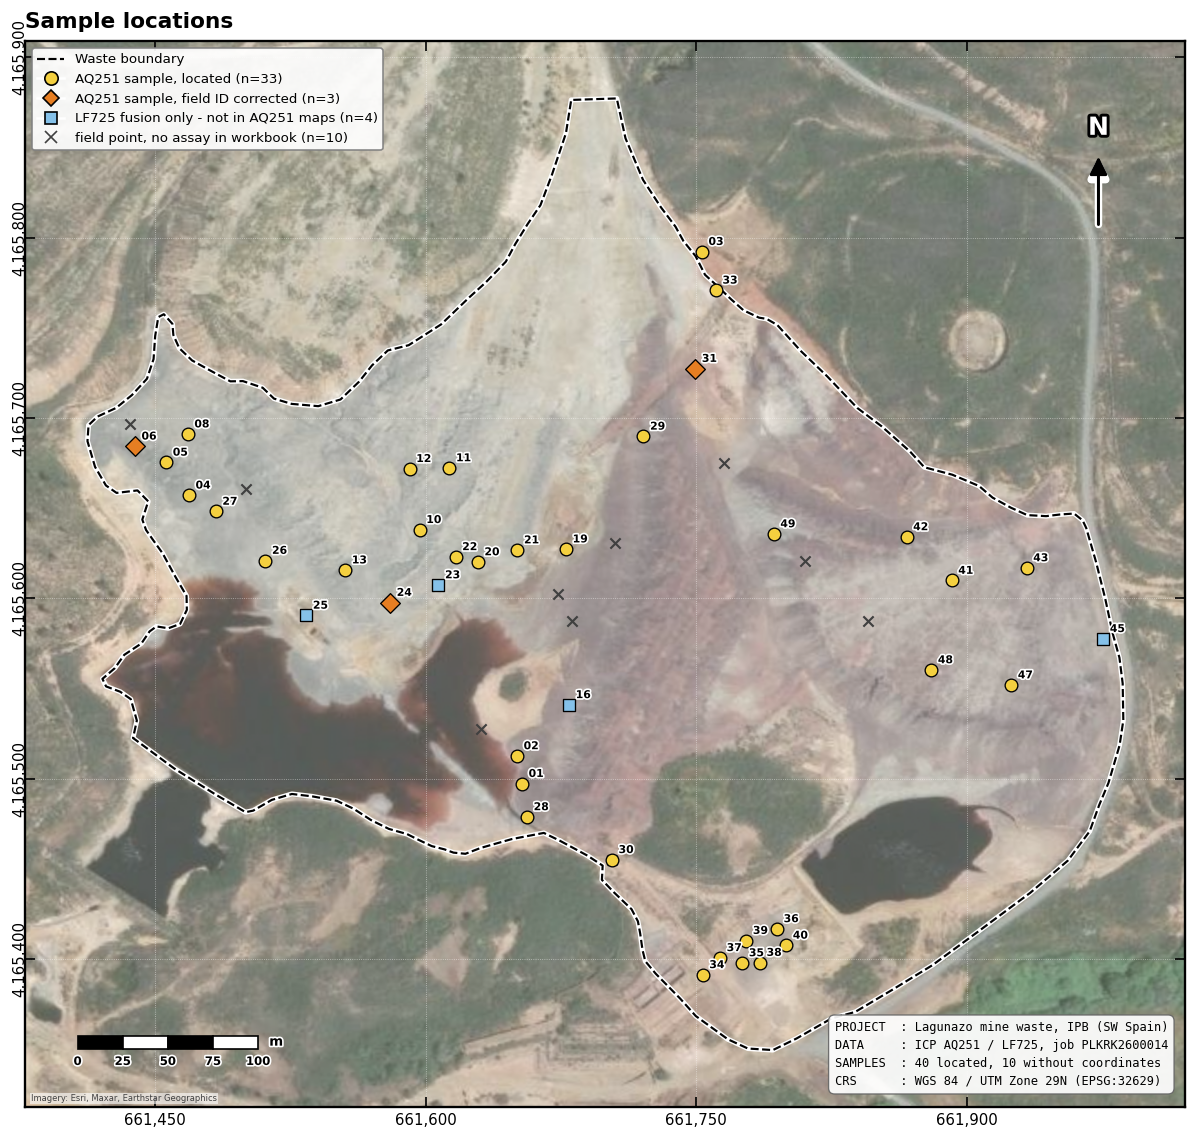

Figure 0 saved -> ICP_sample_locations_UTM29N.png


In [14]:
fig, ax = plt.subplots(figsize=(11, 9.6))
add_satellite_basemap(ax)
loc_only = loc_ok.loc[~loc_ok.index.isin(SAMP["_key"])]
ax.scatter(loc_only["X_utm"], loc_only["Y_utm"], marker="x", s=38, c="0.25", lw=1.3, zorder=11)
_aq = has_aq[has_any].to_numpy()
s_ok = SAMP[LOCATED & _aq & (SAMP["ID_fix"] == "")]
s_fx = SAMP[LOCATED & _aq & (SAMP["ID_fix"] != "")]
s_lf = SAMP[LOCATED & ~_aq]
ax.scatter(s_lf["X_utm"], s_lf["Y_utm"], s=52, c="#85c1e9", marker="s", edgecolors="black", lw=0.8, zorder=12)
ax.scatter(s_ok["X_utm"], s_ok["Y_utm"], s=58, c="#f4d03f", edgecolors="black", lw=0.8, zorder=12)
ax.scatter(s_fx["X_utm"], s_fx["Y_utm"], s=70, c="#e67e22", marker="D", edgecolors="black", lw=0.8, zorder=12)
for _, r in SAMP[LOCATED].iterrows():
    ax.annotate(r["Sample"][-2:], (r["X_utm"], r["Y_utm"]), xytext=(4, 4), textcoords="offset points",
                fontsize=6.5, fontweight="bold", zorder=13,
                path_effects=[mpe.withStroke(linewidth=2, foreground="white")])
add_map_furniture(ax)
ax.set_title("Sample locations",
             fontsize=13, fontweight="bold", loc="left", pad=8)
ax.legend(handles=[
    Line2D([0], [0], color="black", lw=1.3, ls="--", label=BND_LEGEND),
    Line2D([0], [0], marker="o", color="w", mfc="#f4d03f", mec="black", ms=8,
           label=f"AQ251 sample, located (n={len(s_ok)})"),
    Line2D([0], [0], marker="D", color="w", mfc="#e67e22", mec="black", ms=7,
           label=f"AQ251 sample, field ID corrected (n={len(s_fx)})"),
    Line2D([0], [0], marker="s", color="w", mfc="#85c1e9", mec="black", ms=7,
           label=f"LF725 fusion only - not in AQ251 maps (n={len(s_lf)})"),
    Line2D([0], [0], marker="x", color="0.25", lw=0, ms=7,
           label=f"field point, no assay in workbook (n={len(loc_only)})")],
    loc="upper left", fontsize=8, framealpha=0.92, edgecolor="0.5")
info_block(ax, [
    "PROJECT  : Lagunazo mine waste, IPB (SW Spain)",
    f"DATA     : ICP AQ251 / LF725, job {LAB_INFO.get('Job Number', '')}",
    f"SAMPLES  : {int(LOCATED.sum())} located, {int((~LOCATED).sum())} without coordinates",
    "CRS      : WGS 84 / UTM Zone 29N (EPSG:32629)"])
plt.tight_layout()
plt.savefig("ICP_sample_locations_UTM29N.png", dpi=400, bbox_inches="tight")
plt.show()
print("Figure 0 saved -> ICP_sample_locations_UTM29N.png")

## 7 · Stage 1 - Screening

Every selected CRM element goes through the same admission test (r10 rules) on its **located** assays, after
censoring substitution and collapsing replicates within 5 m into stations. Nothing is dropped silently. Each
station set is also declustered here; the weights are used for the declustered mean and the normal-score
reference distribution.

In [15]:
def element_points(el):
    """Located samples with an assay for `el`; censored values substituted, flag kept."""
    f = RAW_FLAG.loc[has_any, el].to_numpy()
    v = RAW_VAL.loc[has_any, el].to_numpy(float)
    z = np.where(f == "ok", v, np.where(f == "bdl", BDL_FACTOR * v, np.where(f == "odl", ODL_FACTOR * v, np.nan)))
    d = pd.DataFrame({"Sample": SAMP["Sample"].to_numpy(), "X_utm": SAMP["X_utm"].to_numpy(),
                      "Y_utm": SAMP["Y_utm"].to_numpy(), el: z, "flag": f})
    return d[LOCATED & np.isfinite(z)].reset_index(drop=True)

def unit_of(el):
    return META.loc[el, "unit"]

def is_partial(el):
    return digestion_class(el).startswith("partial")

def resolve_elements(spec):
    if spec is None:
        return list(MAPPABLE), []
    spec = [spec] if isinstance(spec, str) else list(spec)
    lut = {k.lower(): k for k in META.index}
    chosen, unknown = [], []
    for s in spec:
        k = lut.get(str(s).strip().lower())
        (chosen if k else unknown).append(k if k else str(s))
    return list(dict.fromkeys(chosen)), unknown

ELEMENT_LIST, _unknown = resolve_elements(ELEMENTS)
if _unknown:
    raise ValueError(f"Unknown analyte(s) in ELEMENTS: {_unknown}")
if VAR_NAME not in ELEMENT_LIST:
    ELEMENT_LIST.append(VAR_NAME)

STATIONS, SCREEN = {}, []
for el in ELEMENT_LIST:
    pe = element_points(el)
    rep = dict(element=el, unit=unit_of(el), n_valid=int(len(pe)),
               n_below_MDL=int((pe["flag"] == "bdl").sum()), n_above_UDL=int((pe["flag"] == "odl").sum()))
    if len(pe) < MIN_STATIONS:
        rep.update(status=f"only {len(pe)} located assays", n_stations=len(pe))
        SCREEN.append(rep)
        continue
    st, srep = station_means(pe, "X_utm", "Y_utm", el, tol_m=STATION_TOL_M, id_col="Sample", flag_col="flag")
    coords = st[["X_utm", "Y_utm"]].to_numpy(float)
    v = st[el].to_numpy(float)
    n = len(v)
    npairs = n * (n - 1) // 2
    sd = float(np.std(v, ddof=1)) if n > 1 else np.nan
    imax = int(np.argmax(np.abs(v - v.mean())))
    rep.update(n_stations=n, n_pairs=npairs, n_with_reps=srep["n_stations_with_reps"],
               mean=float(v.mean()), median=float(np.median(v)), sd=sd, cv=sd / v.mean() if v.mean() else np.nan,
               skew=float(stats.skew(v)), vmin=float(v.min()), vmax=float(v.max()),
               top1_variance_share=float(((v[imax] - v.mean()) ** 2 / (n - 1)) / sd ** 2) if sd > 0 else np.nan)
    if npairs < MIN_PAIRS_TOTAL:
        rep["status"] = f"{npairs} pairs < MIN_PAIRS_TOTAL={MIN_PAIRS_TOTAL}"
    elif len(np.unique(v)) < MIN_DISTINCT_VALS:
        rep["status"] = f"only {len(np.unique(v))} distinct values"
    elif not sd > 0:
        rep["status"] = "zero variance"
    else:
        rep["status"] = "ok"
        rep["advisory"] = f"{n} stations < {ADVISORY_STATIONS}" if n < ADVISORY_STATIONS else ""
        w, cell, _ = declustering_weights(coords, v)
        dmean = float(np.sum(w * v) / w.sum())
        spacing = float(np.median(cKDTree(coords).query(coords, k=2)[0][:, 1]))
        rep.update(declustered_mean=dmean, declus_effect_pct=100 * (dmean - v.mean()) / v.mean(),
                   declus_cell_m=cell, spacing_m=spacing)
        STATIONS[el] = dict(coords=coords, v=v, st=st, w=w, spacing=spacing,
                            max_sep=float(np.max(np.hypot(*(coords[:, None, :] - coords[None, :, :]).transpose(2, 0, 1)))))
    SCREEN.append(rep)

SCREEN_DF = pd.DataFrame(SCREEN)
show_table(SCREEN_DF.drop(columns=[c for c in ["advisory"] if c in SCREEN_DF]), precision=3)
ADMITTED = [r["element"] for r in SCREEN if r["status"] == "ok"]
REJECTED = [(r["element"], r["status"]) for r in SCREEN if r["status"] != "ok"]
print(f"Admitted : {len(ADMITTED)}  ({', '.join(ADMITTED)})")
for e, why in REJECTED:
    print(f"Rejected : {e:3s} {why}")
_adv = [r["element"] for r in SCREEN if r.get("advisory")]
if _adv:
    print(f"Under {ADVISORY_STATIONS} stations (variogram dominated by sampling noise): {', '.join(_adv)}")
_hl = [f"{r['element']} ({100 * r['top1_variance_share']:.0f} %)" for r in SCREEN
       if r["status"] == "ok" and r.get("top1_variance_share", 0) > 0.20]
if _hl:
    print("One station supplies > 20 % of the variance (its pairs dominate every lag it enters): " + ", ".join(_hl))

element,unit,n_valid,n_below_MDL,n_above_UDL,n_stations,n_pairs,n_with_reps,mean,median,sd,cv,skew,vmin,vmax,top1_variance_share,status,declustered_mean,declus_effect_pct,declus_cell_m,spacing_m
Al,%,36,3,0,36,630,0,0.107,0.075,0.125,1.174,2.740,0.005,0.650,0.540,ok,0.092,-14.045,129.7,22.068
Sb,ppm,36,0,2,36,630,0,532.430,336.775,511.507,0.961,1.797,38.870,2000.000,0.235,ok,485.075,-8.894,149.3,22.068
As,ppm,36,0,0,36,630,0,1361.525,898.750,1250.401,0.918,2.286,314.700,6377.000,0.460,ok,1386.875,1.862,31.9,22.068
Ba,ppm,36,0,0,36,630,0,45.608,30.900,46.865,1.028,1.494,1.800,191.200,0.276,ok,44.807,-1.757,31.9,22.068
Bi,ppm,36,0,0,36,630,0,139.724,80.675,149.135,1.067,2.257,5.340,672.680,0.365,ok,128.190,-8.255,61.2,22.068
B,ppm,36,28,0,36,630,0,0.778,0.500,0.815,1.047,4.202,0.500,5.000,0.768,ok,0.767,-1.434,31.9,22.068
Co,ppm,36,0,0,36,630,0,4.636,3.100,7.146,1.541,3.392,0.200,32.500,0.434,ok,3.732,-19.512,41.6,22.068
Cu,ppm,36,0,0,36,630,0,511.453,239.950,877.228,1.715,3.094,64.210,4159.290,0.494,ok,413.487,-19.154,41.6,22.068
Ga,ppm,36,1,0,36,630,0,0.779,0.550,0.762,0.978,2.665,0.050,4.100,0.543,ok,0.759,-2.617,51.4,22.068
Ge,ppm,36,19,0,36,630,0,0.137,0.050,0.154,1.118,2.040,0.050,0.600,0.259,ok,0.115,-16.556,149.3,22.068


Admitted : 26  (Al, Sb, As, Ba, Bi, B, Co, Cu, Ga, Ge, Hf, Y, La, Ce, Li, Mg, Mn, Ni, Nb, P, Pt, Sc, Sr, Ti, W, V)
One station supplies > 20 % of the variance (its pairs dominate every lag it enters): Al (54 %), Sb (24 %), As (46 %), Ba (28 %), Bi (36 %), B (77 %), Co (43 %), Cu (49 %), Ga (54 %), Ge (26 %), Hf (21 %), Y (60 %), La (59 %), Ce (65 %), Li (79 %), Mg (81 %), Mn (73 %), Ni (47 %), Nb (73 %), P (86 %), Pt (24 %), Sc (28 %), Sr (30 %), Ti (80 %), W (32 %), V (91 %)


## 8 · Stage 2 - Variogram, Model and Transform Selection

For each admitted element and each transform: experimental variogram (equal-count lags, every lag ≥ 30 pairs,
cutoff ½ × the largest station separation), weighted least-squares fits of four structured models plus the pure-nugget
benchmark, and leave-one-out ordinary kriging with each model. **The model** is chosen on the fit-space LOOCV score
`RMSE × (1 + 0.15·|RMSSE − 1|)`, with scores within 2 % tied and the simpler model preferred. **The transform** is
chosen on LOOCV RMSE after back-transformation to grade units, and must beat `none` by at least 2 %.

The variogram is not refitted inside each cross-validation fold (standard practice), and the same errors choose the
model and the transform, so the Stage-2 error is optimistic - for some elements strongly (Section 8b).

In [16]:
def _max_sep(c):
    return float(np.max(np.hypot(c[:, None, 0] - c[None, :, 0], c[:, None, 1] - c[None, :, 1])))

def _spacing(c):
    return float(np.median(cKDTree(c).query(c, k=2)[0][:, 1]))

def analyse_core(coords, v, w, transform, label=""):
    """Transform -> variogram -> 5 model fits -> LOOCV each -> model choice -> LOOCV metrics in grade units.
    Works on plain arrays so that the nested cross-validation can re-run it without any held-out station."""
    spacing = _spacing(coords)
    tf = Transform(transform).fit(v, w=w)
    y = tf.forward(v)
    cutoff = CUTOFF_FACTOR * _max_sep(coords)
    vgm = experimental_variogram(coords, y, cutoff)
    out = dict(transform=transform, tf=tf, y=y, vgm=vgm, cutoff=cutoff, spacing=spacing,
               sample_variance=float(np.var(y, ddof=1)))
    if len(vgm) < 3:
        out["status"] = f"only {len(vgm)} lag(s) with >= {MIN_PAIRS_LAG} pairs"
        return out
    res = []
    for model, hits, wrss in fit_models(vgm, cutoff):
        radius = search_radius_for(model, spacing)
        cv = ok_batch(coords, coords, y, model, radius=radius, exclude_self=True)
        err = cv["est"] - y
        rmse = float(np.sqrt(np.mean(err ** 2)))
        pos = cv["var"] > 0
        rmsse = float(np.sqrt(np.mean(err[pos] ** 2 / cv["var"][pos]))) if pos.any() else np.nan
        score = rmse * (1 + RMSSE_PENALTY * abs((rmsse if np.isfinite(rmsse) else 1.0) - 1.0))
        res.append(dict(model=model, hits=hits, wrss=wrss, radius=radius, cv=cv,
                        rmse_fit=rmse, rmsse=rmsse, score=score))
    res.sort(key=lambda r: r["score"])
    tied = [r for r in res if r["score"] <= res[0]["score"] * (1 + SELECTION_TOL_PCT / 100)]
    best = sorted(tied, key=lambda r: MODEL_PREFERENCE.index(r["model"].name))[0]
    cv = best["cv"]
    pred = cv["est"] if transform == "none" else tf.back(cv["est"], var=cv["var"], mu=cv["mu"])
    n_clip = int(np.sum(pred < 0))
    pred = np.clip(pred, 0.0, None)
    m = metrics(v, pred, label=f"OK LOOCV {label} ({transform})")
    z = (cv["est"] - y) / np.sqrt(np.maximum(cv["var"], 1e-300))
    nug = next(r for r in res if r["model"].name == "Nugget")
    out.update(status="ok", results=res, tied=[r["model"].name for r in tied], best=best, model=best["model"],
               radius=best["radius"], pred_ppm=pred, n_clip_cv=n_clip, m=m, rmse_ppm=m["RMSE"], r2_ppm=m["R2_pred"],
               rmse_fit=best["rmse_fit"], rmsse=best["rmsse"],
               coverage95=float(100 * np.mean(np.abs(z) <= 1.959964)), mean_std_err=float(np.mean(z)),
               gain_vs_nugget_pct=100 * (nug["rmse_fit"] - best["rmse_fit"]) / nug["rmse_fit"],
               bound_hits=", ".join(best["hits"]), n_extended_cv=int(cv["extended"].sum()))
    return out


def analyse(el, transform):
    S = STATIONS[el]
    out = analyse_core(S["coords"], S["v"], S["w"], transform, label=el)
    out["element"] = el
    return out


def gain_pct(base, chal):
    """Improvement of `chal` over `base` for an error measure (lower is better), normalised by |base|."""
    return 100.0 * (base - chal) / max(abs(base), 1e-12)


def select_transform(cands):
    """Lowest back-transformed LOOCV RMSE; a transform must beat 'none' by TRANSFORM_MIN_GAIN_PCT."""
    ok_ = {t: a for t, a in cands.items() if a["status"] == "ok"}
    if not ok_:
        return None
    pick = min(ok_.values(), key=lambda a: a["rmse_ppm"])
    g = np.nan
    if "none" in ok_ and pick["transform"] != "none":
        g = gain_pct(ok_["none"]["rmse_ppm"], pick["rmse_ppm"])
        if g < TRANSFORM_MIN_GAIN_PCT:
            pick = ok_["none"]
    pick["transform_gain_pct"] = g
    return pick


CAND, FITS, TRIALS = {}, {}, []
_t0 = time.time()
for el in ADMITTED:
    CAND[el] = {}
    for tr in TRANSFORM_CANDIDATES:
        a = analyse(el, tr)
        CAND[el][tr] = a
        if a["status"] != "ok":
            TRIALS.append(dict(element=el, transform=tr, status=a["status"]))
            continue
        TRIALS.append(dict(element=el, transform=tr, status="ok", model=a["model"].name,
                           ns_ratio=a["model"].nugget / a["model"].sill,
                           range_m=np.nan if a["model"].name == "Nugget" else a["model"].rng,
                           on_bound=a["bound_hits"] or "-", lags=len(a["vgm"]), tied=", ".join(a["tied"]),
                           rmse_fit=a["rmse_fit"], rmsse=a["rmsse"], gain_vs_nugget_pct=a["gain_vs_nugget_pct"],
                           rmse_ppm=a["rmse_ppm"], r2_ppm=a["r2_ppm"],
                           slope_obs_on_pred=a["m"]["Slope_obs_on_pred"], coverage95=a["coverage95"]))
    pick = select_transform(CAND[el])
    if pick is None:
        continue
    FITS[el] = pick
    print(f"  {el:3s} -> {pick['transform']:6s} {pick['model'].name:11s} N:S={pick['model'].nugget / pick['model'].sill:4.2f}"
          f"  RMSE={pick['rmse_ppm']:>10,.4g} {unit_of(el):3s}  R2={pick['r2_ppm']:+.3f}"
          f"  slope(obs~pred)={pick['m']['Slope_obs_on_pred']:5.2f}  RMSSE={pick['rmsse']:4.2f}")
TRIALS_DF = pd.DataFrame(TRIALS)
print(f"\n{len(TRIALS)} element x transform analyses in {time.time() - _t0:.1f} s")
show_table(TRIALS_DF, precision=3)
STAGE2_FAILED = {el: "; ".join(a["status"] for a in CAND[el].values()) for el in ADMITTED if el not in FITS}
if STAGE2_FAILED:
    print("Admitted but no variogram could be estimated:", STAGE2_FAILED)

  Al  -> none   Nugget      N:S=1.00  RMSE=    0.1248 %    R2=-0.024  slope(obs~pred)= 0.35  RMSSE=1.01
  Sb  -> none   Nugget      N:S=1.00  RMSE=     434.5 ppm  R2=+0.258  slope(obs~pred)= 1.30  RMSSE=0.96
  As  -> nscore Spherical   N:S=0.47  RMSE=     1,186 ppm  R2=+0.074  slope(obs~pred)= 0.64  RMSSE=1.01
  Ba  -> none   Cubic       N:S=0.26  RMSE=     40.37 ppm  R2=+0.237  slope(obs~pred)= 0.72  RMSSE=1.25
  Bi  -> log    Spherical   N:S=0.49  RMSE=     106.2 ppm  R2=+0.479  slope(obs~pred)= 1.02  RMSSE=0.90
  B   -> nscore Spherical   N:S=0.47  RMSE=     0.771 ppm  R2=+0.079  slope(obs~pred)= 1.24  RMSSE=1.00
  Co  -> nscore Nugget      N:S=1.00  RMSE=     6.656 ppm  R2=+0.108  slope(obs~pred)= 1.31  RMSSE=1.02
  Cu  -> nscore Spherical   N:S=0.71  RMSE=     807.4 ppm  R2=+0.129  slope(obs~pred)= 0.85  RMSSE=0.95
  Ga  -> none   Spherical   N:S=0.09  RMSE=    0.5957 ppm  R2=+0.371  slope(obs~pred)= 0.93  RMSSE=1.32
  Ge  -> none   Nugget      N:S=1.00  RMSE=    0.1365 ppm  R2=+0

element,transform,status,model,ns_ratio,range_m,on_bound,lags,tied,rmse_fit,rmsse,gain_vs_nugget_pct,rmse_ppm,r2_ppm,slope_obs_on_pred,coverage95
Al,none,ok,Nugget,1.000,,-,11,"Gaussian, Spherical, Nugget",0.125,1.005,0.000,0.125,-0.024,0.352,94.444
Al,log,ok,Exponential,0.514,377.575,range,11,Exponential,1.098,1.027,3.875,0.126,-0.045,0.431,94.444
Al,nscore,ok,Spherical,0.703,118.091,-,11,"Gaussian, Spherical, Exponential, Cubic",0.903,0.987,2.230,0.126,-0.047,0.417,94.444
Sb,none,ok,Nugget,1.000,,-,11,"Nugget, Cubic, Gaussian, Spherical",434.543,0.962,0.000,434.543,0.258,1.295,91.667
Sb,log,ok,Nugget,1.000,,-,11,Nugget,0.793,0.924,0.000,438.885,0.243,1.535,97.222
Sb,nscore,ok,Nugget,1.000,,-,11,Nugget,0.930,0.933,0.000,438.777,0.243,1.472,97.222
As,none,ok,Nugget,1.000,,-,11,Nugget,1256.777,1.018,0.000,1256.777,-0.039,0.004,94.444
As,log,ok,Spherical,0.320,192.632,-,11,"Cubic, Gaussian, Spherical",0.698,1.078,11.400,1194.878,0.061,0.596,94.444
As,nscore,ok,Spherical,0.471,173.796,-,11,"Cubic, Gaussian, Spherical",0.920,1.013,9.472,1186.273,0.074,0.644,94.444
Ba,none,ok,Cubic,0.260,274.439,-,11,"Gaussian, Cubic",40.370,1.252,9.205,40.370,0.237,0.725,86.111


## 8b · Nested Cross-Validation - Honest Skill of the Whole Procedure

Stage 2 picks, for each element, the best of up to 15 candidate predictors (3 transforms × 5 models) **using the same
leave-one-out errors that it then reports**, and the variogram is fitted with every station present. Both make the
Stage-2 R² optimistic, most of all for elements near the 0.10 line. Here the **entire selection** — transform,
experimental variogram, model fits, model choice, transform choice — is repeated without each station in turn, and
that station is then predicted by the procedure's choice. The resulting nested R² is the honest estimate of how well
*this workflow* predicts unsampled ground, and it is the one that decides surface vs posted values.

In [17]:
def nested_loocv(el):
    S = STATIONS[el]
    n = len(S["v"])
    pred, picks = np.full(n, np.nan), []
    for i in range(n):
        keep = np.arange(n) != i
        c, v_ = S["coords"][keep], S["v"][keep]
        w_, _, _ = declustering_weights(c, v_)            # declustering redone without the held-out station
        pick = select_transform({t: analyse_core(c, v_, w_, t) for t in TRANSFORM_CANDIDATES})
        if pick is None:
            picks.append(("-", "-"))
            continue
        r = ok_batch(S["coords"][i:i + 1], c, pick["y"], pick["model"], radius=pick["radius"])
        p = r["est"] if pick["transform"] == "none" else pick["tf"].back(r["est"], var=r["var"], mu=r["mu"])
        pred[i] = max(float(p[0]), 0.0)
        picks.append((pick["transform"], pick["model"].name))
    return pred, picks

NESTED = {}
_t0 = time.time()
for el in FITS:
    pred, picks = nested_loocv(el)
    mn = metrics(STATIONS[el]["v"], pred, label=f"nested {el}")
    sel = (FITS[el]["transform"], FITS[el]["model"].name)
    NESTED[el] = dict(pred=pred, m=mn, picks=picks,
                      same_choice_pct=100 * np.mean([p_ == sel for p_ in picks]),
                      same_transform_pct=100 * np.mean([p_[0] == sel[0] for p_ in picks]))
    FITS[el]["r2_nested"] = mn["R2_pred"]
    # bootstrap of the (observed, nested-predicted) pairs: uncertainty of the nested R2 from 36 stations
    _o, _p = STATIONS[el]["v"], pred
    _ok = np.isfinite(_p)
    _o, _p = _o[_ok], _p[_ok]
    _rng = np.random.default_rng(11)
    _b = []
    for _ in range(N_BOOT):
        j = _rng.integers(0, len(_o), len(_o))
        sst = np.sum((_o[j] - _o[j].mean()) ** 2)
        if sst > 0:
            _b.append(1 - np.sum((_p[j] - _o[j]) ** 2) / sst)
    _b = np.asarray(_b)
    FITS[el]["r2_nested_ci90"] = (float(np.percentile(_b, 5)), float(np.percentile(_b, 95)))
    FITS[el]["p_below_threshold"] = float(np.mean(_b < MIN_R2_SURFACE))
    FITS[el]["rmse_nested"] = mn["RMSE"]
    print(f"  {el:3s} R2 LOOCV {FITS[el]['r2_ppm']:+.3f} -> nested {mn['R2_pred']:+.3f} "
          f"[90 % CI {FITS[el]['r2_nested_ci90'][0]:+.2f}, {FITS[el]['r2_nested_ci90'][1]:+.2f}]  "
          f"selection reproduced in {NESTED[el]['same_choice_pct']:3.0f} % of folds "
          f"(transform {NESTED[el]['same_transform_pct']:3.0f} %)")
print(f"\nNested cross-validation: {len(FITS)} elements x {len(STATIONS[VAR_NAME]['v'])} folds in {time.time() - _t0:.0f} s")

  Al  R2 LOOCV -0.024 -> nested -0.111 [90 % CI -0.57, -0.01]  selection reproduced in  81 % of folds (transform  92 %)
  Sb  R2 LOOCV +0.258 -> nested +0.120 [90 % CI -0.35, +0.31]  selection reproduced in  44 % of folds (transform  81 %)
  As  R2 LOOCV +0.074 -> nested +0.010 [90 % CI -0.48, +0.14]  selection reproduced in  47 % of folds (transform  86 %)
  Ba  R2 LOOCV +0.237 -> nested +0.107 [90 % CI -0.41, +0.34]  selection reproduced in  67 % of folds (transform  75 %)
  Bi  R2 LOOCV +0.479 -> nested +0.341 [90 % CI -0.61, +0.56]  selection reproduced in  28 % of folds (transform  47 %)
  B   R2 LOOCV +0.079 -> nested -0.029 [90 % CI -0.33, +0.04]  selection reproduced in  50 % of folds (transform  97 %)
  Co  R2 LOOCV +0.108 -> nested +0.039 [90 % CI -1.69, +0.08]  selection reproduced in  64 % of folds (transform  92 %)
  Cu  R2 LOOCV +0.129 -> nested -0.039 [90 % CI -0.92, +0.08]  selection reproduced in  72 % of folds (transform  75 %)
  Ga  R2 LOOCV +0.371 -> nested -0.087 [

## 9 · Stage 3 - Kriging the Grid

The grid is the IDW notebook's 3 m grid over the boundary's bounding box, masked to the polygon, so OK and IDW
rasters are co-registered. Each element is kriged once with its selected transform and model. The estimate is
back-transformed to grade units; the uncertainty is carried as the fit-space kriging standard error **and** as an
approximate prediction standard deviation in grade units.

In [18]:
xi = np.arange(xmin_u, xmax_u + GRID_DENSITY_M, GRID_DENSITY_M)
yi = np.arange(ymin_u, ymax_u + GRID_DENSITY_M, GRID_DENSITY_M)
XG, YG = np.meshgrid(xi, yi)
NROW, NCOL = XG.shape
GRID_PTS = np.column_stack([XG.ravel(), YG.ravel()])
INSIDE = inside_domain(XG.ravel(), YG.ravel())
in_hull = INSIDE.reshape(NROW, NCOL)
print(f"Grid: {NCOL} x {NROW} = {NROW * NCOL:,} nodes at {GRID_DENSITY_M:g} m; {int(INSIDE.sum()):,} inside the {BND_LABEL}")

def to_grid(vals_inside, fill=np.nan):
    g = np.full(NROW * NCOL, fill, dtype=float)
    g[INSIDE] = vals_inside
    return g.reshape(NROW, NCOL)

def extrap_distance(coords):
    return float(cKDTree(coords).query(coords, k=2)[0][:, 1].max())

GRIDS = {}
_t0 = time.time()
for el, f in FITS.items():
    S = STATIONS[el]
    r = ok_batch(GRID_PTS[INSIDE], S["coords"], f["y"], f["model"], radius=f["radius"])
    tf = f["tf"]
    Z = r["est"] if f["transform"] == "none" else tf.back(r["est"], var=r["var"], mu=r["mu"])
    n_neg = int(np.sum(Z < 0))
    Z = np.clip(Z, 0.0, None)
    SD = tf.back_sd(r["est"], r["var"], Z)
    ex_d = extrap_distance(S["coords"])
    D = cKDTree(S["coords"]).query(GRID_PTS[INSIDE], k=1)[0]
    GRIDS[el] = dict(Z=to_grid(Z), SD=to_grid(SD), SE_fit=to_grid(np.sqrt(r["var"])), MU=to_grid(r["mu"]),
                     EXT=to_grid(r["extended"].astype(float)), NUSED=to_grid(r["n_used"].astype(float)),
                     D=to_grid(D), EX=to_grid((D > ex_d).astype(float)), ex_d=ex_d, n_clipped=n_neg,
                     cond_max=r["cond_max"], radius_is_global=bool(f["radius"] >= np.hypot(xmax_u - xmin_u, ymax_u - ymin_u)))
    print(f"  {el:3s} {f['transform']:6s} {f['model'].name:11s} surface {np.nanmin(Z):>9,.4g} - {np.nanmax(Z):>9,.4g} "
          f"{unit_of(el):3s} (data {S['v'].min():,.4g} - {S['v'].max():,.4g})  radius {f['radius']:.0f} m"
          + (f"  [{n_neg} negative estimates clipped]" if n_neg else ""))
print(f"\n{len(GRIDS)} grids kriged in {time.time() - _t0:.1f} s")

Grid: 193 x 177 = 34,161 nodes at 3 m; 18,041 inside the Waste polygon
  Al  none   Nugget      surface   0.06062 -    0.1744 %   (data 0.005 - 0.65)  radius 403 m
  Sb  none   Nugget      surface     233.3 -     834.7 ppm (data 38.87 - 2,000)  radius 403 m
  As  nscore Spherical   surface     615.3 -     3,467 ppm (data 314.7 - 6,377)  radius 278 m
  Ba  none   Cubic       surface     3.165 -     141.5 ppm (data 1.8 - 191.2)  radius 439 m
  Bi  log    Spherical   surface     34.37 -     533.1 ppm (data 5.34 - 672.7)  radius 176 m
  B   nscore Spherical   surface    0.5029 -     1.622 ppm (data 0.5 - 5)  radius 604 m
  Co  nscore Nugget      surface     2.656 -      8.29 ppm (data 0.2 - 32.5)  radius 403 m
  Cu  nscore Spherical   surface     141.3 -     1,268 ppm (data 64.21 - 4,159)  radius 604 m
  Ga  none   Spherical   surface    0.1817 -     3.347 ppm (data 0.05 - 4.1)  radius 600 m
  Ge  none   Nugget      surface   0.05937 -    0.2344 ppm (data 0.05 - 0.6)  radius 403 m
  Hf  no

## 10 · Stage 4 - Cross-Element Summary

**The nested `R2` (grade units) decides whether a map means anything** (Stage-2 `R2` is shown beside it to expose the
selection optimism), compared with two benchmarks computed by leave-one-out: the **leave-one-out mean** (predict each station by the mean of the others; its R² is slightly
negative by construction) and a plain **IDW** (p = 2, 16 nearest). Every kriged CRM is mapped (`MAP_ALL_SURFACES`);
its **reliability** is predictive (nested R² ≥ 0.10), weak (0 – 0.10) or no skill (< 0, descriptive only). When the
pure-nugget model wins, ordinary kriging assigns equal weights to the K neighbours: the map is a **local moving
average**, and its kriging SD only reflects the number of neighbours.

In [19]:
def crm_breaks(el, zgrid, svals, scheme):
    """Class breaks for one element. If any station is below detection (<MDL, plotted at BDL_FACTOR x MDL), the
    lowest class is [minimum, MDL) = '<MDL' and the other classes are built from the DETECTED station values only
    (percentiles or equal intervals), so tied substituted values cannot collapse the legend into one or two classes.
    Returns (breaks, mdl or None)."""
    sv = np.asarray(svals, float)
    mdl = float(META.loc[el, "mdl"])
    if not (CENSORED_CLASS and np.any(sv < mdl * (1 - 1e-9))):
        return class_breaks(zgrid, sv, scheme), None
    zv = np.concatenate([np.asarray(zgrid)[np.isfinite(zgrid)], sv])
    lo, hi = float(zv.min()), float(zv.max())
    det = sv[sv >= mdl * (1 - 1e-9)]
    if scheme == "quantile" and det.size >= 4:
        q = np.unique([float(f"{x:.3g}") for x in np.nanpercentile(det, [0, 25, 50, 75, 90, 100])])
    else:
        q = nice_breaks(mdl, max(hi, mdl * 1.001), max(N_GRADE_CLASSES - 1, 2))
    upper = [float(x) for x in q if x > mdl * (1 + 1e-9)]
    if not upper:
        upper = [max(hi, mdl * 1.5)]
    upper[-1] = max(upper[-1], hi)
    edges = np.array(sorted(set([min(lo, mdl * BDL_FACTOR), mdl] + upper)))
    return edges, mdl


def crm_formatter(breaks, mdl):
    """Colour-bar labels: the '<MDL' class ends at the tick labelled 'MDL x'; its bottom edge is left blank."""
    if mdl is None:
        return mticker.FuncFormatter(lambda v, _=None: fmt_num(v))
    def f(v, _=None):
        if abs(v - breaks[0]) <= 1e-9 * max(abs(breaks[0]), 1e-300):
            return ""
        if abs(v - mdl) <= 1e-6 * max(abs(mdl), 1e-300):
            return f"MDL {fmt_num(mdl)}"
        return fmt_num(v)
    return mticker.FuncFormatter(f)


MDL_CLASS_COLOUR = "#b3b3b3"      # the '<MDL' class is drawn in neutral grey, graded classes in GRADE_CMAP

def crm_cmap(breaks, mdl):
    """Class colours: GRADE_CMAP, with a grey first class when that class is '<MDL'."""
    n = len(breaks) - 1
    if mdl is None:
        return plt.get_cmap(GRADE_CMAP, n)
    base = plt.get_cmap(GRADE_CMAP, max(n - 1, 1))
    return ListedColormap([MDL_CLASS_COLOUR] + [base(i) for i in range(max(n - 1, 1))][: n - 1])


RELIABILITY_COLOUR = {"predictive": "#1e8449", "weak": "#b9770e", "no skill": "#922b21"}

def reliability_class(r2):
    """Cross-validated reliability of a surface: predictive (R2 >= MIN_R2_SURFACE), weak (0 <= R2 < MIN_R2_SURFACE)
    or no skill (R2 < 0: worse than predicting the mean everywhere - the surface is descriptive only)."""
    if r2 is None or not np.isfinite(r2) or r2 < 0:
        return "no skill"
    return "predictive" if r2 >= MIN_R2_SURFACE else "weak"


def censor_line(el, svals):
    """Info-block line for censored elements."""
    mdl = float(META.loc[el, "mdl"])
    nb = int(np.sum(np.asarray(svals, float) < mdl * (1 - 1e-9)))
    if not nb:
        return None
    s = (f"CENSORED : {nb} of {len(svals)} stations <MDL ({fmt_num(mdl)} {unit_of(el)}), plotted at "
         f"{BDL_FACTOR:g} x MDL")
    if nb > 0.5 * len(svals):
        s += "\nNOTE     : mostly below detection - read as detection zones, not grades"
    _q = CRM_TABLE.loc[CRM_TABLE["Analyte"] == el, "Detection quality"]
    if len(_q) and _q.iloc[0]:
        s += "\nNOTE     : all detections < 3 x MDL - presence not firmly established"
    return s


def loo_mean(v):
    v = np.asarray(v, float)
    return (v.sum() - v) / (len(v) - 1)

def loo_idw(coords, v, p=2.0, k=16):
    n = len(v); k = min(k, n - 1)
    d, ix = cKDTree(coords).query(coords, k=k + 1)
    d, ix = d[:, 1:], ix[:, 1:]
    w = 1.0 / np.maximum(d, 1e-9) ** p
    return np.sum(w * v[ix], axis=1) / w.sum(axis=1)

rows = []
for el, f in FITS.items():
    S, g, m = STATIONS[el], GRIDS[el], f["model"]
    v = S["v"]
    sc = next(r for r in SCREEN if r["element"] == el)
    rm_mean = metrics(v, loo_mean(v))["RMSE"]
    m_idw = metrics(v, loo_idw(S["coords"], v))
    r2 = f["r2_nested"]
    rel = reliability_class(r2)
    if r2 >= MIN_R2_SURFACE:
        verdict = "surface - local moving average (pure nugget)" if m.name == "Nugget" else "surface - spatial structure"
        if f["p_below_threshold"] >= MARGINAL_P:
            verdict += f"; marginal (bootstrap P(R2 < {MIN_R2_SURFACE:g}) = {100 * f['p_below_threshold']:.0f} %)"
        if f["rmse_nested"] > m_idw["RMSE"]:
            verdict += "; fixed IDW more accurate - prefer the IDW map"
    elif MAP_ALL_SURFACES:
        verdict = (f"surface - weak skill (nested R2 < {MIN_R2_SURFACE:g})" if rel == "weak"
                   else "surface - descriptive only (no skill in nested CV)")
        if m.name == "Nugget":
            verdict += "; local moving average (pure nugget)"
        if f["rmse_nested"] > m_idw["RMSE"]:
            verdict += "; fixed IDW more accurate"
    else:
        verdict = "posted values (no skill in nested CV)"
    rows.append({
        "Element": el, "Unit": unit_of(el), "Digestion": digestion_class(el), "n": len(v),
        "Reliability": rel, "Censored stations": int(np.sum(v < META.loc[el, "mdl"] * (1 - 1e-9))),
        "n above UDL": sc["n_above_UDL"], "skew": sc["skew"], "top1 var share": sc["top1_variance_share"],
        "Transform": f["transform"], "Model": m.name, "N:S": m.nugget / m.sill,
        "Range (m)": np.nan if m.name == "Nugget" else m.rng, "On bound": f["bound_hits"] or "-",
        "Lags": len(f["vgm"]), "Radius (m)": f["radius"],
        "RMSE": f["rmse_ppm"], "R2": f["r2_ppm"], "R2 nested": r2, "R2 nested CI90 lo": f["r2_nested_ci90"][0],
        "R2 nested CI90 hi": f["r2_nested_ci90"][1], "P(R2<0.10) %": 100 * f["p_below_threshold"],
        "RMSE nested": f["rmse_nested"],
        "Selection reproduced %": NESTED[el]["same_choice_pct"], "Slope obs~pred": f["m"]["Slope_obs_on_pred"],
        "RMSSE (fit)": f["rmsse"], "Coverage95 %": f["coverage95"],
        "RMSE LOO-mean": rm_mean, "RMSE IDW p2 k16": m_idw["RMSE"], "R2 IDW": m_idw["R2_pred"],
        "Gain vs nugget %": f["gain_vs_nugget_pct"], "Transform gain %": f.get("transform_gain_pct", np.nan),
        "Declustered mean": sc["declustered_mean"], "Naive mean": sc["mean"],
        "Surface min": float(np.nanmin(g["Z"])), "Surface max": float(np.nanmax(g["Z"])),
        "Data min": float(v.min()), "Data max": float(v.max()),
        "Var ratio (CV)": f["m"]["Var_ratio"], "Verdict": verdict})
SUMMARY = pd.DataFrame(rows).sort_values("R2 nested", ascending=False).reset_index(drop=True)
show_table(SUMMARY, precision=3)

SURF_ELS = SUMMARY.loc[SUMMARY["Verdict"].str.startswith("surface"), "Element"].tolist()
POST_ELS = SUMMARY.loc[~SUMMARY["Verdict"].str.startswith("surface"), "Element"].tolist()
print(f"\nSurfaces: {len(SURF_ELS)} of {len(SUMMARY)} kriged CRMs"
      + (" (MAP_ALL_SURFACES = True)" if MAP_ALL_SURFACES else f" (nested R2 >= {MIN_R2_SURFACE:g})"))
for _rel in ("predictive", "weak", "no skill"):
    _r = SUMMARY[SUMMARY["Reliability"] == _rel]
    print(f"  {_rel:10s} ({len(_r):2d}): " + (", ".join(f"{r['Element']} ({r['R2 nested']:+.2f}, {r['Model']})"
                                                         for _, r in _r.iterrows()) or "-"))
_c = SUMMARY[SUMMARY["Censored stations"] > 0]
print("  with a '<MDL' class: " + (", ".join(f"{r['Element']} ({r['Censored stations']}/{r['n']})"
                                            for _, r in _c.iterrows()) or "-"))
if POST_ELS:
    print("Posted values only: " + ", ".join(POST_ELS))
_nug = SUMMARY.loc[SUMMARY["Model"] == "Nugget", "Element"].tolist()
if _nug:
    print(f"Pure-nugget model selected (no resolvable spatial correlation at this spacing): {', '.join(_nug)}")
_b = SUMMARY.loc[SUMMARY["On bound"] != "-"]
if len(_b):
    print("Fitted parameter on its bound (set by the bound, not estimated): "
          + ", ".join(f"{r['Element']} ({r['On bound']})" for _, r in _b.iterrows()))
_w = SUMMARY.loc[SUMMARY["RMSE nested"] > SUMMARY["RMSE IDW p2 k16"], "Element"].tolist()
if _w:
    print(f"OK (nested) less accurate than the fixed IDW benchmark: {', '.join(_w)}")
_opt = SUMMARY.loc[(SUMMARY["R2"] >= MIN_R2_SURFACE) & (SUMMARY["R2 nested"] < MIN_R2_SURFACE), "Element"].tolist()
if _opt:
    print(f"Pass on the Stage-2 R2 but fail once selection is cross-validated (selection optimism): {', '.join(_opt)}")

Element,Unit,Digestion,n,Reliability,Censored stations,n above UDL,skew,top1 var share,Transform,Model,N:S,Range (m),On bound,Lags,Radius (m),RMSE,R2,R2 nested,R2 nested CI90 lo,R2 nested CI90 hi,P(R2<0.10) %,RMSE nested,Selection reproduced %,Slope obs~pred,RMSSE (fit),Coverage95 %,RMSE LOO-mean,RMSE IDW p2 k16,R2 IDW,Gain vs nugget %,Transform gain %,Declustered mean,Naive mean,Surface min,Surface max,Data min,Data max,Var ratio (CV),Verdict
Pt,ppb,variable (aqua regia),36,predictive,30,0,2.125,0.240,none,Cubic,0.000,56.702,nugget,11,110.340,0.777,0.574,0.517,-0.026,0.794,7.808,0.827,83.333,1.029,0.826,97.222,1.224,0.947,0.367,32.810,1.088,1.452,1.500,0.559,5.473,1.000,5.000,0.545,surface - spatial structure
Bi,ppm,near-total (aqua regia),36,predictive,0,0,2.257,0.365,log,Spherical,0.492,109.911,-,11,175.857,106.168,0.479,0.341,-0.611,0.560,24.500,119.355,27.778,1.022,0.902,97.222,151.250,109.450,0.446,11.023,3.105,128.190,139.724,34.369,533.146,5.340,672.680,0.463,surface - spatial structure; fixed IDW more accurate - prefer the IDW map
P,%,variable (aqua regia),36,predictive,3,0,4.809,0.858,nscore,Exponential,0.213,377.575,range,11,604.120,0.004,0.409,0.211,-0.311,0.666,12.400,0.005,97.222,1.276,1.004,97.222,0.006,0.005,0.202,24.231,10.562,0.003,0.003,0.001,0.022,0.000,0.035,0.264,surface - spatial structure
Sb,ppm,near-total (aqua regia),36,predictive,0,2,1.797,0.235,none,Nugget,1.000,,-,11,402.747,434.543,0.258,0.120,-0.350,0.309,52.200,473.219,44.444,1.295,0.962,91.667,518.763,417.254,0.316,0.000,,485.075,532.430,233.332,834.733,38.870,2000.000,0.164,surface - local moving average (pure nugget); marginal (bootstrap P(R2 < 0.1) = 52 %); fixed IDW more accurate - prefer the IDW map
Ba,ppm,partial (aqua regia) †,36,predictive,0,0,1.494,0.276,none,Cubic,0.260,274.439,-,11,439.103,40.370,0.237,0.107,-0.407,0.335,54.400,43.659,66.667,0.725,1.252,86.111,47.530,39.069,0.285,9.205,,44.807,45.608,3.165,141.514,1.800,191.200,0.526,surface - spatial structure; marginal (bootstrap P(R2 < 0.1) = 54 %); fixed IDW more accurate - prefer the IDW map
Hf,ppm,partial (aqua regia) †,36,weak,2,0,1.057,0.208,none,Spherical,0.262,46.228,-,11,110.340,0.030,0.152,0.077,-0.237,0.236,66.600,0.031,63.889,0.762,1.013,97.222,0.033,0.030,0.134,2.476,,0.053,0.052,0.021,0.111,0.010,0.140,0.293,surface - weak skill (nested R2 < 0.1); fixed IDW more accurate
Y,ppm,partial (aqua regia) †,36,weak,0,0,3.169,0.596,nscore,Spherical,0.394,377.575,range,11,604.120,0.455,0.125,0.072,-0.938,0.239,65.550,0.468,88.889,0.750,1.055,94.444,0.500,0.541,-0.236,15.220,4.679,0.396,0.467,0.200,1.039,0.100,2.720,0.251,surface - weak skill (nested R2 < 0.1)
Co,ppm,near-total (aqua regia),36,weak,0,0,3.392,0.434,nscore,Nugget,1.000,,-,11,402.747,6.656,0.108,0.039,-1.686,0.084,98.700,6.908,63.889,1.306,1.020,94.444,7.247,8.408,-0.424,0.000,4.753,3.732,4.636,2.656,8.290,0.200,32.500,0.069,surface - weak skill (nested R2 < 0.1); local moving average (pure nugget)
Ni,ppm,near-total (aqua regia),36,weak,0,0,3.649,0.469,nscore,Spherical,0.948,139.029,-,11,222.446,9.050,0.124,0.011,-3.864,0.099,95.200,9.615,77.778,1.028,0.940,94.444,9.944,11.337,-0.375,4.513,4.329,4.677,6.075,2.454,13.577,0.600,45.800,0.117,surface - weak skill (nested R2 < 0.1)
As,ppm,near-total (aqua regia),36,weak,0,0,2.286,0.460,nscore,Spherical,0.471,173.796,-,11,278.074,1186.273,0.074,0.010,-0.484,0.136,87.550,1227.028,47.222,0.644,1.013,94.444,1268.138,1243.965,-0.018,9.472,5.610,1386.875,1361.525,615.292,3467.236,314.700,6377.000,0.266,surface - weak skill (nested R2 < 0.1)



Surfaces: 26 of 26 kriged CRMs (MAP_ALL_SURFACES = True)
  predictive ( 5): Pt (+0.52, Cubic), Bi (+0.34, Spherical), P (+0.21, Exponential), Sb (+0.12, Nugget), Ba (+0.11, Cubic)
  weak       ( 5): Hf (+0.08, Spherical), Y (+0.07, Spherical), Co (+0.04, Nugget), Ni (+0.01, Spherical), As (+0.01, Spherical)
  no skill   (16): V (-0.01, Spherical), Mg (-0.02, Spherical), B (-0.03, Spherical), Cu (-0.04, Spherical), Li (-0.05, Gaussian), Ga (-0.09, Spherical), Mn (-0.09, Spherical), W (-0.10, Nugget), La (-0.10, Nugget), Al (-0.11, Nugget), Ge (-0.14, Nugget), Sr (-0.16, Nugget), Ce (-0.20, Nugget), Ti (-0.22, Nugget), Sc (-0.30, Nugget), Nb (-0.51, Nugget)
  with a '<MDL' class: Pt (30/36), P (3/36), Hf (2/36), V (7/36), Mg (22/36), B (28/36), Li (14/36), Ga (1/36), W (5/36), Al (3/36), Ge (19/36), Ti (4/36), Sc (12/36), Nb (26/36)
Pure-nugget model selected (no resolvable spatial correlation at this spacing): Sb, Co, W, La, Al, Ge, Sr, Ce, Ti, Sc, Nb
Fitted parameter on its bound (set

## 11 · Methodology Audit (detail element and kriging engine)

Every statement about the kriging is tested numerically for `VAR_NAME`. The solver checks use the element's selected
model **and** its best structured model (so that a pure-nugget winner cannot make the checks trivial). **FAIL** means
the workflow is wrong; **WARN** means a limitation that must be reported with the map.

In [20]:
AUDIT = []
def audit(check, status, detail):
    AUDIT.append(dict(Check=check, Status=status, Detail=detail))

el = VAR_NAME
if el not in FITS:
    raise RuntimeError(f"VAR_NAME={el} was not kriged: " + str(STAGE2_FAILED.get(el, dict(REJECTED).get(el))))
f, S, g = FITS[el], STATIONS[el], GRIDS[el]
coords, v, y = S["coords"], S["v"], f["y"]
UNIT = unit_of(el)
struct = min((r for r in f["results"] if r["model"].name != "Nugget"), key=lambda r: r["score"])
rng_ = np.random.default_rng(3)

# 1 coordinates and stations
audit("Coordinates projected to UTM 29N (metres)",
      "PASS" if 166_000 < coords[:, 0].min() < 834_000 and 3e6 < coords[:, 1].min() < 9.4e6 else "FAIL",
      f"E {coords[:, 0].min():.0f}-{coords[:, 0].max():.0f}, N {coords[:, 1].min():.0f}-{coords[:, 1].max():.0f}")
dmin = cKDTree(coords).query(coords, k=2)[0][:, 1].min()
audit("Stations unique (no replicate leakage into LOOCV)", "PASS" if dmin > STATION_TOL_M else "FAIL",
      f"minimum inter-station distance {dmin:.1f} m")

# 2 solver: batched covariance form vs independent semivariogram form, for both models
for tag, mdl, rad in (("selected", f["model"], f["radius"]), ("best structured", struct["model"], struct["radius"])):
    idx = rng_.choice(np.flatnonzero(INSIDE), size=300, replace=False)
    rb = ok_batch(GRID_PTS[idx], coords, y, mdl, radius=rad)
    ref = [ok_point_gamma(GRID_PTS[i], coords, y, mdl, radius=rad) for i in idx]
    de = max(abs(rb["est"][j] - ref[j][0]) for j in range(len(idx)))
    dv = max(abs(rb["var"][j] - ref[j][1]) for j in range(len(idx)))
    dm = max(abs(rb["mu"][j] - ref[j][2]) for j in range(len(idx)))
    sl = max(abs(ref[j][3].sum() - 1) for j in range(len(idx)))
    tol = 1e-8 * max(1.0, mdl.sill)
    audit(f"Batched solver = independent semivariogram-form solver ({tag}: {mdl.name})",
          "PASS" if max(de / max(np.ptp(y), 1e-12), dv / mdl.sill, dm / mdl.sill) < 1e-8 else "FAIL",
          f"300 nodes: max |d est| {de:.1e}, |d var| {dv:.1e}, |d mu| {dm:.1e}; max |sum(lambda) - 1| {sl:.1e}")

# 3 exactness and variance at the data
ex = ok_batch(coords, coords, y, struct["model"], radius=struct["radius"])
audit("Exact at stations (estimate = datum, kriging variance = 0)",
      "PASS" if np.max(np.abs(ex["est"] - y)) < 1e-8 * max(1, np.ptp(y)) and np.max(ex["var"]) < 1e-10 * struct["model"].sill
      else "FAIL", f"max |est - datum| {np.max(np.abs(ex['est'] - y)):.1e}, max variance {np.max(ex['var']):.1e}")
audit("Kriging variance non-negative on the grid", "PASS" if np.nanmin(g["SE_fit"]) >= 0 else "FAIL",
      f"SE range {np.nanmin(g['SE_fit']):.3g} - {np.nanmax(g['SE_fit']):.3g} ({f['transform']} space)")

# 4 cross-validation: batched LOO vs brute force (station removed, system rebuilt)
bf = np.array([ok_point_gamma(coords[i], np.delete(coords, i, 0), np.delete(y, i), f["model"], radius=f["radius"])[0]
               for i in range(len(y))])
dcv = float(np.max(np.abs(bf - f["best"]["cv"]["est"])))
audit("Vectorised LOOCV = brute-force LOOCV", "PASS" if dcv < 1e-8 * max(1, np.ptp(y)) else "FAIL",
      f"max |difference| {dcv:.1e} over {len(y)} stations")

# 5 lognormal back-transform identity (Journel): (C0 - l'Cl)/2 == s2/2 - mu for the log-space model
if CAND[el].get("log", {}).get("status") == "ok":
    ml = CAND[el]["log"]["model"]; yl = CAND[el]["log"]["y"]; rl = CAND[el]["log"]["radius"]
    dd = []
    for i in rng_.choice(np.flatnonzero(INSIDE), size=100, replace=False):
        _, s2, mu_g, lam, use = ok_point_gamma(GRID_PTS[i], coords, yl, ml, radius=rl)
        P = coords[use]
        C = ml.sill - ml.gamma(np.hypot(P[:, None, 0] - P[None, :, 0], P[:, None, 1] - P[None, :, 1]))
        dd.append(abs((ml.sill - lam @ C @ lam) / 2 - (s2 / 2 - mu_g)))
    audit("Log back-transform exp(y + s2/2 - mu) is the unbiased OK form", "PASS" if max(dd) < 1e-8 * ml.sill else "FAIL",
          f"max |(C0 - l'Cl)/2 - (s2/2 - mu)| = {max(dd):.1e} over 100 nodes (log-space model {ml.name})")

# 6 normal-score transform
if CAND[el].get("nscore", {}).get("status") == "ok":
    tn = CAND[el]["nscore"]["tf"]
    rt = np.max(np.abs(tn._ns_back(tn.forward(v)) - v))
    e0 = np.max(np.abs(tn.back(tn.forward(v), var=np.zeros_like(v)) - v))
    audit("Normal-score table: strictly monotone, exact round trip, expectation -> median as s2 -> 0",
          "PASS" if np.all(np.diff(tn._ys) > 0) and rt < 1e-9 * np.ptp(v) and e0 < 1e-9 * np.ptp(v) else "FAIL",
          f"round-trip {rt:.1e}, zero-variance expectation {e0:.1e}; declustered weights used for the cdf")

# 7 variogram and model
vg = f["vgm"]
audit("Every fitted lag has >= MIN_PAIRS_LAG pairs", "PASS" if vg["n_pairs"].min() >= MIN_PAIRS_LAG else "FAIL",
      f"{len(vg)} lags, {vg['n_pairs'].min()}-{vg['n_pairs'].max()} pairs, cutoff {f['cutoff']:.0f} m")
eig = np.linalg.eigvalsh(struct["model"].rho(np.hypot(coords[:, None, 0] - coords[None, :, 0],
                                                      coords[:, None, 1] - coords[None, :, 1])))
audit("Covariance matrix of all stations positive definite (valid 2-D model)", "PASS" if eig.min() > 0 else "FAIL",
      f"smallest eigenvalue {eig.min():.2e} ({struct['model'].name})")
audit("Selected model parameters inside their bounds", "PASS" if not f["bound_hits"] else "WARN",
      f"{f['model']!r}" + (f"; on bound: {f['bound_hits']}" if f["bound_hits"] else ""))
audit("Spatial structure resolved", "PASS" if f["model"].name != "Nugget" else "WARN",
      f"{f['model'].name}, gain over the pure-nugget benchmark {f['gain_vs_nugget_pct']:+.1f} % (fit space)"
      + (" - map is a local moving average; kriging SD reflects only the neighbour count" if f["model"].name == "Nugget" else ""))

# 8 cross-validation quality
row = SUMMARY.set_index("Element").loc[el]
audit(f"Nested-CV skill of the whole procedure (R2 >= {MIN_R2_SURFACE:g})", "PASS" if row["R2 nested"] >= MIN_R2_SURFACE else "WARN",
      f"nested R2 {row['R2 nested']:.3f} (Stage-2 R2 {row['R2']:.3f}); nested RMSE {row['RMSE nested']:,.4g} vs "
      f"LOO-mean {row['RMSE LOO-mean']:,.4g} and IDW {row['RMSE IDW p2 k16']:,.4g} {UNIT}")
audit("Kriging beats the fixed IDW benchmark (p=2, 16 nearest, no tuning)",
      "PASS" if row["RMSE nested"] < row["RMSE IDW p2 k16"] else "WARN",
      f"nested OK RMSE {row['RMSE nested']:,.4g} vs IDW {row['RMSE IDW p2 k16']:,.4g} {UNIT} (IDW R2 {row['R2 IDW']:.3f})"
      + ("" if row["RMSE nested"] < row["RMSE IDW p2 k16"] else " - the variogram adds no accuracy at this sample spacing"))
audit("Robustness of the skill verdict (bootstrap of the nested predictions)",
      "PASS" if FITS[el]["p_below_threshold"] < MARGINAL_P else "WARN",
      f"nested R2 90 % CI [{FITS[el]['r2_nested_ci90'][0]:+.2f}, {FITS[el]['r2_nested_ci90'][1]:+.2f}]; "
      f"P(R2 < {MIN_R2_SURFACE:g}) = {100 * FITS[el]['p_below_threshold']:.0f} %")
audit("Stability of the selection across folds", "PASS" if row["Selection reproduced %"] >= 70 else "WARN",
      f"transform + model reproduced in {row['Selection reproduced %']:.0f} % of nested folds, transform alone in "
      f"{NESTED[el]['same_transform_pct']:.0f} %")
so = row["Slope obs~pred"]
audit("Conditional bias (slope of observed on predicted ~ 1)", "PASS" if abs(so - 1) <= 0.25 else "WARN",
      f"slope {so:.2f}" + ("" if abs(so - 1) <= 0.25 else (" - high estimates overstate" if so < 1 else " - over-smoothed")))
audit("Kriging variance calibration (RMSSE ~ 1, 95 % coverage)",
      "PASS" if 0.75 <= row["RMSSE (fit)"] <= 1.33 and 85 <= row["Coverage95 %"] <= 100 else "WARN",
      f"RMSSE {row['RMSSE (fit)']:.2f}, coverage of +/-1.96 SE {row['Coverage95 %']:.0f} %")

# 9 neighbourhood sensitivity
sens = []
for K in K_SENSITIVITY:
    cvk = ok_batch(coords, coords, y, f["model"], K=K, radius=f["radius"] if K else np.inf, exclude_self=True)
    pk = cvk["est"] if f["transform"] == "none" else f["tf"].back(cvk["est"], var=cvk["var"], mu=cvk["mu"])
    sens.append(f"K={K if K else 'all'}: {metrics(v, np.clip(pk, 0, None))['RMSE']:,.4g}")
audit("Neighbourhood sensitivity (LOOCV RMSE)", "INFO", "; ".join(sens) + f" {UNIT} (adopted K={K_NEIGHBORS})")
audit("Search radius", "INFO", f"{f['radius']:.0f} m" + (" - larger than the domain: effectively K-nearest"
      if g["radius_is_global"] else "") + f"; {100 * np.nanmean(g['EXT']):.1f} % of nodes use the min-{MIN_NEIGHBORS} extension")

# 10 surface and support
over = (np.nanmax(g["Z"]) > v.max() * 1.001) or (np.nanmin(g["Z"]) < v.min() * 0.999)
audit("Surface within the data range", "PASS" if not over and g["n_clipped"] == 0 else "INFO",
      f"surface {np.nanmin(g['Z']):,.4g}-{np.nanmax(g['Z']):,.4g} vs data {v.min():,.4g}-{v.max():,.4g} {UNIT}; "
      f"{g['n_clipped']} negative estimates clipped (OK weights can be negative)")
exs = float(np.nanmean(g["EX"]))
audit("Extrapolated share of the domain", "PASS" if exs < 0.2 else "WARN",
      f"{100 * exs:.1f} % of nodes > {g['ex_d']:.0f} m from any station (hatched on the grade maps)")
cz = next(r for r in SCREEN if r["element"] == el)
audit("Censored values", "PASS" if cz["n_above_UDL"] == 0 and cz["n_below_MDL"] <= 0.3 * cz["n_stations"] else "WARN",
      f"below MDL {cz['n_below_MDL']}, above UDL {cz['n_above_UDL']} (above-UDL values are lower bounds)")
audit("Digestion is total for this element", "WARN" if is_partial(el) else "PASS", digestion_class(el))
audit("Clustering effect on the global mean", "PASS" if abs(cz["declus_effect_pct"]) < 10 else "WARN",
      f"declustered {cz['declustered_mean']:,.4g} vs naive {cz['mean']:,.4g} {UNIT} ({cz['declus_effect_pct']:+.1f} %)")
tg = f.get("transform_gain_pct", np.nan)
audit("Transform choice", "INFO", f"'{f['transform']}' adopted; RMSE by transform: " + ", ".join(
    f"{t} {a['rmse_ppm']:,.4g}" for t, a in CAND[el].items() if a["status"] == "ok") + f" {UNIT}")

AUDIT_TBL = pd.DataFrame(AUDIT)
show_table(AUDIT_TBL, status_col="Status")
if (AUDIT_TBL["Status"] == "FAIL").any():
    raise RuntimeError("Methodology audit FAILED - see the table above.")
print(f"Audit ({el}): {int((AUDIT_TBL['Status'] == 'PASS').sum())} PASS, {int((AUDIT_TBL['Status'] == 'WARN').sum())} WARN, "
      f"{int((AUDIT_TBL['Status'] == 'INFO').sum())} INFO, 0 FAIL")

Check,Status,Detail
Coordinates projected to UTM 29N (metres),PASS,"E 661439-661933, N 4165391-4165792"
Stations unique (no replicate leakage into LOOCV),PASS,minimum inter-station distance 9.8 m
Batched solver = independent semivariogram-form solver (selected: Spherical),PASS,"300 nodes: max |d est| 2.7e-15, |d var| 4.4e-16, |d mu| 8.3e-17; max |sum(lambda) - 1| 4.4e-16"
Batched solver = independent semivariogram-form solver (best structured: Spherical),PASS,"300 nodes: max |d est| 2.7e-15, |d var| 4.4e-16, |d mu| 1.1e-16; max |sum(lambda) - 1| 4.4e-16"
"Exact at stations (estimate = datum, kriging variance = 0)",PASS,"max |est - datum| 0.0e+00, max variance 0.0e+00"
Kriging variance non-negative on the grid,PASS,SE range 0.756 - 1.08 (log space)
Vectorised LOOCV = brute-force LOOCV,PASS,max |difference| 1.8e-15 over 36 stations
Log back-transform exp(y + s2/2 - mu) is the unbiased OK form,PASS,max |(C0 - l'Cl)/2 - (s2/2 - mu)| = 1.7e-16 over 100 nodes (log-space model Spherical)
"Normal-score table: strictly monotone, exact round trip, expectation -> median as s2 -> 0",PASS,"round-trip 0.0e+00, zero-variance expectation 1.1e-13; declustered weights used for the cdf"
Every fitted lag has >= MIN_PAIRS_LAG pairs,PASS,"11 lags, 32-33 pairs, cutoff 252 m"


Audit (Bi): 22 PASS, 2 WARN, 3 INFO, 0 FAIL


## 12 · Stage 5 - Figures (map standard) and Per-Element Exports

For every kriged element four figures are written to `results_OK_ICP/<element>/`: the variogram under each
transform, the cross-validation, **the classified grade map and the uncertainty map as separate figures** (r10) — for every
kriged CRM, each labelled with its nested-CV reliability (weak / no skill are stamped on the map). The detail element's figures are shown below. Maps carry their own
caveats (pure-nugget, approximate SD, no skill) so a map lifted out of the notebook keeps them.

In [21]:
FIG_DPI = 300

def fmt_tick(v, _=None):
    return fmt_num(v)

def nice_breaks(vmin, vmax, n=7):
    raw = (vmax - vmin) / max(n, 1)
    if raw <= 0:
        return np.linspace(vmin, vmax + 1e-9, n + 1)
    mag = 10 ** np.floor(np.log10(raw))
    step = max(round(raw / mag) * mag, mag)
    edges = [np.floor(vmin / step) * step]
    while edges[-1] < vmax:
        edges.append(edges[-1] + step)
    return np.array(edges)

def class_breaks(zgrid, svals, scheme, n=N_GRADE_CLASSES):
    zv = np.concatenate([np.asarray(zgrid)[np.isfinite(zgrid)], np.asarray(svals, float)])
    lo, hi = float(zv.min()), float(zv.max())
    if scheme == "quantile":
        q = np.unique([float(f"{x:.3g}") for x in np.nanpercentile(svals, [0, 10, 25, 50, 75, 90, 95, 100])])
        q[0], q[-1] = min(q[0], lo), max(q[-1], hi)
        return q
    return nice_breaks(lo, hi, n)

def scheme_for(el):
    return CLASS_SCHEME if el == VAR_NAME else ATLAS_CLASS_SCHEME

def _round_display(Z):
    Z = np.asarray(Z, float)
    zmax = np.nanmax(np.abs(Z)) if np.isfinite(Z).any() else 1.0
    return np.round(Z, int(10 - np.floor(np.log10(max(zmax, 1e-300)))))

def draw_surface(ax, Z, breaks, cmap, norm, sx, sy, sv, p90=None, extrap=None, iso=True, fs=1.0, dot=42):
    """Basemap + classified surface + iso-lines + P90 + extrapolation hatching
    + stations + map furniture."""
    add_satellite_basemap(ax)
    Zm = np.ma.masked_invalid(_round_display(Z))
    arts = [ax.contourf(XG, YG, Zm, levels=breaks, cmap=cmap, norm=norm, alpha=SURFACE_ALPHA, zorder=2,
                        extend="both")]
    if iso:
        cl = ax.contour(XG, YG, Zm, levels=breaks[1:-1] if len(breaks) > 2 else breaks, colors="white", linewidths=0.5, alpha=0.7, zorder=3)
        ax.clabel(cl, levels=cl.levels[::2], inline=True, fontsize=6.5 * fs, fmt=fmt_num)
        arts.append(cl)
    if p90 is not None and np.nanmin(Z) < p90 < np.nanmax(Z):
        c90 = ax.contour(XG, YG, Zm, levels=[p90], colors="cyan", linewidths=2.2 * fs, linestyles="--", zorder=5)
        ax.clabel(c90, inline=True, fontsize=8 * fs, fmt=lambda x: f"P90: {fmt_num(x)}")
        arts.append(c90)
    if HATCH_EXTRAP and extrap is not None and np.nanmax(extrap) > 0:
        with plt.rc_context({"hatch.color": "0.1", "hatch.linewidth": 0.6}):
            arts.append(ax.contourf(XG, YG, np.ma.masked_invalid(extrap), levels=[0.5, 1.5], colors="none",
                                    hatches=["////"], zorder=6))
    clip_to_boundary(ax, *arts)
    ax.scatter(sx, sy, s=dot, c=sv, cmap=cmap, norm=norm, edgecolors="black", linewidths=0.7, zorder=11)
    add_map_furniture(ax, fs=fs)
    return arts[0]

def draw_posted(ax, breaks, cmap, norm, sx, sy, sv, fs=1.0, dot=60):
    add_satellite_basemap(ax)
    ax.fill(px_utm, py_utm, fc="white", ec="none", alpha=0.18, zorder=1)
    sv = np.asarray(sv, float)
    cls = np.clip(np.digitize(sv, breaks[1:-1]), 0, len(breaks) - 2)
    o = np.argsort(sv)
    ax.scatter(np.asarray(sx)[o], np.asarray(sy)[o], s=dot * (0.55 + 0.3 * cls[o]), c=sv[o], cmap=cmap, norm=norm,
               edgecolors="black", linewidths=0.8, zorder=11)
    add_map_furniture(ax, fs=fs)

def stamp(ax, text, fs=1.0, color="#922b21"):
    import textwrap
    text = "\n".join(textwrap.fill(t, 62) for t in text.split("\n"))      # right of the legend, left of the arrow
    ax.text(0.62, 0.965, text, transform=ax.transAxes, ha="center", va="top", fontsize=8.5 * fs, fontweight="bold",
            color=color, zorder=25, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=color, alpha=0.92))

def grade_cbar(fig, ax, breaks, cmap, norm, label, scheme, fmt=None, **kw):
    cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, boundaries=breaks, ticks=breaks,
                      spacing="uniform" if scheme == "quantile" else "proportional",
                      format=fmt or mticker.FuncFormatter(fmt_tick), **kw)
    cb.set_label(label, fontsize=10, fontweight="bold"); cb.ax.tick_params(labelsize=8)
    return cb

def _model_line(f):
    m = f["model"]
    rb = " (on bound)" if "range" in (f["bound_hits"] or "") else ""
    return (f"{m.name}  N:S={m.nugget / m.sill:.2f}" + ("" if m.name == "Nugget" else f"  a={m.rng:.0f} m{rb}")
            + f"  ({f['transform']})")

def figure_grade_map(el, out_png):
    f, g, S = FITS[el], GRIDS[el], STATIONS[el]
    sch = scheme_for(el)
    br, mdl_c = crm_breaks(el, g["Z"], S["v"], sch)
    cmap = crm_cmap(br, mdl_c); norm = BoundaryNorm(br, cmap.N)
    p90 = float(np.percentile(S["v"], 90))
    fig, ax = plt.subplots(figsize=(10.5, 9.5))
    draw_surface(ax, g["Z"], br, cmap, norm, S["coords"][:, 0], S["coords"][:, 1], S["v"], p90=p90, extrap=g["EX"])
    grade_cbar(fig, ax, br, cmap, norm, f"{el} ({unit_of(el)})" + ("  [percentile classes]" if sch == "quantile" else "")
               + ("  [grey = below MDL]" if mdl_c is not None else ""), sch, fmt=crm_formatter(br, mdl_c),
               fraction=0.040, pad=0.012)
    ax.set_title(f"Ordinary kriging - {el}{' ' if is_partial(el) else ''} grade estimate - Lagunazo",
                 fontsize=13, fontweight="bold", loc="left", pad=8)
    info_block(ax, [
        "PROJECT  : Lagunazo mine waste, IPB (SW Spain)",
        f"DATA     : ICP {META.loc[el, 'method']} - {digestion_class(el).replace(' †', '')}",
        f"METHOD   : Ordinary kriging (point), back-transform "
        + {"none": "-", "log": LOG_BACKTRANSFORM, "nscore": NSCORE_BACKTRANSFORM}[f["transform"]],
        f"MODEL    : {_model_line(f)}",
        f"NBHD     : K={K_NEIGHBORS}  min={MIN_NEIGHBORS}  r={f['radius']:.0f} m",
        f"X-VALID  : R2 nested={f['r2_nested']:.2f} (LOOCV {f['r2_ppm']:.2f})  n={len(S['v'])}  "
        f"({reliability_class(f['r2_nested'])})",
        "CRS      : WGS 84/UTM Zone 29N (EPSG:32629)"] + [l for l in [censor_line(el, S["v"])] if l])
    h = [Line2D([0], [0], color="black", lw=1.3, ls="--", label=BND_LEGEND),
         Line2D([0], [0], marker="o", color="w", mfc="0.7", mec="black", ms=7, label=f"Samples (n={len(S['v'])})"),
         Line2D([0], [0], color="white", lw=1.2, label=f"Grade iso-lines ({unit_of(el)})",
                path_effects=[mpe.withStroke(linewidth=2.2, foreground="0.45")]),
         Line2D([0], [0], color="cyan", lw=2.0, ls="--", label=f"P90 of samples ({fmt_num(p90)})")]
    if HATCH_EXTRAP and np.nanmax(g["EX"]) > 0:
        h.append(Patch(fc="none", ec="0.1", hatch="////", label=f"> {g['ex_d']:.0f} m from nearest sample (extrapolated)"))
    ax.legend(handles=h, loc="upper left", fontsize=8, framealpha=0.92, edgecolor="0.5", title=f"{el} grade")
    notes = []
    if f["r2_nested"] < MIN_R2_SURFACE:
        notes.append(f"WEAK: nested R2 = {f['r2_nested']:.2f} (< {MIN_R2_SURFACE:g}) - the surface explains little of the "
                     f"held-out variance" if reliability_class(f["r2_nested"]) == "weak" else
                     f"NO SKILL: nested R2 = {f['r2_nested']:.2f} - descriptive smoothing of the samples, not a "
                     f"predictive model")
    else:
        if f["model"].name == "Nugget":
            notes.append(f"Pure-nugget model: local moving average of the {K_NEIGHBORS} nearest samples")
        if f["p_below_threshold"] >= MARGINAL_P:
            notes.append(f"Marginal skill: bootstrap P(R2 < {MIN_R2_SURFACE:g}) = {100 * f['p_below_threshold']:.0f} %")
        _idw = SUMMARY.set_index("Element").loc[el, "RMSE IDW p2 k16"]
        if f["rmse_nested"] > _idw:
            notes.append(f"A fixed IDW is more accurate (RMSE {fmt_num(_idw)} vs {fmt_num(f['rmse_nested'])} {unit_of(el)})")
    if notes:
        stamp(ax, "\n".join(notes), color=RELIABILITY_COLOUR[reliability_class(f["r2_nested"])]
              if f["r2_nested"] < MIN_R2_SURFACE else "#1a5276")
    plt.tight_layout(); plt.savefig(out_png, dpi=FIG_DPI, bbox_inches="tight")
    return fig

def figure_uncertainty_map(el, out_png):
    f, g, S = FITS[el], GRIDS[el], STATIONS[el]
    sd = g["SD"]
    br = nice_breaks(float(np.nanmin(sd)), float(np.nanpercentile(sd, 98)), N_SE_CLASSES)
    cmap = plt.get_cmap(SE_CMAP, len(br) - 1); norm = BoundaryNorm(br, cmap.N)
    fig, ax = plt.subplots(figsize=(10.5, 9.5))
    add_satellite_basemap(ax)
    cf = ax.contourf(XG, YG, np.ma.masked_invalid(_round_display(sd)), levels=br, cmap=cmap, norm=norm,
                     alpha=SURFACE_ALPHA, zorder=2, extend="max")
    cx = ax.contour(XG, YG, np.ma.masked_invalid(g["D"]), levels=[g["ex_d"]], colors="black", linewidths=1.3,
                    linestyles=":", zorder=5)
    clip_to_boundary(ax, cf, cx)
    ax.scatter(S["coords"][:, 0], S["coords"][:, 1], s=40, c="white", edgecolors="black", linewidths=0.7, zorder=11)
    add_map_furniture(ax)
    cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, fraction=0.040, pad=0.012, boundaries=br,
                      ticks=br, format=mticker.FuncFormatter(fmt_tick))
    cb.set_label(f"Prediction standard deviation ({unit_of(el)})", fontsize=10, fontweight="bold")
    ax.set_title(f"Ordinary kriging - {el} prediction uncertainty - Lagunazo", fontsize=13, fontweight="bold",
                 loc="left", pad=8)
    how = {"none": "kriging standard deviation",
           "log": "lognormal approximation (z*+c)sqrt(exp(s2)-1)",
           "nscore": "Gauss-Hermite SD of the back-transform"}[f["transform"]]
    info_block(ax, [f"MEASURE  : {how}", f"MODEL    : {_model_line(f)}",
                    f"X-VALID  : RMSSE={f['rmsse']:.2f}  coverage95={f['coverage95']:.0f} %",
                    "CRS      : WGS 84/UTM Zone 29N (EPSG:32629)"])
    ax.legend(handles=[Line2D([0], [0], color="black", lw=1.3, ls="--", label=BND_LEGEND),
                       Line2D([0], [0], color="black", lw=1.3, ls=":", label=f"extrapolation limit ({g['ex_d']:.0f} m)")],
              loc="upper left", fontsize=8, framealpha=0.92)
    if f["model"].name == "Nugget":
        stamp(ax, "Pure-nugget model: the SD reflects only the number of neighbours, not location", color="#1a5276")
    elif f["transform"] == "log":
        stamp(ax, f"Approximate SD in {unit_of(el)} (lognormal): proportional to the estimate, so it largely\n"
                  "mirrors the grade map - read it as relative, not location-specific, precision", color="#1a5276")
    elif f["transform"] == "nscore":
        stamp(ax, f"Approximate SD in {unit_of(el)} from the normal-score back-transform", color="#1a5276")
    plt.tight_layout(); plt.savefig(out_png, dpi=FIG_DPI, bbox_inches="tight")
    return fig

def figure_posted_map(el, out_png):
    f, S = FITS[el], STATIONS[el]
    br = class_breaks(S["v"], S["v"], "quantile")
    cmap = plt.get_cmap(GRADE_CMAP, len(br) - 1); norm = BoundaryNorm(br, cmap.N)
    fig, ax = plt.subplots(figsize=(10.5, 9.5))
    draw_posted(ax, br, cmap, norm, S["coords"][:, 0], S["coords"][:, 1], S["v"], dot=90)
    grade_cbar(fig, ax, br, cmap, norm, f"{el} ({unit_of(el)})  [percentile classes]", "quantile",
               fraction=0.040, pad=0.012)
    ax.set_title(f"{el}{' †' if is_partial(el) else ''} sample values - Lagunazo - not interpolated",
                 fontsize=13, fontweight="bold", loc="left", pad=8)
    info_block(ax, [f"DATA     : ICP {META.loc[el, 'method']} - {digestion_class(el).replace(' †', '')}",
                    "METHOD   : posted values, symbol size and colour by class",
                    f"REASON   : OK nested R2 = {f['r2_nested']:.2f} (< {MIN_R2_SURFACE:g}); {_model_line(f)}",
                    "CRS      : WGS 84/UTM Zone 29N (EPSG:32629)"])
    ax.legend(handles=[Line2D([0], [0], color="black", lw=1.3, ls="--", label=BND_LEGEND)], loc="upper left",
              fontsize=8, framealpha=0.92)
    plt.tight_layout(); plt.savefig(out_png, dpi=FIG_DPI, bbox_inches="tight")
    return fig

def figure_variogram(el, out_png):
    trs = [t for t in TRANSFORM_CANDIDATES if CAND[el][t]["status"] == "ok"]
    fig, axs = plt.subplots(1, len(trs), figsize=(5.6 * len(trs), 4.6), squeeze=False)
    cols = {"Spherical": "#2471a3", "Exponential": "#27ae60", "Gaussian": "#8e44ad", "Cubic": "#d35400",
            "Nugget": "0.35"}
    for ax, t in zip(axs[0], trs):
        a = CAND[el][t]; vg = a["vgm"]
        ax.scatter(vg["h_mean"], vg["gamma"], s=18 + 60 * vg["n_pairs"] / vg["n_pairs"].max(), c="black", zorder=5)
        for _, r in vg.iterrows():
            ax.annotate(f"{int(r['n_pairs'])}", (r["h_mean"], r["gamma"]), xytext=(0, 6), textcoords="offset points",
                        ha="center", fontsize=6.5, color="0.35")
        hh = np.linspace(0, a["cutoff"], 300)
        for r in a["results"]:
            chosen = r is a["best"]
            ax.plot(hh[1:], r["model"].gamma(hh[1:]), color=cols[r["model"].name], lw=2.6 if chosen else 1.0,
                    alpha=1 if chosen else 0.6, label=f"{r['model'].name}{' (selected)' if chosen else ''}  "
                                                       f"score {r['score']:.3g}")
        ax.axhline(a["sample_variance"], color="firebrick", ls="--", lw=1, label="sample variance")
        ax.set_xlim(0, a["cutoff"] * 1.02); ax.set_ylim(0, None)
        ax.set_xlabel("Lag distance h (m)"); ax.set_ylabel(f"gamma(h)  [{t} units]")
        adopted = FITS[el]["transform"] == t
        ax.set_title(f"{el} - transform '{t}'" + ("  " if adopted else "")
                     + f"\nR2 = {a['r2_ppm']:+.3f} (grade units)", fontsize=10, fontweight="bold",
                     color="black" if adopted else "0.4")
        for s_ in ax.spines.values():
            s_.set_linewidth(2.2 if adopted else 0.8)
        ax.legend(fontsize=6.8, loc="lower right"); ax.grid(alpha=0.3)
    fig.suptitle(f"Experimental variograms and fitted models  {el} ",
                 fontsize=12, fontweight="bold")
    plt.tight_layout(); plt.savefig(out_png, dpi=FIG_DPI, bbox_inches="tight")
    return fig

def figure_cv(el, out_png):
    f, S = FITS[el], STATIONS[el]
    obs, pred = S["v"], f["pred_ppm"]
    cv = f["best"]["cv"]
    z = (cv["est"] - f["y"]) / np.sqrt(np.maximum(cv["var"], 1e-300))
    fig, axs = plt.subplots(1, 3, figsize=(17, 5.2))
    ax = axs[0]
    lim = [0, max(obs.max(), pred.max()) * 1.05]
    ax.scatter(pred, obs, s=34, color="#2471a3", edgecolors="white", lw=0.5, zorder=3)
    ax.plot(lim, lim, "k--", lw=1.4, label="1:1")
    sl, ic = stats.linregress(pred, obs)[:2]
    ax.plot(lim, [ic + sl * l_ for l_ in lim], color="#e74c3c", lw=1.8, ls="-.", label=f"obs on pred, slope {sl:.2f}")
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(f"LOOCV predicted {el} ({unit_of(el)})"); ax.set_ylabel(f"Observed {el} ({unit_of(el)})")
    ax.set_title(f"A - Observed vs predicted  (LOOCV R2 {f['r2_ppm']:+.3f}, nested {f['r2_nested']:+.3f})",
                 fontweight="bold"); ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    ax = axs[1]
    res = pred - obs
    ax.scatter(pred, res, s=30, c=np.abs(res), cmap="RdYlGn_r", edgecolors="white", lw=0.4)
    ax.axhline(0, color="black", ls="--", lw=1.4)
    ax.set_xlabel(f"Predicted ({unit_of(el)})"); ax.set_ylabel(f"Residual pred - obs ({unit_of(el)})")
    ax.set_title("B - Residuals vs predicted", fontweight="bold"); ax.grid(alpha=0.3)
    ax = axs[2]
    ax.hist(z, bins=12, density=True, color="#2471a3", edgecolor="white", alpha=0.8)
    xx = np.linspace(-4, 4, 200)
    ax.plot(xx, stats.norm.pdf(xx), color="#e74c3c", lw=2, label="N(0,1)")
    ax.set_xlabel(f"Standardised error ({f['transform']} space)"); ax.set_ylabel("Density")
    ax.set_title(f"C - Variance calibration (RMSSE {f['rmsse']:.2f}, cov95 {f['coverage95']:.0f} %)", fontweight="bold")
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
    fig.suptitle(f"Ordinary kriging leave-one-out cross-validation - {el} - {_model_line(f)}", fontsize=12,
                 fontweight="bold")
    plt.tight_layout(); plt.savefig(out_png, dpi=FIG_DPI, bbox_inches="tight")
    return fig

def elem_dir(el):
    d = os.path.join(OUT_DIR, el); os.makedirs(d, exist_ok=True); return d

print("Figure routines loaded.")

Figure routines loaded.


### 12.1 · Detail element figures

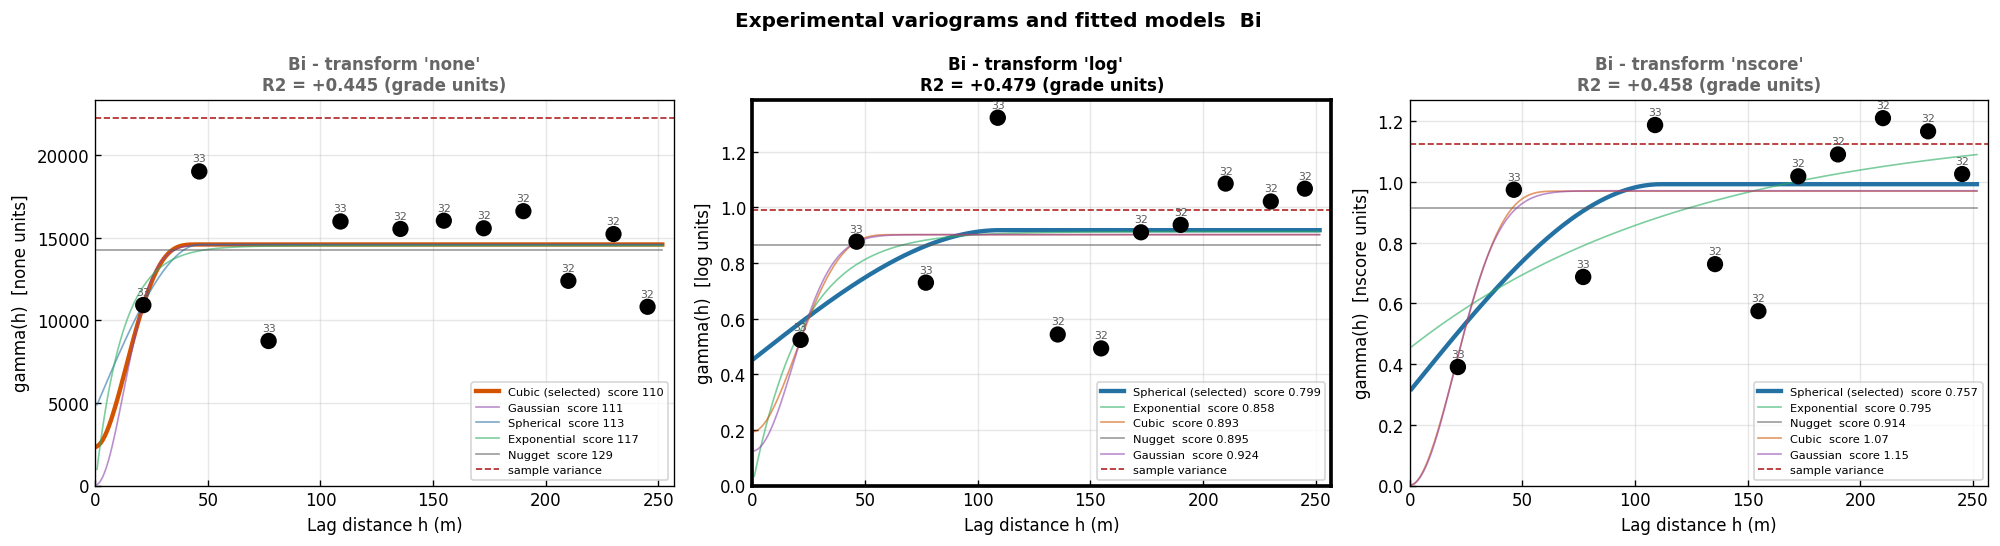

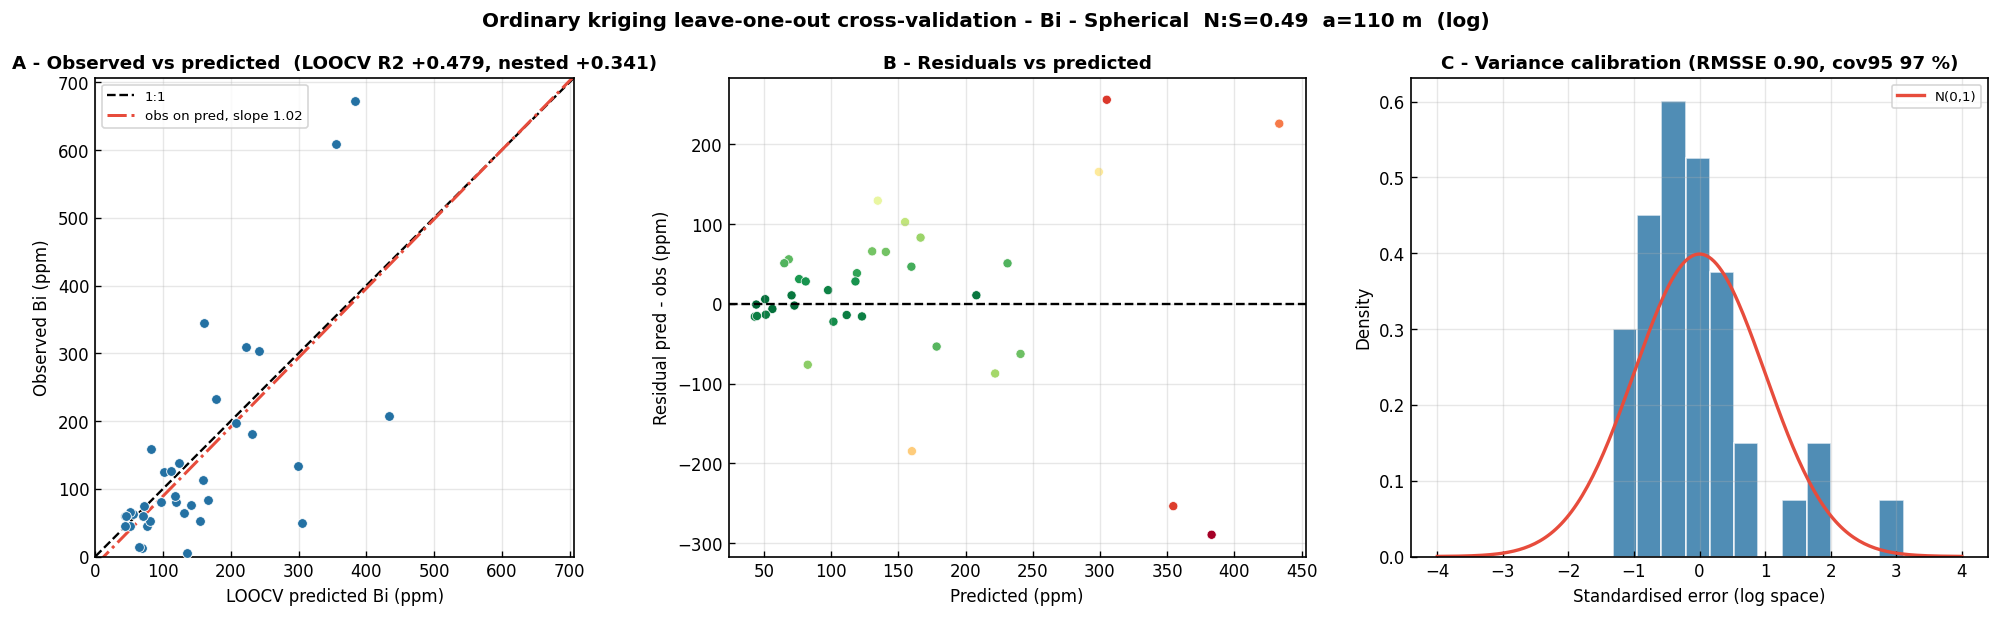

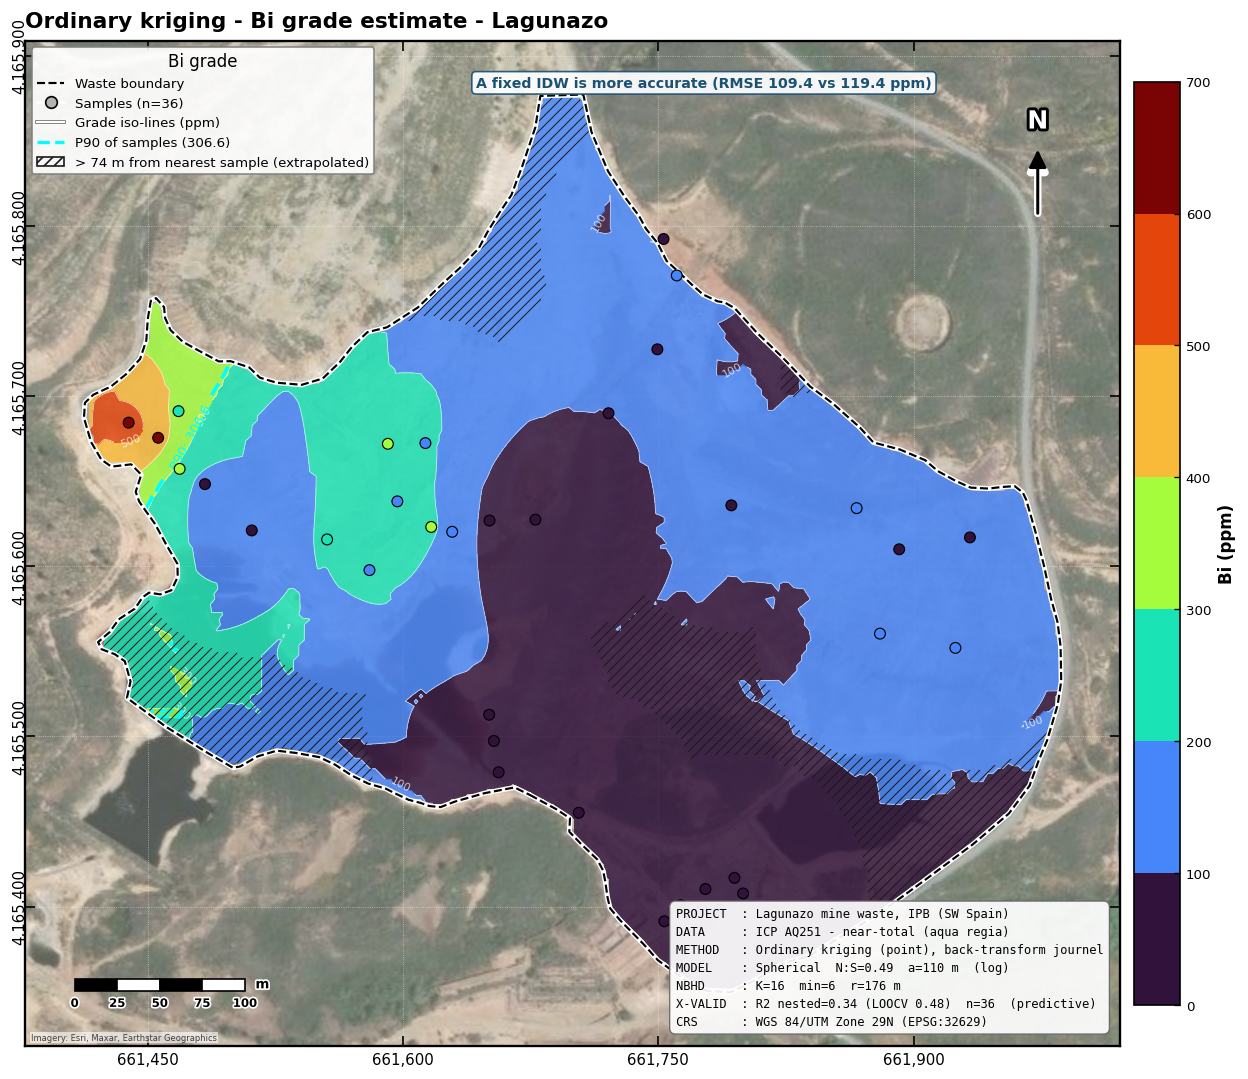

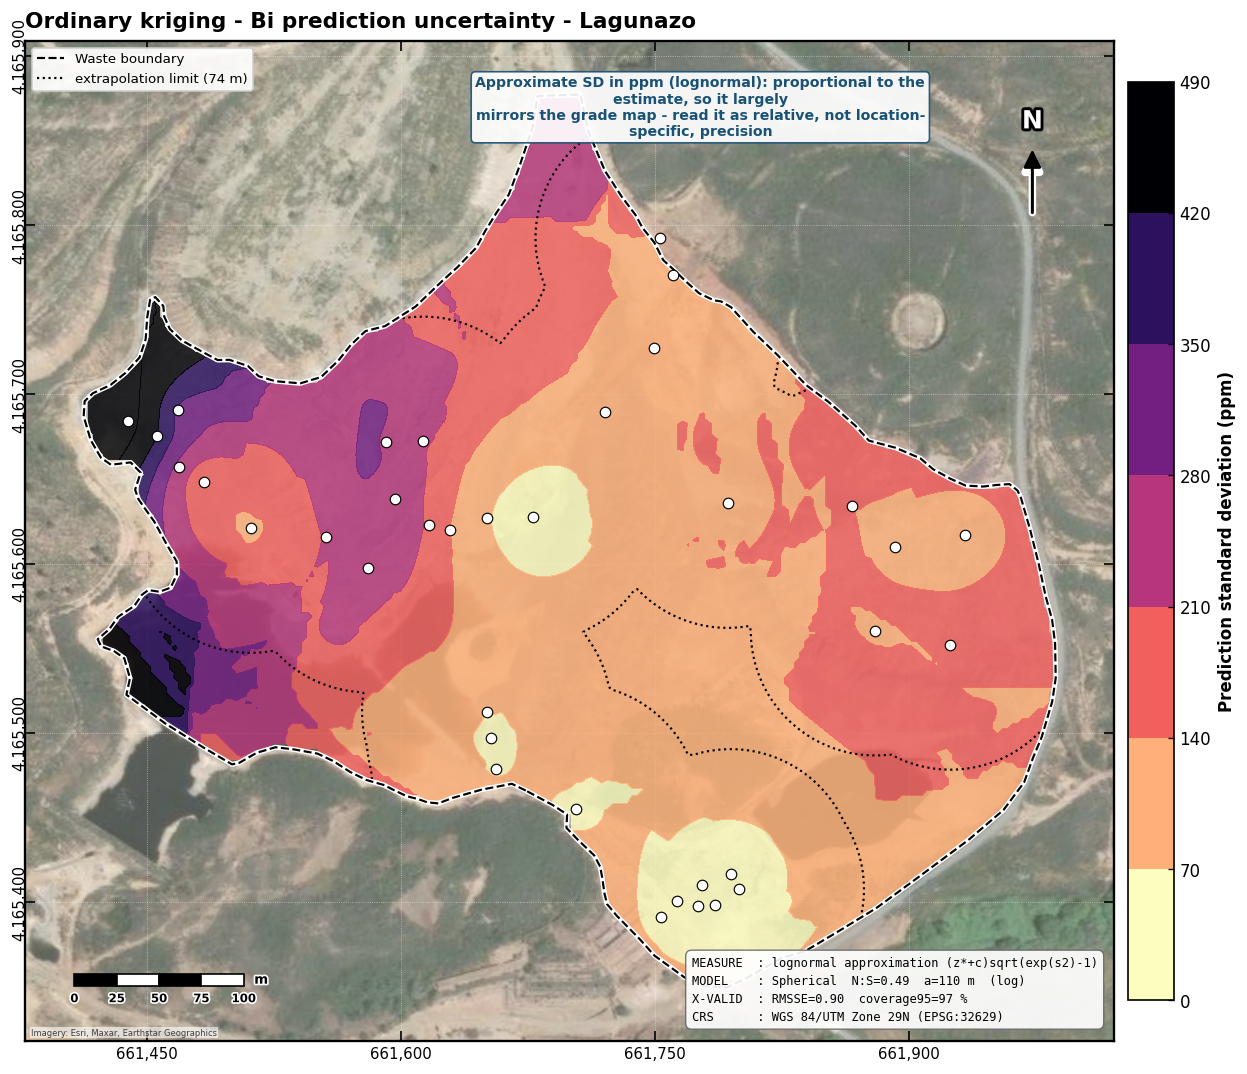

Figures saved -> results_OK_ICP\Bi/


In [22]:
d = elem_dir(VAR_NAME)
figure_variogram(VAR_NAME, os.path.join(d, f"{VAR_NAME}_variogram.png")); plt.show()
figure_cv(VAR_NAME, os.path.join(d, f"{VAR_NAME}_crossvalidation.png")); plt.show()
if VAR_NAME in SURF_ELS or True:          # the detail element is always shown as a surface, stamped if unskilled
    figure_grade_map(VAR_NAME, os.path.join(d, f"{VAR_NAME}_grade_map.png")); plt.show()
    figure_uncertainty_map(VAR_NAME, os.path.join(d, f"{VAR_NAME}_stderr_map.png")); plt.show()
print(f"Figures saved -> {d}/")

### 12.2 · All elements: figures, rasters and tables

In [23]:
_CRS_WKT = pyproj.CRS(EPSG_UTM).to_wkt(version="WKT1_ESRI")

def write_esri_ascii(path, Z2D, note, nodata=-9999.0):
    arr = np.where(np.isfinite(Z2D), Z2D, nodata)[::-1, :]
    with open(path, "w") as fh:
        fh.write(f"ncols {arr.shape[1]}\nnrows {arr.shape[0]}\n")
        fh.write(f"xllcorner {xi.min() - GRID_DENSITY_M / 2:.3f}\nyllcorner {yi.min() - GRID_DENSITY_M / 2:.3f}\n")
        fh.write(f"cellsize {GRID_DENSITY_M:.4f}\nNODATA_value {nodata}\n")
        np.savetxt(fh, arr, fmt="%.6g")
    with open(path[:-4] + ".prj", "w") as fh:
        fh.write(_CRS_WKT)
    with open(path[:-4] + "_UNITS.txt", "w") as fh:
        fh.write(note + "\n")

_t0 = time.time()
for el, f in FITS.items():
    d = elem_dir(el); S = STATIONS[el]; g = GRIDS[el]; u = unit_of(el)
    if SAVE_ELEMENT_FIGURES and el != VAR_NAME:
        plt.close(figure_variogram(el, os.path.join(d, f"{el}_variogram.png")))
        plt.close(figure_cv(el, os.path.join(d, f"{el}_crossvalidation.png")))
        if el in SURF_ELS:
            plt.close(figure_grade_map(el, os.path.join(d, f"{el}_grade_map.png")))
            plt.close(figure_uncertainty_map(el, os.path.join(d, f"{el}_stderr_map.png")))
        else:
            plt.close(figure_posted_map(el, os.path.join(d, f"{el}_posted_values_map.png")))
    _rel = reliability_class(f["r2_nested"])
    tag = {"predictive": "", "weak": "_WEAK", "no skill": "_NO-SKILL"}[_rel]
    write_esri_ascii(os.path.join(d, f"{el}_OK_grade_{u.replace('%', 'pct')}_UTM29N{tag}.asc"), g["Z"],
                     f"{el} ordinary-kriging estimate, {u}, EPSG:32629. Transform {f['transform']}, model {f['model']!r}. "
                     f"nested-CV R2 {f['r2_nested']:.3f} ({_rel})" + (" - descriptive only" if _rel == "no skill" else "")
                     + (f". {censor_line(el, S['v'])}" if censor_line(el, S["v"]) else ""))
    write_esri_ascii(os.path.join(d, f"{el}_OK_sd_{u.replace('%', 'pct')}_UTM29N{tag}.asc"), g["SD"],
                     f"{el} prediction standard deviation in {u} ({'kriging SD' if f['transform'] == 'none' else 'approximate, from the ' + f['transform'] + ' back-transform'}).")
    if f["transform"] != "none":
        write_esri_ascii(os.path.join(d, f"{el}_OK_se_{f['transform']}space_UTM29N{tag}.asc"), g["SE_fit"],
                         f"{el} kriging standard error in {f['transform']} space - NOT {u}.")
    cv = f["best"]["cv"]
    pd.DataFrame({"Sample": S["st"]["Sample"], "X_utm": S["coords"][:, 0], "Y_utm": S["coords"][:, 1],
                  f"Observed_{u}": S["v"], f"Predicted_LOOCV_{u}": f["pred_ppm"], f"Residual_{u}": f["pred_ppm"] - S["v"],
                  "Kriged_fitspace": cv["est"], "Kriging_variance_fitspace": cv["var"], "Lagrange_mu_fitspace": cv["mu"],
                  "Standardised_error": (cv["est"] - f["y"]) / np.sqrt(np.maximum(cv["var"], 1e-300)),
                  "Neighbours_used": cv["n_used"]}).to_csv(os.path.join(d, f"{el}_LOOCV_results.csv"), index=False)
    f["vgm"].to_csv(os.path.join(d, f"{el}_variogram_lags_{f['transform']}.csv"), index=False)
    pd.DataFrame([dict(transform=t, model=r["model"].name, nugget=r["model"].nugget, psill=r["model"].psill,
                       range_m=r["model"].rng, on_bound=", ".join(r["hits"]), rmse_fit=r["rmse_fit"], rmsse=r["rmsse"],
                       score=r["score"], selected=(r is a["best"]))
                  for t, a in CAND[el].items() if a["status"] == "ok" for r in a["results"]]
                 ).to_csv(os.path.join(d, f"{el}_model_fits.csv"), index=False)
print(f"Per-element outputs for {len(FITS)} elements in {time.time() - _t0:.1f} s -> {OUT_DIR}/<element>/")

Per-element outputs for 26 elements in 280.0 s -> results_OK_ICP/<element>/


## 13 · Stage 6 - Atlas, Overview and Manifest

The atlas shows a kriged surface for **every** mappable CRM (`MAP_ALL_SURFACES = True`) in station-percentile classes,
each panel labelled with its nested-CV reliability (predictive / weak / no skill); for censored elements the lowest
class is `<MDL` (grey) and the classes above it are percentiles of the detected values. CRMs with fewer than five
located detections (Be, Pd, Ta) follow as detection maps. The overview compares, per element, the kriging skill with the IDW benchmark and the pure-nugget share.

In [ ]:
els = [e for e in SUMMARY["Element"]]
ncol = 4; nrow = int(math.ceil(len(els) / ncol))
asp = (ymax_u - ymin_u + 2 * pad_y) / (xmax_u - xmin_u + 2 * pad_x)
row_h = 5.0 * asp + 1.25; fig_h = row_h * nrow + 0.9
fig, axs = plt.subplots(nrow, ncol, figsize=(5.2 * ncol, fig_h), gridspec_kw={"hspace": 0.34, "wspace": 0.10})
fig.subplots_adjust(top=1 - 0.75 / fig_h, bottom=1.1 / fig_h, left=0.03, right=0.99)
axs = np.atleast_2d(axs)
for ax, el in zip(axs.ravel(), els):
    f, g, S = FITS[el], GRIDS[el], STATIONS[el]
    br, mdl_c = crm_breaks(el, g["Z"] if el in SURF_ELS else S["v"], S["v"], "quantile")
    cmap = crm_cmap(br, mdl_c); norm = BoundaryNorm(br, cmap.N)
    rel = reliability_class(f["r2_nested"]); ncen = int(np.sum(S["v"] < META.loc[el, "mdl"] * (1 - 1e-9)))
    if el in SURF_ELS:
        draw_surface(ax, g["Z"], br, cmap, norm, S["coords"][:, 0], S["coords"][:, 1], S["v"], extrap=g["EX"],
                     iso=False, fs=0.55, dot=14)
    else:
        draw_posted(ax, br, cmap, norm, S["coords"][:, 0], S["coords"][:, 1], S["v"], fs=0.55, dot=26)
    ax.tick_params(labelsize=5.5)
    tag = (" †" if is_partial(el) else "") + (" ‡" if next(r for r in SCREEN if r["element"] == el)["n_above_UDL"] else "")
    ax.set_title(f"{el} ({unit_of(el)}){tag}", fontsize=11, fontweight="bold", loc="left", pad=3,
                 color="black" if el in SURF_ELS else "#555")
    ax.text(0.99, 1.012, f"nested R2={f['r2_nested']:.2f} {rel}  {f['model'].name}"
            + (f"  <MDL {ncen}/{len(S['v'])}" if mdl_c is not None else "") + ("" if el in SURF_ELS else " - posted"),
            transform=ax.transAxes, ha="right", va="bottom", fontsize=7.0, fontweight="bold",
            color=RELIABILITY_COLOUR[rel])
    cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, orientation="horizontal", fraction=0.046,
                      pad=0.035, boundaries=br, ticks=br, spacing="uniform", format=crm_formatter(br, mdl_c))
    cb.ax.tick_params(labelsize=6, rotation=45)
for ax in axs.ravel()[len(els):]:
    ax.axis("off")
fig.suptitle(f"Ordinary Kriging spatial mapping of CRMs ({len(els)} mapped) - Lagunazo mine waste  |  "
             "WGS 84 / UTM 29N", fontsize=15, fontweight="bold", y=1 - 0.25 / fig_h)
fig.text(0.5, 0.004, f"Each element: own transform, variogram model and LOOCV. "
         + ("Every kriged CRM is mapped; " if MAP_ALL_SURFACES else f"Kriged surface only where the nested-CV R2 >= {MIN_R2_SURFACE:g}; ")
         + f"panel labels give the nested-CV R2 and reliability: predictive (R2 >= {MIN_R2_SURFACE:g}), weak (0-{MIN_R2_SURFACE:g}), "
         f"no skill (R2 < 0, descriptive smoothing only). "
         f"Classes = station percentiles P0-10-25-50-75-90-95-100; grey lowest class = below MDL (other classes: percentiles "
         f"of the detected values). Hatching = ground farther from any sample than the "
         f"largest nearest-neighbour distance.  partial aqua-regia digestion.  value(s) above the upper reporting "
         f"limit (lower bound). Boundary: {BND_LABEL}. Basemap: Esri WorldImagery.", ha="center", va="bottom",
         fontsize=9, color="#555", style="italic", wrap=True)
plt.savefig(os.path.join(OUT_DIR, "OK_CRM_atlas_Lagunazo_ICP.png"), dpi=FIG_DPI, bbox_inches="tight")
plt.savefig(os.path.join(OUT_DIR, "OK_CRM_atlas_Lagunazo_ICP.pdf"), bbox_inches="tight")
plt.show()

### CRMs with too few detections to interpolate — detection maps

These CRM analytes were assayed at the located samples but detected in fewer than `MIN_DETECTED_N` of them (Be once,
Pd and Ta never). There is nothing to interpolate: the map shows where each was detected (red star, value labelled)
and where it was below the detection limit (open circle).

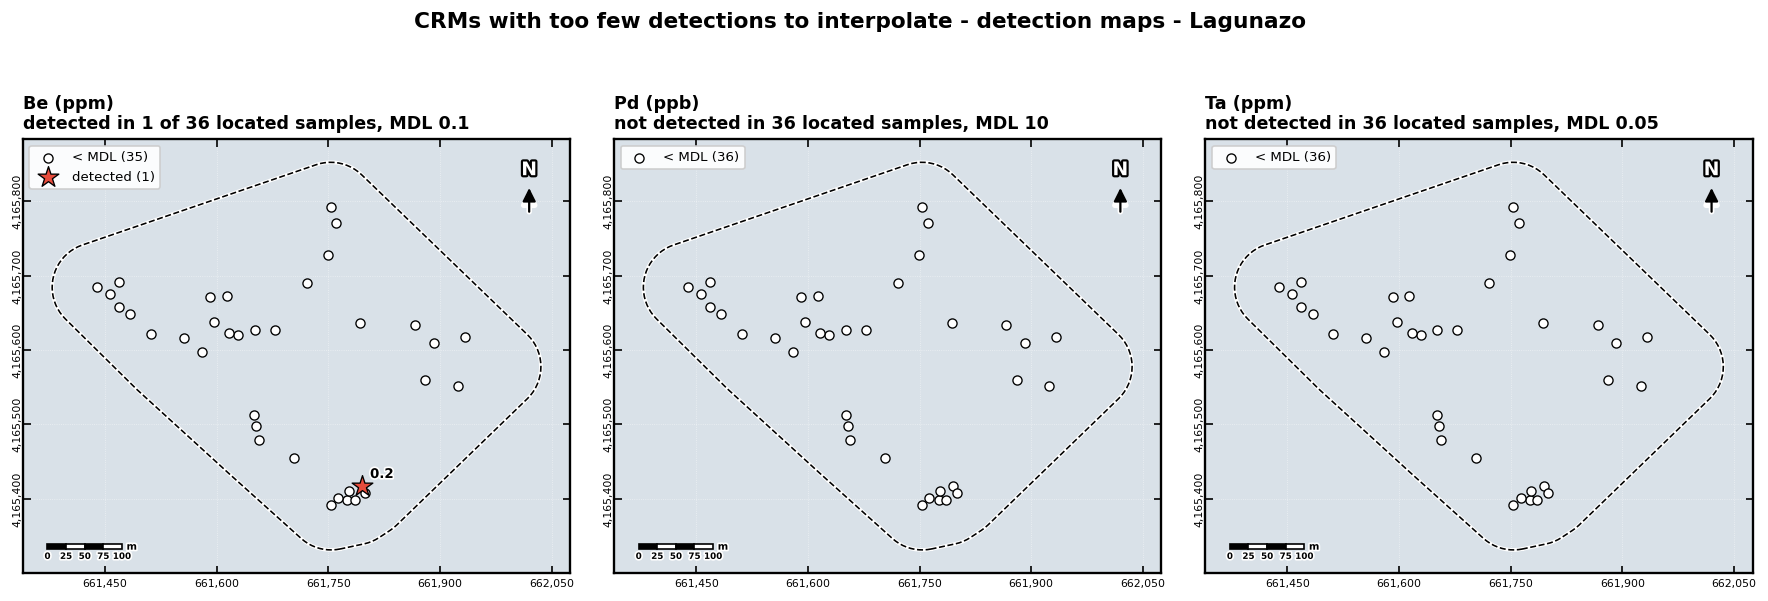

Detection maps (Be, Pd, Ta) saved -> results_OK_ICP/ICP_CRM_detection_maps_UTM29N.png


In [ ]:
if DETECTION_ONLY:
    _asp = (ymax_u - ymin_u + 2 * pad_y) / (xmax_u - xmin_u + 2 * pad_x)
    fig, axs = plt.subplots(1, len(DETECTION_ONLY), figsize=(6.2 * len(DETECTION_ONLY), 6.2 * _asp + 1.0),
                            squeeze=False, gridspec_kw={"wspace": 0.08})
    for ax, el in zip(axs[0], DETECTION_ONLY):
        f_ = RAW_FLAG.loc[has_any, el].to_numpy()[LOCATED]
        v_ = RAW_VAL.loc[has_any, el].to_numpy(float)[LOCATED]
        x_, y_ = SAMP.loc[LOCATED, "X_utm"].to_numpy(float), SAMP.loc[LOCATED, "Y_utm"].to_numpy(float)
        ana = np.isin(f_, ["ok", "bdl", "odl"])
        det = np.isin(f_, ["ok", "odl"])
        add_satellite_basemap(ax)
        ax.scatter(x_[ana & ~det], y_[ana & ~det], s=30, facecolors="white", edgecolors="black", linewidths=0.8,
                   zorder=11, label=f"< MDL ({int((ana & ~det).sum())})")
        if det.any():
            ax.scatter(x_[det], y_[det], s=170, marker="*", c="#e74c3c", edgecolors="black", linewidths=0.8,
                       zorder=12, label=f"detected ({int(det.sum())})")
            for xx, yy, vv in zip(x_[det], y_[det], v_[det]):
                ax.annotate(fmt_num(vv), (xx, yy), xytext=(5, 5), textcoords="offset points", fontsize=8,
                            fontweight="bold", zorder=13, path_effects=[mpe.withStroke(linewidth=2, foreground="white")])
        add_map_furniture(ax, fs=0.75)
        ax.tick_params(labelsize=6.5)
        mdl_ = META.loc[el, "mdl"]
        ax.set_title(f"{el} ({unit_of(el)})\n" + (f"detected in {int(det.sum())} of {int(ana.sum())} located samples"
                     if det.any() else f"not detected in {int(ana.sum())} located samples")
                     + f", MDL {fmt_num(mdl_)}", fontsize=10.5, fontweight="bold", loc="left")
        ax.legend(loc="upper left", fontsize=8, framealpha=0.92)
    fig.suptitle("CRMs with too few detections to interpolate - detection maps - Lagunazo", fontsize=13,
                 fontweight="bold")
    plt.savefig(DETECTION_MAP_PNG, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Detection maps ({', '.join(DETECTION_ONLY)}) saved -> {DETECTION_MAP_PNG}")
else:
    print("Every assayed CRM analyte has enough detections to be interpolated.")

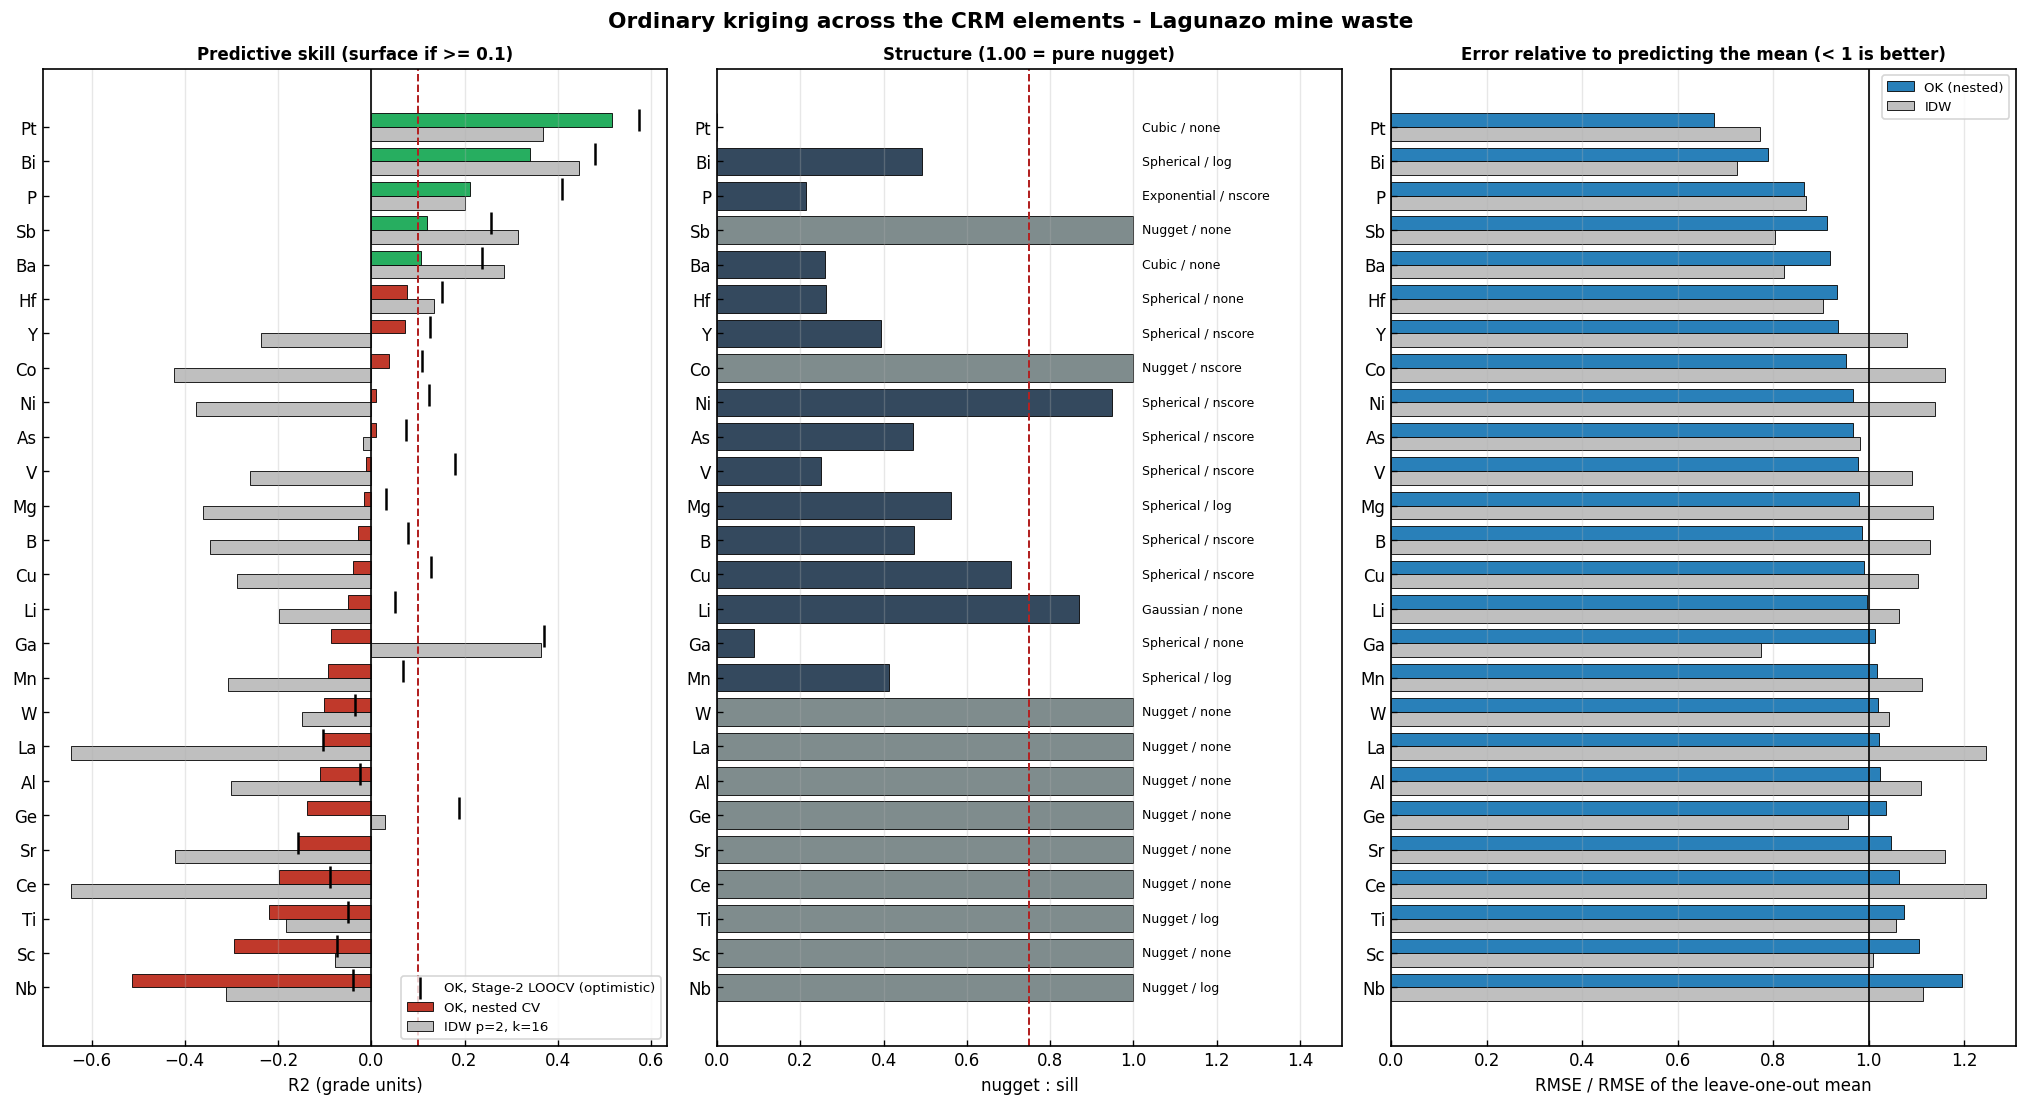

In [ ]:
s = SUMMARY.sort_values("R2 nested")
fig, axes = plt.subplots(1, 3, figsize=(17, max(4.8, 0.36 * len(s))))
ax = axes[0]
yy = np.arange(len(s))
ax.barh(yy + 0.2, s["R2 nested"], height=0.4, color=np.where(s["R2 nested"] >= MIN_R2_SURFACE, "#27ae60", "#c0392b"),
        edgecolor="black", lw=0.5, label="OK, nested CV")
ax.scatter(s["R2"], yy + 0.2, marker="|", s=160, color="black", zorder=5, label="OK, Stage-2 LOOCV (optimistic)")
ax.barh(yy - 0.2, s["R2 IDW"], height=0.4, color="0.75", edgecolor="black", lw=0.5, label="IDW p=2, k=16")
ax.axvline(0, color="black", lw=1.0); ax.axvline(MIN_R2_SURFACE, color="firebrick", ls="--", lw=1.2)
ax.set_yticks(yy, s["Element"]); ax.set_xlabel("R2 (grade units)")
ax.set_title(f"Predictive skill (surface if >= {MIN_R2_SURFACE:g})", fontsize=10, fontweight="bold")
ax.legend(fontsize=8, loc="lower right"); ax.grid(axis="x", alpha=0.3)
ax = axes[1]
ax.barh(yy, s["N:S"], color=np.where(s["Model"] == "Nugget", "#7f8c8d", "#34495e"), edgecolor="black", lw=0.5)
ax.axvline(0.75, color="firebrick", ls="--", lw=1.2)
for i, (m_, t_) in enumerate(zip(s["Model"], s["Transform"])):
    ax.text(1.02, i, f"{m_} / {t_}", va="center", fontsize=7.5)
ax.set_yticks(yy, s["Element"]); ax.set_xlim(0, 1.5); ax.set_xlabel("nugget : sill")
ax.set_title("Structure (1.00 = pure nugget)", fontsize=10, fontweight="bold"); ax.grid(axis="x", alpha=0.3)
ax = axes[2]
ax.barh(yy + 0.2, s["RMSE nested"] / s["RMSE LOO-mean"], height=0.4, color="#2980b9", edgecolor="black", lw=0.5,
        label="OK (nested)")
ax.barh(yy - 0.2, s["RMSE IDW p2 k16"] / s["RMSE LOO-mean"], height=0.4, color="0.75", edgecolor="black", lw=0.5,
        label="IDW")
ax.axvline(1.0, color="black", lw=1.0)
ax.set_yticks(yy, s["Element"]); ax.set_xlabel("RMSE / RMSE of the leave-one-out mean")
ax.set_title("Error relative to predicting the mean (< 1 is better)", fontsize=10, fontweight="bold")
ax.legend(fontsize=8); ax.grid(axis="x", alpha=0.3)
fig.suptitle("Ordinary kriging across the CRM elements - Lagunazo mine waste ", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "OK_overview_all_elements.png"), dpi=FIG_DPI, bbox_inches="tight")
plt.show()

In [ ]:
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

SCREEN_DF.to_csv(os.path.join(OUT_DIR, "screening.csv"), index=False)
TRIALS_DF.to_csv(os.path.join(OUT_DIR, "transform_trials.csv"), index=False)
SUMMARY.to_csv(os.path.join(OUT_DIR, "summary_all_elements.csv"), index=False)
AUDIT_TBL.to_csv(os.path.join(OUT_DIR, f"audit_{VAR_NAME}.csv"), index=False)

grid_tab = pd.DataFrame({"Easting_m": XG.ravel()[INSIDE], "Northing_m": YG.ravel()[INSIDE]})
for el in SURF_ELS:
    grid_tab[f"{el}_OK_{unit_of(el)}"] = GRIDS[el]["Z"].ravel()[INSIDE]
    grid_tab[f"{el}_SD_{unit_of(el)}"] = GRIDS[el]["SD"].ravel()[INSIDE]

OUTPUT_XLS = os.path.join(OUT_DIR, "OK_ICP_Lagunazo_CRM_Analysis.xlsx")
sheets = [("CRM_Identification", CRM_TABLE), ("CRM_Elements", CRM_ELEMENTS), ("CRM_Not_Covered", CRM_NOT_COVERED),
          ("Digestion_Check", DIGESTION_CHECK), ("QC_Pulp_Duplicate", QC_DUP), ("QC_Standards", QC_STD),
          ("Sample_Reconciliation", SAMP.drop(columns=["_key"])), ("Screening", SCREEN_DF),
          ("Transform_Trials", TRIALS_DF), ("Summary", SUMMARY), (f"Audit_{VAR_NAME}", AUDIT_TBL),
          ("Grid_Surfaces", grid_tab)]
with pd.ExcelWriter(OUTPUT_XLS, engine="openpyxl") as xw:
    for name, df_ in sheets:
        df_.to_excel(xw, sheet_name=name[:31], index=False)
    for ws in xw.book.worksheets:
        for c in ws[1]:
            c.fill = PatternFill("solid", fgColor="1A5276"); c.font = Font(bold=True, color="FFFFFF", size=10)
            c.alignment = Alignment(horizontal="center", wrap_text=True)
        for col in ws.iter_cols(min_row=1, max_row=min(ws.max_row, 200)):
            ws.column_dimensions[get_column_letter(col[0].column)].width = min(max(
                max(len(str(c.value)) if c.value is not None else 0 for c in col) + 2, 8), 40)
        ws.freeze_panes = "A2"

def _sha(p):
    h = hashlib.sha256()
    with open(p, "rb") as fh:
        h.update(fh.read())
    return h.hexdigest()

MANIFEST = dict(
    notebook="OK_ICP_Lagunazo_CRM.ipynb", run_started_utc=RUN_STARTED,
    run_finished_utc=datetime.now(timezone.utc).isoformat(timespec="seconds"),
    environment=dict(python=platform.python_version(), platform=platform.platform(), numpy=np.__version__,
                     pandas=pd.__version__, scipy=scipy.__version__, matplotlib=matplotlib.__version__,
                     pyproj=pyproj.__version__, shapely=getattr(shapely, "__version__", "not installed"),
                     contextily=getattr(ctx, "__version__", "not installed")),
    inputs={p: (_sha(p) if Path(p).exists() else "missing") for p in (ICP_XLSX, KMZ_FILE)},
    boundary=BND_LABEL,
    config=dict(ELEMENTS=str(ELEMENTS), VAR_NAME=VAR_NAME, BDL_FACTOR=BDL_FACTOR, ODL_FACTOR=ODL_FACTOR,
                STATION_TOL_M=STATION_TOL_M, TRANSFORM_CANDIDATES=TRANSFORM_CANDIDATES,
                TRANSFORM_MIN_GAIN_PCT=TRANSFORM_MIN_GAIN_PCT, LOG_BACKTRANSFORM=LOG_BACKTRANSFORM,
                NSCORE_BACKTRANSFORM=NSCORE_BACKTRANSFORM, N_LAGS_MAX=N_LAGS_MAX, MIN_PAIRS_LAG=MIN_PAIRS_LAG,
                CUTOFF_FACTOR=CUTOFF_FACTOR, RMSSE_PENALTY=RMSSE_PENALTY, SELECTION_TOL_PCT=SELECTION_TOL_PCT,
                K_NEIGHBORS=K_NEIGHBORS, MIN_NEIGHBORS=MIN_NEIGHBORS, SEARCH_RADIUS_FACTOR=SEARCH_RADIUS_FACTOR,
                GRID_DENSITY_M=GRID_DENSITY_M, MIN_R2_SURFACE=MIN_R2_SURFACE),
    grid=dict(ncols=int(NCOL), nrows=int(NROW), cellsize_m=GRID_DENSITY_M, nodes_in_domain=int(INSIDE.sum()),
              xllcorner=float(xi.min() - GRID_DENSITY_M / 2), yllcorner=float(yi.min() - GRID_DENSITY_M / 2)),
    elements_admitted=ADMITTED, elements_rejected=dict(REJECTED), elements_failed_stage2=STAGE2_FAILED,
    surfaces=SURF_ELS, posted_values=POST_ELS, detection_maps_only=DETECTION_ONLY,
    reliability={r["Element"]: r["Reliability"] for _, r in SUMMARY.iterrows()},
    results={r["Element"]: {k: (None if isinstance(v_, float) and not np.isfinite(v_) else
                                (v_.item() if hasattr(v_, "item") else v_)) for k, v_ in r.items()}
             for r in SUMMARY.to_dict(orient="records")})
with open(os.path.join(OUT_DIR, "run_manifest.json"), "w") as fh:
    json.dump(MANIFEST, fh, indent=2, default=str)

print("=" * 72)
print("  ORDINARY KRIGING COMPLETE - Lagunazo ICP (EU CRMA 2024)")
print("=" * 72)
print(f"  Samples        : {int(LOCATED.sum())} located; boundary = {BND_LABEL}")
print(f"  CRM identified : " + ", ".join(CRM_ELEMENTS.loc[CRM_ELEMENTS['Status'] == 'identified', 'Element']))
print(f"  Kriged         : {len(FITS)} elements")
print(f"  Surfaces       : {len(SURF_ELS)} CRMs")
for _rel in ("predictive", "weak", "no skill"):
    _e = SUMMARY.loc[SUMMARY["Reliability"] == _rel, "Element"].tolist()
    print(f"    {_rel:10s}   : " + (", ".join(f"{e} ({FITS[e]['r2_nested']:+.2f})" for e in _e) or "-"))
if POST_ELS:
    print(f"  Posted values  : " + ", ".join(POST_ELS) + f"  (nested R2 < {MIN_R2_SURFACE:g})")
print(f"  Detection maps : " + (", ".join(DETECTION_ONLY) or "none") + f"  (< {MIN_DETECTED_N} located detections)")
print(f"  Audit ({VAR_NAME})   : {int((AUDIT_TBL['Status'] == 'PASS').sum())} PASS / "
      f"{int((AUDIT_TBL['Status'] == 'WARN').sum())} WARN / {int((AUDIT_TBL['Status'] == 'INFO').sum())} INFO / 0 FAIL")
print(f"  Outputs        : {OUT_DIR}/ (per-element folders, atlas, overview, workbook, manifest)")
print("=" * 72)

  ORDINARY KRIGING COMPLETE - Lagunazo ICP (EU CRMA 2024)
  Samples        : 40 located; boundary = 60 m buffered hull
  CRM identified : Al, Sb, As, Ba, Be, Bi, B, Co, Cu, Ga, Ge, Hf, Y, La, Ce, Li, Mg, Mn, Ni, Nb, P, Pd, Pt, Sc, Si, Sr, Ti, W, V
  Kriged         : 26 elements
  Surfaces       : 26 CRMs
    predictive   : Pt (+0.52), Bi (+0.34), P (+0.21), Sb (+0.12), Ba (+0.11)
    weak         : Hf (+0.08), Y (+0.07), Co (+0.04), Ni (+0.01), As (+0.01)
    no skill     : V (-0.01), Mg (-0.02), B (-0.03), Cu (-0.04), Li (-0.05), Ga (-0.09), Mn (-0.09), W (-0.10), La (-0.10), Al (-0.11), Ge (-0.14), Sr (-0.16), Ce (-0.20), Ti (-0.22), Sc (-0.30), Nb (-0.51)
  Detection maps : Be, Pd, Ta  (< 5 located detections)
  Audit (Bi)   : 22 PASS / 2 WARN / 3 INFO / 0 FAIL
  Outputs        : results_OK_ICP/ (per-element folders, atlas, overview, workbook, manifest)
